# Admission metabolic factors and futile recanalisation after thrombectomy: replication notebook

**Author:** Max Brzezicki, Department of Neural Engineering and Space Medicine, University of Zielona Góra.

The notebook contains the complete analysis and needs no other code. It reads two patient-level files, `data/source_registry.ods` and `data/rehabilitation_outcomes.ods`, which are not distributed in the public repository (see `data/README.md`); with them in place it reproduces every number reported in the manuscript and in the Supplementary Information, writes all tables to `outputs/results/` and all figures (1 to 5, S1 to S5) to `outputs/figs/`, and registers every reported value in `outputs/results/results_manifest.json`. The SHA-256 of both data files is recorded in the manifest. One fixed seed (20260719) governs every stochastic step. The cross-validation of section 11, with the screens repeated in every training fold, its bootstrap and its permutation test, takes about 33 minutes on two cores; the rest runs in about two minutes. Binary outcomes are modelled by Firth penalised likelihood; the point estimate, the profile penalised-likelihood 95% CI and the penalised likelihood-ratio p value of each term are derived from the same likelihood, so an interval that excludes 1 always corresponds to p < 0.05 and vice versa. The proportional-odds model, its Brant test and the unpenalised comparison in section 6 use maximum likelihood with Wald intervals. Package versions are pinned in `requirements.txt`.

## 1. Constants, cohort construction and the estimation engine

In [1]:
# Core deterministic analyses for the replication notebook. Author: Max Brzezicki.
import numpy as np, pandas as pd, scipy.stats as st
from scipy.optimize import brentq
from scipy.stats import chi2

SEED = 20260719
ADJ = ["Age", "NIHSS_admission", "mTICI3", "onset_to_recan_h"]
CONT = ["Age", "NIHSS_admission", "onset_to_recan_h", "NLR", "SII", "SIRI", "PLR", "MLR",
        "WBC", "NEU", "LYM", "MONO", "CRP", "RDW", "MPV", "HGB", "HCT", "RBC", "INR", "APTT",
        "Sodium", "Potassium", "Urea", "Creatinine", "TotalChol", "HDL", "LDL",
        "Triglycerides", "Glucose", "GPR"]
BIN = ["Female", "HTN", "AF", "Diabetes", "ICA_involvement", "Tandem", "IVtPA", "FirstPass", "mTICI3"]
LAB18 = ["NLR", "SII", "SIRI", "PLR", "MLR", "WBC", "NEU", "MONO", "PLT", "CRP", "RDW", "MPV",
         "HGB", "INR", "Sodium", "Urea", "Creatinine", "LDL"]
EXPO = "Glucose_mmol"   # exposure for the association models: admission glucose, per mmol/l
INFL9 = ["NLR", "SII", "SIRI", "PLR", "MLR", "WBC", "CRP", "RDW", "MPV"]
BLOCKS = [("+ sex", ["Female"]),
          ("+ comorbidity (HTN, AF, diabetes)", ["HTN", "AF", "Diabetes"]),
          ("+ ICA involvement, tandem", ["ICA_involvement", "Tandem"]),
          ("+ procedure (first pass, IV thrombolysis)", ["FirstPass", "IVtPA"]),
          ("+ renal / electrolyte (Na, urea, creatinine)", ["Sodium", "Urea", "Creatinine"]),
          ("+ lipids (LDL, HDL, triglycerides)", ["LDL", "HDL", "Triglycerides"]),
          ("+ haemoglobin, INR", ["HGB", "INR"]),
          ("+ inflammatory (NLR, CRP, WBC)", ["NLR", "CRP", "WBC"])]


def fmt(x, d=0):
    """Round half away from zero (conventional rounding), as text with d decimals and a true minus sign."""
    from decimal import Decimal, ROUND_HALF_UP
    q = Decimal(1).scaleb(-d)
    s = str(Decimal(repr(float(x))).quantize(q, rounding=ROUND_HALF_UP))
    if s.lstrip("-").strip("0.") == "":
        s = s.lstrip("-")
    return s.replace("-", "\u2212")


def _hhmm(s):
    t = pd.to_datetime(s, format="%H:%M:%S", errors="coerce")
    return t.dt.hour * 60 + t.dt.minute


def load_cohort(path):
    raw = pd.read_excel(path, sheet_name="Data", engine="odf")
    n_screened = len(raw)
    num = lambda c: pd.to_numeric(raw[c], errors="coerce")
    d = pd.DataFrame(index=raw.index)
    d["mtici"] = raw["mTICI post-procedure"].astype(str).str.strip().str.lower()
    d["anterior"] = raw["Occlusion location"].astype(str).str.contains("MCA|ICA", case=False, na=False)
    d["Age"] = num("Age"); d["premorbid_mRS"] = num("mRS (1)")
    d["NIHSS_admission"] = num("NIHSS (1)")
    d["NIHSS_discharge"] = pd.to_numeric(raw["NIHSS (2)"], errors="coerce")
    d["in_hospital_death"] = num("In-hospital death").fillna(0)
    d["Female"] = (raw["Sex"].astype(str) == "F").astype(int)
    for src, dst in [("HTN (hypertension)", "HTN"), ("AF (atrial fibrillation)", "AF"),
                     ("DM (diabetes)", "Diabetes"), ("Tandem", "Tandem"), ("IV tPA", "IVtPA"),
                     ("Intracranial hemorrhage", "ICH")]:
        d[dst] = num(src)
    d["FirstPass"] = pd.to_numeric(raw["First pass"], errors="coerce")
    d["ICA_involvement"] = raw["Occlusion location"].astype(str).str.contains("ICA").astype(int)
    diff = _hhmm(raw["Recanalization time"]) - _hhmm(raw["Symptom onset time"])
    d["onset_to_recan_h"] = np.where(diff < 0, diff + 1440, diff) / 60.0
    labs = {"WBC": "WBC (10^3/\u00b5l)", "NEU": "NEU (10^3/\u00b5l)", "LYM": "LYM (10^3/\u00b5l)",
            "MONO": "MONO (10^3/\u00b5l)", "PLT": "PLT (10^3/\u00b5l)", "CRP": "CRP (mg/l)",
            "RDW": "RDW (%)", "MPV": "MPV (fl)", "HGB": "HGB (g/dl)", "HCT": "HCT (%)",
            "RBC": "RBC (10^6/\u00b5l)", "INR": "INR", "APTT": "APTT (s)", "Sodium": "Sodium (mmol/l)",
            "Potassium": "Potassium (mmol/l)", "Urea": "Urea nitrogen (mg/dl)",
            "Creatinine": "Creatinine (mg/dl)", "TotalChol": "Total cholesterol (mg/dl)",
            "HDL": "HDL (mg/dl)", "LDL": "LDL (mg/dl)", "Triglycerides": "Triglycerides (mg/dl)",
            "Glucose": "Glucose (mg/dl)"}
    for dst, src in labs.items():
        d[dst] = num(src)
    d["NLR"] = d.NEU / d.LYM; d["SII"] = d.PLT * d.NEU / d.LYM
    d["SIRI"] = d.NEU * d.MONO / d.LYM; d["PLR"] = d.PLT / d.LYM; d["MLR"] = d.MONO / d.LYM
    d["GPR"] = (d.Glucose / 18.0) / d.Potassium
    d["mRS_90d"] = num("FU 3mo mRS"); d["mRS_12m"] = num("FU 12mo mRS")
    d["mTICI3"] = (d.mtici == "3").astype(int)
    flow = [("screened", n_screened)]
    d = d[d.mtici.isin(["2b", "2c", "3"])]; flow.append(("successful reperfusion (mTICI 2b/2c/3)", len(d)))
    d = d[d.anterior]; flow.append(("anterior circulation occlusion", len(d)))
    d = d[d.premorbid_mRS <= 2]; flow.append(("premorbid mRS 0-2 documented", len(d)))
    d = d.reset_index(drop=True)
    d["fENI"] = np.where(d.in_hospital_death == 1, 1.0,
                         np.where(d.NIHSS_discharge.notna(),
                                  ((d.NIHSS_admission - d.NIHSS_discharge) < 4).astype(float), np.nan))
    d["poor_mRS_90d"] = np.where(d.mRS_90d.notna(), (d.mRS_90d >= 3).astype(float), np.nan)
    d["log2_Glucose"] = np.log2(d.Glucose)
    d["Glucose_mmol"] = d.Glucose / 18.0
    return d, pd.DataFrame(flow, columns=["step", "n"])


# ---------------- Firth engine (estimate, profile CI and p from one likelihood) -------------
def _pll(b, X, y):
    eta = np.clip(X @ b, -30, 30)
    p = 1 / (1 + np.exp(-eta)); W = np.clip(p * (1 - p), 1e-12, None)
    _, logdet = np.linalg.slogdet(X.T @ (X * W[:, None]) + np.eye(X.shape[1]) * 1e-12)
    return np.sum(y * eta - np.logaddexp(0, eta)) + 0.5 * logdet


FIRTH_LOG = {"fits": 0, "max_score": 0.0}   # convergence of every unrestricted Firth fit


def firth_fit(X, y, profile_j=None, fixed=None, b0=None, max_iter=1000, tol=1e-10):
    n, k = X.shape
    free = [j for j in range(k) if j != profile_j]
    b = np.zeros(k) if b0 is None else b0.copy()
    if profile_j is not None:
        b[profile_j] = fixed
    cur = _pll(b, X, y)
    for _ in range(max_iter):
        eta = np.clip(X @ b, -30, 30)
        p = 1 / (1 + np.exp(-eta)); W = np.clip(p * (1 - p), 1e-12, None)
        XW = X * W[:, None]; I = X.T @ XW + np.eye(k) * 1e-12
        Iinv = np.linalg.inv(I)
        H = (XW @ Iinv * X).sum(1)
        U = X.T @ (y - p + H * (0.5 - p))
        step = np.linalg.solve(I[np.ix_(free, free)], U[free])
        m = np.max(np.abs(step))
        if m > 5:
            step = step * 5 / m
        lam, nxt = 1.0, None
        for _ in range(40):
            cand = b.copy(); cand[free] = b[free] + lam * step
            val = _pll(cand, X, y)
            if val >= cur - 1e-12:
                nxt, cur = cand, val; break
            lam /= 2
        if nxt is None:
            break
        moved = np.max(np.abs(nxt - b)); b = nxt
        if moved < tol:
            break
    eta = np.clip(X @ b, -30, 30)
    p = 1 / (1 + np.exp(-eta)); W = np.clip(p * (1 - p), 1e-12, None)
    I = X.T @ (X * W[:, None]) + np.eye(k) * 1e-12
    if profile_j is None:
        # convergence check: largest absolute modified (Firth) score at the solution
        H = ((X * W[:, None]) @ np.linalg.inv(I) * X).sum(1)
        g = float(np.max(np.abs(X.T @ (y - p + H * (0.5 - p)))))
        FIRTH_LOG["fits"] += 1; FIRTH_LOG["max_score"] = max(FIRTH_LOG["max_score"], g)
    return b, _pll(b, X, y), np.linalg.inv(I)


def firth_term(df, outcome, term_col, covar_cols, scale_term=True, ci=True, covar_ready=None):
    """Fit outcome ~ term + covariates (Firth). covar_ready columns enter as they are;
    covar_cols are standardised within the fitting set. The term is standardised only
    when scale_term (otherwise centred). Returns OR, profile CI, dual p, n, events, k."""
    ready = covar_ready or []
    cols = [outcome, term_col] + covar_cols + ready
    sub = df.dropna(subset=cols)
    y = sub[outcome].to_numpy(float)
    mats = [sub[c].astype(float).to_numpy() for c in ready]
    for c in covar_cols:
        v = sub[c].astype(float)
        if c in CONT:
            v = (v - v.mean()) / v.std(ddof=0)
        mats.append(v.to_numpy())
    t = sub[term_col].astype(float)
    t = (t - t.mean()) / t.std(ddof=0) if scale_term else t - t.mean()
    X = np.column_stack([np.ones(len(sub)), t.to_numpy()] + mats)
    b, pll, cov = firth_fit(X, y); j = 1
    _, pll0, _ = firth_fit(X, y, profile_j=j, fixed=0.0, b0=b)
    p = float(chi2.sf(max(2 * (pll - pll0), 0.0), 1))
    out = {"OR": float(np.exp(b[j])), "p": p, "n": int(len(sub)), "events": int(y.sum()),
           "k_params": X.shape[1], "EPV": float(min(y.sum(), len(y) - y.sum()) / X.shape[1]), "beta": float(b[j])}
    if ci:
        target = pll - chi2.ppf(0.95, 1) / 2
        prof = lambda beta: firth_fit(X, y, profile_j=j, fixed=beta, b0=b)[1] - target
        lo_a = b[j]
        while prof(lo_a - 0.5) > 0 and lo_a > b[j] - 40:
            lo_a -= 0.5
        hi_a = b[j]
        while prof(hi_a + 0.5) > 0 and hi_a < b[j] + 40:
            hi_a += 0.5
        out["CI_low"] = float(np.exp(brentq(prof, lo_a - 0.5, b[j], xtol=1e-6)))
        out["CI_high"] = float(np.exp(brentq(prof, b[j], hi_a + 0.5, xtol=1e-6)))
    return out


def term_column(d, f, scales):
    """Analysis column and scale label for factor f."""
    if f in BIN:
        return d[f], "binary", False
    if scales.loc[f, "scale"] == "log":
        return np.log(d[f]), "per SD (log)", True
    return d[f], "per SD (linear)", True


def prepare_frames(d, scales):
    """One analysis frame for both outcomes: analysis-scale factor columns (log where
    flagged) standardised on the full analysed cohort, before any listwise deletion."""
    dd = d.copy()
    extra = [f for f in LAB18 if f not in CONT]  # PLT: in the prediction panel, not screened
    for f in CONT + extra:
        if f in CONT:
            use_log = scales.loc[f, "scale"] == "log"
        else:
            use_log = abs(float(st.skew(d[f].dropna()))) > 1
        v = np.log(d[f]) if use_log else d[f].astype(float)
        dd["z_" + f] = (v - v.mean()) / v.std(ddof=0)
    return {"fENI": dd, "poor_mRS_90d": dd}


def exposure_models_cc(dd, outcome):
    """Complete-case rows of Supplementary Table S14: glucose per mmol/l under the model ladder."""
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    ladder = [("unadjusted", []), ("prespecified adjustment set", zadj),
              ("adjusted + Diabetes", zadj + ["Diabetes"]), ("adjusted + IVtPA", zadj + ["IVtPA"]),
              ("adjusted + ICA_involvement", zadj + ["ICA_involvement"]),
              ("adjusted + Diabetes + IVtPA + ICA_involvement", zadj + ["Diabetes", "IVtPA", "ICA_involvement"]),
              ("adjusted + ICH (mediator check)", zadj + ["ICH"])]
    rows = []
    for name, cov in ladder:
        r = firth_term(dd, outcome, EXPO, [], scale_term=False, covar_ready=cov)
        r["model"] = name
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")


def progressive(dd, outcome):
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    z = lambda cols: ["z_" + c if c in CONT else c for c in cols]
    rows = []
    steps = [("prespecified set", zadj)] + [(n, zadj + z(c)) for n, c in BLOCKS]
    steps.append(("+ all blocks jointly", zadj + z([c for _, cc in BLOCKS for c in cc])))
    # every model refitted on one common sample, complete for every block, so that a change in the
    # glucose estimate cannot arise from a change in the patients analysed
    common = dd.dropna(subset=[outcome, EXPO] + steps[-1][1])
    for name, cov in steps:
        r = firth_term(dd, outcome, EXPO, [], scale_term=False, covar_ready=cov)
        rc = firth_term(common, outcome, EXPO, [], scale_term=False, covar_ready=cov)
        r.update({f"{k}_cs": rc[k] for k in ("OR", "CI_low", "CI_high", "p", "n", "events", "EPV")})
        r["adjustment"] = name
        # events per parameter on the less frequent outcome class, intercept included
        r["flag"] = "exploratory (EPV < 5)" if r["EPV"] < 5 else ""
        r["flag_cs"] = "exploratory (EPV < 5)" if r["EPV_cs"] < 5 else ""
        rows.append(r)
    return pd.DataFrame(rows).set_index("adjustment")


def subgroups_interactions(dd, outcome):
    sg, it = [], []
    for modf in ("Diabetes", "mTICI3", "IVtPA"):
        adj = ["z_" + a if a in CONT else a for a in ADJ if a != modf]
        for lev in (0, 1):
            r = firth_term(dd[dd[modf] == lev], outcome, EXPO, [], scale_term=False, covar_ready=adj)
            r["modifier"], r["level"] = modf, lev
            r["flag"] = "exploratory (EPV < 5)" if r["EPV"] < 5 else ""
            sg.append(r)
        sub = dd.assign(_int=(dd[EXPO] - dd[EXPO].mean()) * dd[modf])
        r = firth_term(sub, outcome, "_int", [], scale_term=False,
                       covar_ready=adj + [modf, EXPO], ci=False)
        it.append({"modifier": modf, "p_interaction": r["p"],
                   "decision": "stratified estimates primary" if r["p"] < 0.05 else "pooled estimate primary"})
    return pd.DataFrame(sg), pd.DataFrame(it)


def brant_test(sub, col, xcols):
    """Brant (1990) test of the proportional-odds assumption: maximum-likelihood binary logits at each
    cut point and Wald tests that each slope is equal across cut points (per variable, J - 1 df, where
    J is the number of cut points; omnibus, (J - 1) x k df). The joint covariance of the cut-specific
    estimates is the sandwich of their stacked score equations, which stays positive semi-definite
    when a category is sparse."""
    import statsmodels.api as sm
    yv = sub[col].astype(int).to_numpy()
    X = sm.add_constant(sub[xcols].astype(float).to_numpy()); k = X.shape[1]
    cuts = sorted(np.unique(yv))[1:]; J = len(cuts)
    B, S, Ai, diag = [], [], np.zeros((J * k, J * k)), []
    for j, c in enumerate(cuts):
        yy = (yv >= c).astype(float)
        f = sm.Logit(yy, X).fit(disp=0); p = f.predict(X)
        diag.append({"cut": int(c), "converged": bool(f.mle_retvals["converged"]), "n_upper": int(yy.sum()),
                     "n_lower": int(len(yy) - yy.sum()), "max_abs_coef": float(np.max(np.abs(f.params)))})
        B.append(f.params); S.append(X * (yy - p)[:, None])
        Ai[j * k:(j + 1) * k, j * k:(j + 1) * k] = np.linalg.inv((X * (p * (1 - p))[:, None]).T @ X)
    Sall = np.hstack(S)
    V = Ai @ (Sall.T @ Sall) @ Ai
    q = k - 1
    sl = [j * k + v for j in range(J) for v in range(1, k)]
    beta = np.concatenate([B[j][1:] for j in range(J)]); Vs = V[np.ix_(sl, sl)]
    def wald(D):
        dvec = D @ beta
        return float(dvec @ np.linalg.solve(D @ Vs @ D.T, dvec))
    D = np.zeros(((J - 1) * q, J * q))
    for j in range(J - 1):
        D[j * q:(j + 1) * q, :q] = np.eye(q); D[j * q:(j + 1) * q, (j + 1) * q:(j + 2) * q] = -np.eye(q)
    rows = [{"variable": "omnibus", "chi2": wald(D), "df": (J - 1) * q}]
    for v in range(q):
        Dv = np.zeros((J - 1, J * q))
        for j in range(J - 1):
            Dv[j, v] = 1; Dv[j, (j + 1) * q + v] = -1
        rows.append({"variable": xcols[v], "chi2": wald(Dv), "df": J - 1})
    out = pd.DataFrame(rows)
    out["p"] = chi2.sf(out.chi2, out.df)
    out.attrs["diag"] = pd.DataFrame(diag)
    out.attrs["min_eig"] = float(np.linalg.eigvalsh(Vs).min())
    return out


def partial_po(sub, col, xcols, free):
    """Partial proportional-odds model by maximum likelihood: cut-specific coefficients for the
    variables in `free`, one common coefficient for the others, every category probability kept
    positive. Started from the proportional-odds fit. Returns the common glucose OR with a Wald
    interval and the likelihood-ratio test against the proportional-odds model."""
    from scipy.optimize import minimize
    from statsmodels.tools.numdiff import approx_hess
    from statsmodels.miscmodels.ordinal_model import OrderedModel
    yv = sub[col].astype(int).to_numpy(); levels = sorted(np.unique(yv)); J = len(levels) - 1
    common = [c for c in xcols if c not in free]
    Xc = sub[common].astype(float).to_numpy(); Xf = sub[free].astype(float).to_numpy()
    po = OrderedModel(yv, sub[xcols].astype(float), distr="logit").fit(method="bfgs", disp=False, maxiter=5000)
    th = po.params.to_numpy()[len(xcols):]
    cut = np.concatenate([[th[0]], th[0] + np.cumsum(np.exp(th[1:]))])
    bpo = po.params.to_numpy()[:len(xcols)]
    idx = np.searchsorted(levels, yv)
    def nll(t):
        a = t[:J]; bc = t[J:J + Xc.shape[1]]; g = t[J + Xc.shape[1]:].reshape(J, Xf.shape[1])
        cum = [np.ones(len(yv))] + [1 / (1 + np.exp(-(a[j] + Xc @ bc + Xf @ g[j]))) for j in range(J)] + [np.zeros(len(yv))]
        pr = np.array([cum[j] - cum[j + 1] for j in range(J + 1)]).T
        if pr.min() <= 0:
            return 1e10
        return -np.sum(np.log(pr[np.arange(len(yv)), idx]))
    ci_ = [xcols.index(c) for c in common]; fi_ = [xcols.index(c) for c in free]
    t0 = np.concatenate([-cut, bpo[ci_], np.tile(bpo[fi_], J)])     # P(Y >= level j + 1) = expit(x b - cut_j)
    res = minimize(nll, t0, method="Nelder-Mead", options={"maxiter": 200000, "maxfev": 200000, "xatol": 1e-8, "fatol": 1e-10})
    res = minimize(nll, res.x, method="BFGS", options={"gtol": 1e-6, "maxiter": 10000})
    hess = approx_hess(res.x, nll)            # kept as a diagnostic: the numerical Hessian need not be positive definite
    j = J + common.index(EXPO); b = res.x[j]
    # profile-likelihood 95% interval for the glucose coefficient (all other parameters re-maximised)
    def prof(bj):
        def nll_f(t):
            return nll(np.insert(t, j, bj))
        r_ = minimize(nll_f, np.delete(res.x, j), method="BFGS", options={"gtol": 1e-6, "maxiter": 10000})
        return 2 * (r_.fun - res.fun) - chi2.ppf(0.95, 1)
    lo_, hi_ = b, b
    while prof(lo_ - 0.05) < 0:
        lo_ -= 0.05
    while prof(hi_ + 0.05) < 0:
        hi_ += 0.05
    ci_lo, ci_hi = brentq(prof, lo_ - 0.05, lo_, xtol=1e-5), brentq(prof, hi_, hi_ + 0.05, xtol=1e-5)
    lr = 2 * (-res.fun - po.llf); df = (J - 1) * Xf.shape[1]
    return {"OR": float(np.exp(b)), "CI_low": float(np.exp(ci_lo)),
            "CI_high": float(np.exp(ci_hi)), "lr": float(lr), "df": int(df),
            "p_lr": float(chi2.sf(max(lr, 0.0), df)), "hess_min_eig": float(np.linalg.eigvalsh(hess).min()),
            "free": ", ".join(free)}


def ordinal_shift(dd, col):
    from statsmodels.miscmodels.ordinal_model import OrderedModel
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    sub = dd.dropna(subset=[col, EXPO] + zadj)
    X = sub[[EXPO] + zadj].astype(float)
    m = OrderedModel(sub[col].astype(int), X, distr="logit").fit(method="bfgs", disp=False)
    b = m.params[EXPO]; se = m.bse[EXPO]
    cuts = []
    for c in range(1, 7):
        y = (sub[col] >= c).astype(float)
        r = firth_term(sub.assign(_y=y), "_y", EXPO, [], scale_term=False, covar_ready=zadj)
        cuts.append({"cut": f"mRS >= {c}", "events": int(y.sum()), **{k: r[k] for k in ("OR", "CI_low", "CI_high")}})
    centred = sub.assign(**{EXPO: sub[EXPO] - sub[EXPO].mean()})
    brant = brant_test(centred, col, [EXPO] + zadj)
    g = brant.set_index("variable")
    # partial proportional odds only for covariates whose Brant test rejects proportional odds (p < 0.05)
    free = [v for v in zadj if g.loc[v, "p"] < 0.05]
    ppo = partial_po(centred, col, [EXPO] + zadj, free=free) if free else None
    return {"cOR": float(np.exp(b)), "CI_low": float(np.exp(b - 1.959963984540054 * se)),
            "CI_high": float(np.exp(b + 1.959963984540054 * se)), "p": float(m.pvalues[EXPO]),
            "n": int(len(sub)), "cuts": pd.DataFrame(cuts), "brant": brant, "brant_glucose_chi2": float(g.loc[EXPO, "chi2"]),
            "brant_glucose_df": int(g.loc[EXPO, "df"]), "brant_glucose_p": float(g.loc[EXPO, "p"]),
            "brant_omnibus_chi2": float(g.loc["omnibus", "chi2"]), "brant_omnibus_df": int(g.loc["omnibus", "df"]),
            "brant_omnibus_p": float(g.loc["omnibus", "p"]), "ppo": ppo}


def mediation(dd, outcome, n_boot=1000, seed=SEED):
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    sub = dd.dropna(subset=[outcome, EXPO, "ICH"] + zadj)     # one sample for both models
    def change(fr):
        b0 = firth_term(fr, outcome, EXPO, [], scale_term=False, covar_ready=zadj, ci=False)
        b1 = firth_term(fr, outcome, EXPO, [], scale_term=False, covar_ready=zadj + ["ICH"], ci=False)
        return b0, b1, 100 * (b1["beta"] - b0["beta"]) / b0["beta"]
    base, plus, pct = change(sub)
    rng = np.random.default_rng(seed + 50000)
    bs = []
    for _ in range(n_boot):
        fr = sub.iloc[rng.integers(0, len(sub), len(sub))]
        if fr[outcome].nunique() < 2 or fr.ICH.nunique() < 2:
            continue
        bs.append(change(fr)[2])
    x2i = firth_term(dd, "ICH", EXPO, [], scale_term=False, covar_ready=zadj)
    # change in the log odds ratio on adding haemorrhage (a change in estimate, not an indirect effect);
    # reported as the reduction (positive when the estimate falls), with a percentile bootstrap interval
    red = -np.array(bs)
    return {"OR_base": base["OR"], "OR_plus_ICH": plus["OR"],
            "pct_change": pct, "reduction_lo": float(np.percentile(red, 2.5)),
            "reduction_hi": float(np.percentile(red, 97.5)), "n_boot_ok": len(bs),
            "OR_x_ich": x2i["OR"], "CI_low": x2i["CI_low"], "CI_high": x2i["CI_high"],
            "p": x2i["p"], "n_ICH": int(dd.dropna(subset=[outcome] + zadj + ["ICH"]).ICH.sum())}


def late_change(dd):
    import statsmodels.api as sm
    both = dd.dropna(subset=["mRS_90d", "mRS_12m"])
    from sklearn.metrics import cohen_kappa_score
    sub = both[both.mRS_90d < 6]          # alive at 90 days: death at 90 days fixes both scores at 6
    kap = cohen_kappa_score(sub.mRS_90d.astype(int), sub.mRS_12m.astype(int), weights="quadratic")
    ch = sub.mRS_12m - sub.mRS_90d
    X = sm.add_constant(sub[[EXPO, "Age", "mRS_90d"]].astype(float))
    m = sm.OLS(ch, X).fit(cov_type="HC3")
    return {"n_both": len(both), "dead_90d": int((both.mRS_90d == 6).sum()), "dead_12m": int((both.mRS_12m == 6).sum()),
            "died_between": int(((both.mRS_90d < 6) & (both.mRS_12m == 6)).sum()),
            "n_alive_90d": len(sub), "kappa_quadratic": float(kap),
            "unchanged_pct": 100 * float((ch == 0).mean()), "improved_pct": 100 * float((ch < 0).mean()),
            "worsened_pct": 100 * float((ch > 0).mean()),
            "poor_90d_pct": 100 * float((both.mRS_90d >= 3).mean()), "poor_12m_pct": 100 * float((both.mRS_12m >= 3).mean()),
            "beta": float(m.params[EXPO]), "p": float(m.pvalues[EXPO]),
            "beta_lo": float(m.conf_int().loc[EXPO, 0]), "beta_hi": float(m.conf_int().loc[EXPO, 1])}


def scale_and_alternatives(dd, outcome):
    import statsmodels.api as sm
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    sub = dd.dropna(subset=[outcome, "Glucose", "GPR"] + zadj)
    y = sub[outcome].astype(float)
    def logit_aic(cols):
        X = sm.add_constant(sub[cols].astype(float))
        return sm.Logit(y, X).fit(disp=False)
    zlin = (sub.Glucose - dd.Glucose.mean()) / dd.Glucose.std(ddof=0)
    m_lin = sm.Logit(y, sm.add_constant(pd.concat([zlin.rename("g"), sub[zadj]], axis=1).astype(float))).fit(disp=False)
    m_log = logit_aic(["z_Glucose"] + zadj)
    m_gpr = logit_aic(["z_GPR"] + zadj)
    m_both = logit_aic(["z_Glucose", "z_GPR"] + zadj)
    lrt = 2 * (m_both.llf - m_log.llf)
    import patsy
    spl = patsy.dmatrix("cr(x, df=3) - 1", {"x": sub[EXPO]}, return_type="dataframe")
    Xs = pd.concat([spl.reset_index(drop=True), sub[zadj].reset_index(drop=True)], axis=1).astype(float)
    assert np.linalg.matrix_rank(Xs.to_numpy()) == Xs.shape[1]
    m_spl = sm.Logit(y.reset_index(drop=True), Xs).fit(disp=False, maxiter=200)
    # natural cubic spline with three knots (minimum, median, maximum): three basis columns spanning the
    # intercept, the linear term and one non-linear term, so the likelihood-ratio test has 1 df
    df_nl = Xs.shape[1] - (len(zadj) + 2)     # spline terms minus (intercept + linear term) = 1
    p_nonlin = float(chi2.sf(2 * (m_spl.llf - m_lin.llf), df_nl))
    r = float(np.corrcoef(sub.z_Glucose, sub.z_GPR)[0, 1])
    # linearity of each continuous adjustment covariate: natural cubic spline with three knots (minimum,
    # median, maximum) in place of its linear term, against the primary model, likelihood-ratio test with
    # 1 df (as for glucose)
    gl = pd.concat([zlin.rename("g"), sub[zadj]], axis=1).astype(float).reset_index(drop=True)
    nl_adj = {}
    for a in ("Age", "NIHSS_admission", "onset_to_recan_h"):
        sa_ = patsy.dmatrix("cr(x, df=3) - 1", {"x": sub[a].astype(float)}, return_type="dataframe").reset_index(drop=True)
        Xa = pd.concat([sa_, gl.drop(columns="z_" + a)], axis=1)
        assert np.linalg.matrix_rank(Xa.to_numpy()) == Xa.shape[1]
        ma = sm.Logit(y.reset_index(drop=True), Xa).fit(disp=False, maxiter=200)
        nl_adj[a] = float(chi2.sf(2 * (ma.llf - m_lin.llf), Xa.shape[1] - (len(zadj) + 2)))
    # where an adjuster departs from linearity (p < 0.05), the primary Firth glucose estimate is repeated
    # with that adjuster entered as a natural cubic spline with three knots (two basis columns plus the intercept)
    spl_fit = {}
    for a, pv in nl_adj.items():
        if pv < 0.05:
            sa_ = patsy.dmatrix("cr(x, df=3) - 1", {"x": sub[a].astype(float)}, return_type="dataframe").to_numpy()
            assert np.linalg.matrix_rank(np.column_stack([np.ones(len(sa_)), sa_[:, 1:]])) == np.linalg.matrix_rank(sa_) == 3
            fr = sub.assign(_s1=sa_[:, 1], _s2=sa_[:, 2])
            spl_fit[a] = firth_term(fr, outcome, EXPO, [], scale_term=False,
                                    covar_ready=[c for c in zadj if c != "z_" + a] + ["_s1", "_s2"])
    return {"n": len(sub), "aic_linear": float(m_lin.aic), "aic_log": float(m_log.aic),
            **{f"p_nonlinearity_{a}": v for a, v in nl_adj.items()},
            **{f"spline_{a}_{c}": f[c] for a, f in spl_fit.items() for c in ("OR", "CI_low", "CI_high", "p")},
            "AIC_GPR": float(m_gpr.aic), "AIC_both": float(m_both.aic),
            "p_alt": float(chi2.sf(lrt, 1)), "p_nonlinearity": p_nonlin, "r": r}


T1_ROWS = [("admission glucose", "Glucose", 0), ("admission glucose, mmol/l", "Glucose_mmol", 1),
           ("Age, years", "Age", 0), ("Premorbid mRS", "premorbid_mRS", 0),
           ("Admission NIHSS", "NIHSS_admission", 1), ("Onset to recanalisation, min", "onset_min", 0),
           ("Potassium, mmol/l", "Potassium", 1), ("Glucose-potassium ratio", "GPR", 2),
           ("Neutrophil-lymphocyte ratio", "NLR", 1), ("CRP, mg/l", "CRP", 1),
           ("Leucocytes, 10^3/\u00b5l", "WBC", 1), ("Haemoglobin, g/dl", "HGB", 1), ("INR", "INR", 2),
           ("Creatinine, mg/dl", "Creatinine", 2), ("LDL cholesterol, mg/dl", "LDL", 0),
           ("Female sex", "Female", 0), ("Hypertension", "HTN", 0), ("Atrial fibrillation", "AF", 0),
           ("Diabetes mellitus", "Diabetes", 0), ("ICA involvement", "ICA_involvement", 0),
           ("Tandem occlusion", "Tandem", 0), ("Intravenous thrombolysis", "IVtPA", 0),
           ("First-pass reperfusion", "FirstPass", 0), ("Complete reperfusion (mTICI 3)", "mTICI3", 0),
           ("Any intracranial haemorrhage", "ICH", 0)]


def table1(d, outcome, labels):
    dd = d.copy()
    dd["Glucose_mmol"] = dd.Glucose / 18.0
    dd["onset_min"] = dd.onset_to_recan_h * 60
    ev = dd[dd[outcome].notna()]
    g0, g1 = ev[ev[outcome] == 0], ev[ev[outcome] == 1]
    rows = []
    for label, col, dec in T1_ROWS:
        cont = col not in BIN + ["ICH"]
        a, b = g0[col].dropna(), g1[col].dropna()
        n = int(a.size + b.size)
        if cont:
            normal = (st.shapiro(a).pvalue > 0.05) and (st.shapiro(b).pvalue > 0.05)
            smd = (b.mean() - a.mean()) / np.sqrt((a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2) / 2)
            if normal:
                s0, s1 = f"{fmt(a.mean(), dec)} ({fmt(a.std(ddof=1), dec)})", f"{fmt(b.mean(), dec)} ({fmt(b.std(ddof=1), dec)})"
                p = st.ttest_ind(a, b, equal_var=False).pvalue; test = "Welch t"
            else:
                q = lambda x: (x.median(), x.quantile(.25), x.quantile(.75))
                m0, l0, u0 = q(a); m1, l1, u1 = q(b)
                s0, s1 = f"{fmt(m0, dec)} ({fmt(l0, dec)} to {fmt(u0, dec)})", f"{fmt(m1, dec)} ({fmt(l1, dec)} to {fmt(u1, dec)})"
                p = st.mannwhitneyu(a, b, alternative="two-sided").pvalue; test = "Mann-Whitney U"
        else:
            p0, p1 = a.mean(), b.mean()
            smd = (p1 - p0) / np.sqrt((a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2) / 2)
            s0, s1 = f"{int(a.sum())} ({fmt(100 * p0)}%)", f"{int(b.sum())} ({fmt(100 * p1)}%)"
            tab = np.array([[a.sum(), a.size - a.sum()], [b.sum(), b.size - b.sum()]])
            exp = np.outer(tab.sum(1), tab.sum(0)) / tab.sum()
            if (exp >= 5).all():
                p = st.chi2_contingency(tab, correction=False).pvalue; test = "chi-square"
            else:
                p = st.fisher_exact(tab).pvalue; test = "Fisher exact"
        rows.append({"Characteristic": label, labels[0]: s0, labels[1]: s1,
                     "SMD": round(float(smd), 6), "p": float(p), "test": test, "n": n,
                     "summary": "mean (SD)" if (cont and normal) else ("median (IQR)" if cont else "n (%)")})
    return pd.DataFrame(rows)


# ---------------- multiple imputation (Supplementary Table S14) ----------------
def mi_datasets(dd, outcome, cols, m=20, max_iter=15, seed=SEED):
    """20 chained-equation imputations of the model covariates on the outcome-evaluable set,
    Bayesian ridge with posterior sampling, outcomes included as predictors."""
    from sklearn.experimental import enable_iterative_imputer  # noqa
    from sklearn.impute import IterativeImputer
    from sklearn.linear_model import BayesianRidge
    ev = dd[dd[outcome].notna()].reset_index(drop=True)
    aux = [c for c in ("fENI", "poor_mRS_90d", "mRS_90d") if c not in cols]
    M = ev[cols + aux].astype(float)
    out = []
    for i in range(m):
        imp = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True,
                               max_iter=max_iter, random_state=seed + i)
        filled = pd.DataFrame(imp.fit_transform(M), columns=M.columns)
        f = ev.copy()
        for c in cols:
            f[c] = filled[c].to_numpy()
        out.append(f)
    return out


def rubin_firth(datasets, outcome, term, covars):
    """Firth fit per imputed dataset, Rubin-pooled beta with the Rubin (1987) degrees of freedom."""
    from scipy.stats import t as tdist
    betas, vars_ = [], []
    for f in datasets:
        y = f[outcome].to_numpy(float)
        t = f[term].astype(float); t = t - t.mean()
        X = np.column_stack([np.ones(len(f)), t.to_numpy(), f[covars].astype(float).to_numpy()])
        b, _, cov = firth_fit(X, y)
        betas.append(b[1]); vars_.append(cov[1, 1])
    m = len(betas)
    qbar = float(np.mean(betas)); ubar = float(np.mean(vars_))
    B = float(np.var(betas, ddof=1)); T = ubar + (1 + 1 / m) * B
    fmi = (1 + 1 / m) * B / T
    df = (m - 1) / fmi ** 2 if fmi > 0 else 1e8
    se = np.sqrt(T)
    tval = tdist.ppf(0.975, df)
    p = 2 * tdist.sf(abs(qbar) / se, df)
    return {"OR_MI": float(np.exp(qbar)), "CI_low_MI": float(np.exp(qbar - tval * se)),
            "CI_high_MI": float(np.exp(qbar + tval * se)), "p_MI": float(p), "FMI": float(fmi)}


# ---------------- prediction: screen-and-predict cross-validation ----------------
SCREENSEL = "+ screen-selected factors"
DOMSEL = "+ selected domain scores"
CV_MODELS = ["adjustment set", SCREENSEL, DOMSEL, "+ inflammatory panel",
             "+ all labs + screen-selected factors"]


def _bh(p):
    p = np.asarray(p, float); o = np.argsort(p); q = np.empty_like(p); m = len(p)
    q[o] = np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    return np.minimum(q, 1)


def screen_select(fr, outcome):
    """The 49-factor screen of section 6 (Firth, adjustment set, Benjamini-Hochberg across the 49
    factors) run on the rows given. Returns the factors with q < 0.05, or the single factor with the
    smallest p when none passes, with their analysis columns."""
    ps = np.array([firth_term(fr, outcome, tcol, [], scale_term=False, covar_ready=adj, ci=False)["p"]
                   for _, tcol, adj in SCREEN49])
    q = _bh(ps)
    keep = list(np.where(q < 0.05)[0]) or [int(np.argmin(ps))]
    return [SCREEN49[i][0] for i in keep], [SCREEN49[i][1] for i in keep]


def domain_fold(tr_df, te_df, outcome):
    """The seven domain scores of section 6 with every step (log scale, median imputation, standardisation,
    loadings, orientation) fitted on the training rows, then the domain screen of section 6 (Firth with the
    adjustment set, the procedural covariates omitted for the procedural score, Benjamini-Hochberg across
    the seven scores) run on the training rows. Returns the training and test scores of the domains with
    q < 0.05, or of the single domain with the smallest p when none passes, and their names."""
    from sklearn.decomposition import PCA
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    Str, Ste = {}, {}
    for name, cols in DOM.items():
        Ztr, Zte = {}, {}
        for c in cols:
            s_tr, s_te = tr_df[c].astype(float), te_df[c].astype(float)
            if c not in DOM_BIN and s_tr.dropna().min() > 0 and abs(st.skew(s_tr.dropna())) > 1:
                # a test value below the training minimum (for example a count of 0) is set to that minimum
                s_tr, s_te = np.log(s_tr), np.log(s_te.clip(lower=s_tr.min()))
            med = s_tr.median(); s_tr, s_te = s_tr.fillna(med), s_te.fillna(med)
            sd = s_tr.std(ddof=1)
            if not sd > 0:
                continue
            mu = s_tr.mean(); Ztr[c], Zte[c] = (s_tr - mu) / sd, (s_te - mu) / sd
        Ztr, Zte = pd.DataFrame(Ztr), pd.DataFrame(Zte)
        pca = PCA(1).fit(Ztr); sgn = 1.0 if pca.components_[0].sum() >= 0 else -1.0
        a, b = sgn * pca.transform(Ztr)[:, 0], sgn * pca.transform(Zte)[:, 0]
        Str[name], Ste[name] = (a - a.mean()) / a.std(ddof=1), (b - a.mean()) / a.std(ddof=1)
    trs = tr_df.assign(**{"_ds_" + k: v for k, v in Str.items()})
    ps = []
    for name in DOM_ORDER:
        adj = [a for a in zadj if not (name == "procedural" and a in ("mTICI3", "z_onset_to_recan_h"))]
        ps.append(firth_term(trs, outcome, "_ds_" + name, [], scale_term=False, covar_ready=adj, ci=False)["p"])
    q = _bh(ps)
    keep = [DOM_ORDER[i] for i in np.where(q < 0.05)[0]] or [DOM_ORDER[int(np.argmin(ps))]]
    return np.column_stack([Str[k] for k in keep]), np.column_stack([Ste[k] for k in keep]), keep


def _fit_predict(tr_df, te_df, ytr, cols, extra=None):
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    Xtr, Xte = tr_df[cols].astype(float).to_numpy(), te_df[cols].astype(float).to_numpy()
    if extra is not None:
        Xtr, Xte = np.column_stack([Xtr, extra[0]]), np.column_stack([Xte, extra[1]])
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=1.0, max_iter=3000))    # L2 penalty (the default)
    pipe.fit(Xtr, ytr)
    return pipe.predict_proba(Xte)[:, 1]


def fold_models(ev, y, tr, te, outcome):
    """All prediction models for one fold; every data-driven step uses the training rows only."""
    zadj = ["z_" + a if a in CONT else a for a in ADJ]
    tr_df, te_df = ev.iloc[tr], ev.iloc[te]
    sel, sel_cols = screen_select(tr_df, outcome)
    add = [c for c in sel_cols if c not in zadj]
    ds_tr, ds_te, dsel = domain_fold(tr_df, te_df, outcome)
    labs = ["z_" + f for f in LAB18]
    out = {"adjustment set": _fit_predict(tr_df, te_df, y[tr], zadj),
           SCREENSEL: _fit_predict(tr_df, te_df, y[tr], zadj + add),
           DOMSEL: _fit_predict(tr_df, te_df, y[tr], zadj, (ds_tr, ds_te)),
           "+ inflammatory panel": _fit_predict(tr_df, te_df, y[tr], zadj + ["z_" + f for f in INFL9]),
           "+ all labs + screen-selected factors": _fit_predict(tr_df, te_df, y[tr],
                                                                zadj + labs + [c for c in add if c not in labs]),
           "_score": _fit_predict(tr_df, te_df, y[tr], sel_cols)}
    return out, (sel, dsel)


def cv_run(ev, y, outcome, folds):
    oof = {k: np.zeros(len(y)) for k in CV_MODELS + ["_score"]}
    sel = []
    for tr, te in folds:
        o, s = fold_models(ev, y, tr, te, outcome)
        for k, v in o.items():
            oof[k][te] = v
        sel.append(s)
    return oof, sel


def _auc_fast(y, p):
    """Mann-Whitney AUC with mid-ranks (identical to roc_auc_score)."""
    r = st.rankdata(p); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


DCA_THR = np.linspace(0.1, 0.8, 36)


def _net_benefit(yy, pp):
    out = []
    for t in DCA_THR:
        tp = np.mean((pp >= t) & (yy == 1)); fp = np.mean((pp >= t) & (yy == 0))
        out.append(tp - fp * t / (1 - t))
    return np.array(out)


def _cal_fit(yy, pp):
    import statsmodels.api as sm
    lp = np.log(np.clip(pp, 1e-9, 1 - 1e-9) / np.clip(1 - pp, 1e-9, 1 - 1e-9))
    slope = float(sm.Logit(yy, sm.add_constant(lp)).fit(disp=False).params[1])
    icept = float(sm.Logit(yy, np.ones(len(yy)), offset=lp).fit(disp=False).params[0])
    return icept, slope


def _boot_rep(b, ev, y, outcome, seed):
    """One bootstrap replicate of the whole procedure: patients resampled, then the complete
    cross-validation, screens included, rerun, with folds formed on patients so that copies of one patient never fall in
    both the training and the test rows."""
    import warnings; warnings.filterwarnings("ignore")   # as in the main process (section 2)
    from sklearn.model_selection import StratifiedGroupKFold
    rng = np.random.default_rng(seed + 10000 + b)
    idx = rng.integers(0, len(y), len(y))
    while y[idx].min() == y[idx].max():
        idx = rng.integers(0, len(y), len(y))
    evb, yb = ev.iloc[idx].reset_index(drop=True), y[idx]
    folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=seed + b).split(np.zeros(len(yb)), yb, groups=idx))
    oof, _ = cv_run(evb, yb, outcome, folds)
    return ({k: _auc_fast(yb, oof[k]) for k in CV_MODELS},)


def _perm_rep(b, ev, y, outcome, seed):
    """One permutation of the outcome with the whole procedure refitted: the screen, the selection and
    the model of the screen-selected score, in new folds."""
    import warnings; warnings.filterwarnings("ignore")   # as in the main process (section 2)
    from sklearn.model_selection import StratifiedKFold
    rng = np.random.default_rng(seed + 20000 + b)
    yp = rng.permutation(y); evp = ev.assign(**{outcome: yp})
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed + 30000 + b).split(np.zeros(len(yp)), yp):
        _, cols = screen_select(evp.iloc[tr], outcome)
        oof[te] = _fit_predict(evp.iloc[tr], evp.iloc[te], yp[tr], cols)
    return float(st.spearmanr(oof, yp).statistic)


def screen_cv(dd, outcome, seed=SEED, repeats=20, n_boot=200, n_perm=1000, n_jobs=2):
    """Screen-and-predict cross-validation (5 folds, 20 repeats) with bootstrap intervals, a
    bootstrap of the whole procedure, and a refitted permutation test of the screen-selected score."""
    from joblib import Parallel, delayed
    from sklearn.model_selection import StratifiedKFold
    ev = dd[dd[outcome].notna()].reset_index(drop=True)
    y = ev[outcome].to_numpy(int)
    oofs = {k: np.zeros((repeats, len(y))) for k in CV_MODELS}
    aucs = {k: [] for k in CV_MODELS}
    selections, dselections = [], []
    for r in range(repeats):
        folds = list(StratifiedKFold(5, shuffle=True, random_state=seed + r).split(np.zeros(len(y)), y))
        oof, sel = cv_run(ev, y, outcome, folds)
        for k in CV_MODELS:
            oofs[k][r] = oof[k]; aucs[k].append(_auc_fast(y, oof[k]))
        selections += [s[0] for s in sel]; dselections += [s[1] for s in sel]
        if r == 0:
            score_oof = oof["_score"]
    boots = Parallel(n_jobs=n_jobs)(delayed(_boot_rep)(b, ev, y, outcome, seed) for b in range(n_boot))
    null = np.array(Parallel(n_jobs=n_jobs)(delayed(_perm_rep)(b, ev, y, outcome, seed) for b in range(n_perm)))
    rho = float(st.spearmanr(score_oof, y).statistic)
    perm_p = float((np.sum(np.abs(null) >= abs(rho)) + 1) / (n_perm + 1))
    # Intervals. Primary: patients resampled 1000 times and, in each replicate, one of the 20
    # cross-validation repetitions drawn at random, so that the interval carries the variation between
    # training sets as well as between the patients evaluated. Secondary: the whole procedure rerun on
    # each of the bootstrap replicates above (conservative: a replicate holds about 63% distinct patients).
    rng = np.random.default_rng(seed + 40000)
    P = {k: [] for k in CV_MODELS}; cal_b, nb_b = [], []
    for _ in range(1000):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        r = int(rng.integers(0, repeats))
        for k in CV_MODELS:
            P[k].append(_auc_fast(y[idx], oofs[k][r, idx]))
        try:
            cal_b.append(_cal_fit(y[idx], oofs[SCREENSEL][r, idx]))
        except Exception:
            pass
        nb_b.append(_net_benefit(y[idx], oofs[SCREENSEL][r, idx]))
    P = {k: np.array(v) for k, v in P.items()}
    WP = {k: np.array([bb[0][k] for bb in boots]) for k in CV_MODELS}
    rows = []
    for k in CV_MODELS:
        a = np.array(aucs[k])
        row = {"model": k, "AUC": a.mean(), "pct2.5": np.percentile(a, 2.5), "pct97.5": np.percentile(a, 97.5),
               "ci_lo": np.percentile(P[k], 2.5), "ci_hi": np.percentile(P[k], 97.5),
               "wp_ci_lo": np.percentile(WP[k], 2.5), "wp_ci_hi": np.percentile(WP[k], 97.5)}
        if k != "adjustment set":
            dlt = a - np.array(aucs["adjustment set"]); db = P[k] - P["adjustment set"]; dw = WP[k] - WP["adjustment set"]
            row.update({"delta_vs_adjustment_set": dlt.mean(), "delta_pct2.5": np.percentile(dlt, 2.5),
                        "delta_pct97.5": np.percentile(dlt, 97.5),
                        "delta_ci_lo": np.percentile(db, 2.5), "delta_ci_hi": np.percentile(db, 97.5),
                        "wp_delta_ci_lo": np.percentile(dw, 2.5), "wp_delta_ci_hi": np.percentile(dw, 97.5)})
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    # how often each factor was selected, over the 100 training folds
    from collections import Counter
    cnt = Counter(f for s in selections for f in s)
    freq = pd.Series({f: 100 * c / len(selections) for f, c in cnt.items()}).sort_values(ascending=False)
    n_sel = pd.Series([len(s) for s in selections])
    dcnt = Counter(f for s in dselections for f in s)
    dfreq = pd.Series({f: 100 * c / len(dselections) for f, c in dcnt.items()}).sort_values(ascending=False)
    # calibration and decision curve of the screen-selected model: each quantity computed on the out-of-fold
    # probabilities of each repetition and averaged over repetitions, as for the AUC; the intervals draw one
    # repetition per bootstrap replicate (above)
    from sklearn.metrics import brier_score_loss
    cr = np.array([_cal_fit(y, oofs[SCREENSEL][r]) for r in range(repeats)])
    icept, slope = float(cr[:, 0].mean()), float(cr[:, 1].mean())
    cal_b = np.array(cal_b); nb_b = np.array(nb_b)
    pct = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
    cal = {"intercept": icept, "intercept_ci": pct(cal_b[:, 0]), "slope": slope, "slope_ci": pct(cal_b[:, 1]),
           "brier": float(np.mean([brier_score_loss(y, oofs[SCREENSEL][r]) for r in range(repeats)])),
           "dca": pd.DataFrame({"threshold": DCA_THR,
                                "net_benefit": np.mean([_net_benefit(y, oofs[SCREENSEL][r]) for r in range(repeats)], axis=0),
                                "nb_lo": np.percentile(nb_b, 2.5, axis=0), "nb_hi": np.percentile(nb_b, 97.5, axis=0),
                                "treat_all": [np.mean(y) - (1 - np.mean(y)) * t / (1 - t) for t in DCA_THR]})}
    return {"ev": ev, "y": y, "oof": oofs, "table": table, "freq": freq, "dfreq": dfreq, "n_selected": n_sel,
            "cal": cal, "rho": rho, "perm_p": perm_p, "null": null, "n_boot": n_boot, "n_perm": n_perm,
            "n_folds": len(selections)}


# ---------------- descriptive machine-learning panels (Figures 3 and 4) ----------------
DOMAINS = [("metabolic", ["Glucose", "GPR", "Diabetes"]),
           ("inflammatory", ["NLR", "SII", "SIRI", "PLR", "MLR", "WBC", "CRP", "RDW", "MPV"]),
           ("renal/electrolyte", ["Sodium", "Potassium", "Urea", "Creatinine"]),
           ("lipid", ["TotalChol", "HDL", "LDL", "Triglycerides"]),
           ("procedural", ["FirstPass", "IVtPA", "Tandem"])]


def _feat(dd, cols):
    out = []
    for c in cols:
        out.append("z_" + c if ("z_" + c) in dd.columns else c)
    return out


def ml_descriptives(dd, outcome, seed=SEED):
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
    from sklearn.svm import SVC, OneClassSVM
    from sklearn.metrics import roc_auc_score, roc_curve
    from sklearn.decomposition import PCA
    rng = np.random.default_rng(seed)
    ev = dd[dd[outcome].notna()].reset_index(drop=True)
    y = ev[outcome].to_numpy(int)
    zadj = _feat(ev, ADJ)
    feats = zadj + ["log2_Glucose", "z_GPR"] + ["z_" + f for f in LAB18] + \
            ["Female", "HTN", "AF", "Diabetes", "ICA_involvement", "Tandem", "IVtPA", "FirstPass"]
    feats = list(dict.fromkeys(feats))
    X = ev[feats].astype(float).to_numpy()
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)
    folds = list(skf.split(X, y))
    prep = lambda: [SimpleImputer(strategy="median"), StandardScaler()]
    learners = {"penalised logistic": LogisticRegression(penalty="l2", C=1.0, max_iter=3000),
                "elastic net": LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0,
                                                  solver="saga", max_iter=8000),
                "random forest": RandomForestClassifier(n_estimators=500, random_state=seed),
                "gradient boosting": GradientBoostingClassifier(random_state=seed),
                "support vector machine": SVC(probability=True, random_state=seed)}
    roc, aucs = {}, {}
    gbm_imp = np.zeros(len(feats))
    for name, est in learners.items():
        oof = np.zeros(len(y))
        for fi, (tr, te) in enumerate(folds):
            pipe = make_pipeline(*prep(), est)
            pipe.fit(X[tr], y[tr])
            oof[te] = pipe.predict_proba(X[te])[:, 1]
            if name == "gradient boosting":
                base = roc_auc_score(y[te], oof[te])
                for j in range(len(feats)):
                    losses = []
                    for _ in range(20):
                        Xp = X[te].copy()
                        Xp[:, j] = rng.permutation(Xp[:, j])
                        losses.append(base - roc_auc_score(y[te], pipe.predict_proba(Xp)[:, 1]))
                    gbm_imp[j] += np.mean(losses) / len(folds)
        aucs[name] = float(roc_auc_score(y, oof))
        fpr, tpr, _ = roc_curve(y, oof)
        roc[name] = (fpr, tpr)
    imp = pd.Series(gbm_imp, index=feats).sort_values(ascending=False)
    # glucose tertiles
    ter = pd.qcut(ev.Glucose, 3, labels=["T1", "T2", "T3"])
    tert = ev.groupby(ter, observed=True).agg(n=("Glucose", "size"), mean_glucose=("Glucose", "mean"),
                                              pct=(outcome, lambda v: 100 * v.mean()),
                                              lo=("Glucose", "min"), hi=("Glucose", "max"))
    # unsupervised anomaly score on the standardised laboratory panel
    L = ev[["z_" + f for f in LAB18]].astype(float)
    L = L.fillna(L.median())
    iso = IsolationForest(random_state=seed).fit(L)
    s1 = -iso.score_samples(L)
    oc = OneClassSVM(nu=0.1).fit(L)
    s2 = -oc.decision_function(L)
    pca = PCA(n_components=5, random_state=seed).fit(L)
    rec = L.to_numpy() - pca.inverse_transform(pca.transform(L))
    s3 = np.sqrt((rec ** 2).sum(1))
    rank = lambda v: pd.Series(v).rank(pct=True).to_numpy()
    anom = (rank(s1) + rank(s2) + rank(s3)) / 3
    anomaly_auc = float(roc_auc_score(y, anom))
    pca2 = PCA(n_components=5, random_state=seed).fit(L)
    pc_var = 100 * pca2.explained_variance_ratio_[:2]
    pcs = pca2.transform(L)[:, :2]
    return {"roc": roc, "aucs": aucs, "importance": imp, "tertiles": tert, "anomaly": anom,
            "anomaly_auc": anomaly_auc, "pc_var": pc_var, "pcs": pcs, "y": y, "ev": ev,
            "features": feats}


def contribution_heatmap_data(dd, outcome, seed=SEED, repeats=10):
    """Per-patient, per-marker cross-fitted contribution: out-of-fold probability of the
    base model plus the marker minus the base model, averaged over repeats."""
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    ev = dd[dd[outcome].notna()].reset_index(drop=True)
    y = ev[outcome].to_numpy(int)
    zadj = _feat(ev, ADJ)
    markers = [m for _, ms in DOMAINS for m in ms]
    contrib = pd.DataFrame(0.0, index=ev.index, columns=markers)
    for r in range(repeats):
        skf = StratifiedKFold(5, shuffle=True, random_state=seed + r)
        folds = list(skf.split(np.zeros(len(ev)), y))
        base_oof = np.zeros(len(ev))
        Xb = ev[zadj].astype(float).to_numpy()
        fitted = []
        for tr, te in folds:
            pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                 LogisticRegression(penalty="l2", C=1.0, max_iter=3000))
            pipe.fit(Xb[tr], y[tr])
            base_oof[te] = pipe.predict_proba(Xb[te])[:, 1]
            fitted.append((tr, te))
        for mk in markers:
            col = _feat(ev, [mk])[0]
            Xm = ev[zadj + [col]].astype(float).to_numpy()
            oof = np.zeros(len(ev))
            for tr, te in fitted:
                pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                     LogisticRegression(penalty="l2", C=1.0, max_iter=3000))
                pipe.fit(Xm[tr], y[tr])
                oof[te] = pipe.predict_proba(Xm[te])[:, 1]
            contrib[mk] += (oof - base_oof) / repeats
    return ev, y, contrib


## 2. Registry, inclusion flow and outcomes

In [2]:
import warnings, scipy, platform
warnings.filterwarnings("ignore")
print("python", platform.python_version())
for m in (np, pd, scipy):
    print(f"{m.__name__:12s}{m.__version__}")
import statsmodels, sklearn, matplotlib
for m in (statsmodels, sklearn, matplotlib):
    print(f"{m.__name__:12s}{m.__version__}")
import os
os.makedirs("outputs/results", exist_ok=True); os.makedirs("outputs/figs", exist_ok=True)
d, flow = load_cohort("data/source_registry.ods")
flow.to_csv("outputs/results/inclusion_flow.csv", index=False)
display(flow)
for o, lab in (("fENI", "failure of early neurological improvement"), ("poor_mRS_90d", "poor 90-day outcome (mRS 3-6)")):
    print(f"{lab}: {int(d[o].sum())}/{int(d[o].notna().sum())} ({100*d[o].mean():.0f}%)")
print("in-hospital deaths:", int(d.in_hospital_death.sum()))
print(f"admission glucose: median {d.Glucose.median():.0f} (IQR {d.Glucose.quantile(.25):.0f} to {d.Glucose.quantile(.75):.0f}), "
      f"range {d.Glucose.min():.0f} to {d.Glucose.max():.0f}, skewness {st.skew(d.Glucose):.2f}")

python 3.12.3
numpy       2.4.4
pandas      3.0.2
scipy       1.17.1
statsmodels 0.15.0
sklearn     1.8.0
matplotlib  3.10.8


,step,n
0,screened,133
1,successful reperfusion (mTICI 2b/2c/3),94
2,anterior circulation occlusion,89
3,premorbid mRS 0-2 documented,89


failure of early neurological improvement: 40/89 (45%)
poor 90-day outcome (mRS 3-6): 52/85 (61%)
in-hospital deaths: 20
admission glucose: median 122 (IQR 108 to 146), range 76 to 362, skewness 2.06


## 3. Factor analysis scales and the standardised analysis frame

Continuous factors are log-transformed where skewness exceeds 1 and standardised on the full analysed cohort.

In [3]:
sc = {f: float(st.skew(d[f].dropna())) for f in CONT}
scales = pd.DataFrame({"skewness": {k: round(v, 2) for k, v in sc.items()}})
scales["scale"] = np.where(scales.skewness > 1, "log", "linear")
scales.to_csv("outputs/results/factor_scales.csv")
dd = prepare_frames(d, scales)["fENI"]
print("log-transformed factors:", ", ".join(scales.index[scales.scale == "log"]))

log-transformed factors: NLR, SII, SIRI, PLR, MLR, NEU, MONO, CRP, INR, Triglycerides, Glucose, GPR


## 4. Baseline characteristics (Table 1)

In [4]:
_n = {o: (int((d[o] == 0).sum()), int((d[o] == 1).sum())) for o in ("poor_mRS_90d", "fENI")}
for o, labels in (("poor_mRS_90d", (f"good 90-day outcome (mRS 0-2) (n={_n['poor_mRS_90d'][0]})", f"poor 90-day outcome (mRS 3-6) (n={_n['poor_mRS_90d'][1]})")),
                  ("fENI", (f"early improvement at discharge (n={_n['fENI'][0]})", f"failure of early improvement at discharge (n={_n['fENI'][1]})"))):
    t1 = table1(d, o, labels)
    t1.to_csv(f"outputs/results/table1_by_{o}.csv", index=False)
display(pd.read_csv("outputs/results/table1_by_poor_mRS_90d.csv"))
assert all(n > 0 for v in _n.values() for n in v)

,Characteristic,good 90-day outcome (mRS 0-2) (n=33),poor 90-day outcome (mRS 3-6) (n=52),SMD,p,test,n,summary
0,admission glucose,111 (96 to 136),125 (112 to 162),0.747979,0.003578,Mann-Whitney U,85,median (IQR)
1,"admission glucose, mmol/l",6.2 (5.3 to 7.6),6.9 (6.2 to 9.0),0.747979,0.003578,Mann-Whitney U,85,median (IQR)
2,"Age, years",69 (61 to 75),72 (68 to 77),0.341945,0.116301,Mann-Whitney U,85,median (IQR)
3,Premorbid mRS,0 (0 to 0),0 (0 to 0),0.270058,0.255047,Mann-Whitney U,85,median (IQR)
4,Admission NIHSS,13.5 (5.5),17.2 (4.4),0.736830,0.002032,Welch t,85,mean (SD)
5,"Onset to recanalisation, min",188 (167 to 241),239 (211 to 343),0.561596,0.007870,Mann-Whitney U,81,median (IQR)
6,"Potassium, mmol/l",4.2 (0.3),4.2 (0.5),-0.106263,0.610135,Welch t,85,mean (SD)
7,Glucose-potassium ratio,1.55 (1.37 to 1.73),1.69 (1.49 to 2.32),0.749170,0.005404,Mann-Whitney U,85,median (IQR)
8,Neutrophil-lymphocyte ratio,2.8 (1.7 to 4.1),2.7 (1.5 to 5.6),0.320292,0.688217,Mann-Whitney U,85,median (IQR)
9,"CRP, mg/l",4.9 (2.6 to 13.0),10.3 (4.1 to 23.9),0.388893,0.100283,Mann-Whitney U,78,median (IQR)


## 5. Exposure scale, functional form and the glucose-to-potassium ratio

Scale fixed in advance (glucose per mmol/l, primary) and compared with log2 on AIC; a natural cubic spline with three knots is tested against the linear term (likelihood-ratio test, 1 df) (odds ratio per mmol/l, primary) and the log2 scale compared on AIC; GPR compared by collinearity, AIC and a likelihood-ratio test of the added term.

In [5]:
SA = {}
for o in ("fENI", "poor_mRS_90d"):
    SA[o] = scale_and_alternatives(dd, o)
    s = SA[o]
    print(f"{o}: n {s['n']}, AIC linear (per mmol/l, primary) {s['aic_linear']:.1f} vs log {s['aic_log']:.1f}; "
          f"non-linearity p = {s['p_nonlinearity']:.2f}; r(glucose, GPR) = {s['r']:.2f}; "
          f"AIC glucose {s['aic_log']:.1f} vs GPR {s['AIC_GPR']:.1f}; LRT p for GPR given glucose = {s['p_alt']:.2f}")
pd.DataFrame(SA).T.to_csv("outputs/results/exposure_scale_and_alternatives.csv")

fENI: n 85, AIC linear (per mmol/l, primary) 85.9 vs log 84.4; non-linearity p = 0.26; r(glucose, GPR) = 0.96; AIC glucose 84.4 vs GPR 90.9; LRT p for GPR given glucose = 0.37
poor_mRS_90d: n 81, AIC linear (per mmol/l, primary) 88.2 vs log 88.2; non-linearity p = 0.87; r(glucose, GPR) = 0.96; AIC glucose 88.2 vs GPR 88.0; LRT p for GPR given glucose = 0.48


## 6. Domain scores from the full panel, built blind to outcome, and the triple-lock screen (Figure 2)

Every laboratory field in the registry, and the intraprocedural variables, are assigned by biology to seven prespecified domains. Each domain is reduced to its first principal component without reference to any outcome, oriented so that a higher score means higher panel values, and its loading stability is measured in 500 bootstrap resamples (Tucker congruence). Each score is then tested against three independent locks: fENI at discharge and poor 90-day outcome (Firth, prespecified adjustment; for the procedural score the procedural covariates are dropped from the adjustment set), and rehabilitation-entry Barthel and Berg (ordinary least squares adjusted for admission NIHSS and age), with Benjamini-Hochberg control across the seven scores. Every factor is also screened on its own against the three outcomes (49 admission and procedural factors, all fixed before the outcome analysis; Benjamini-Hochberg control across all 49 for each outcome). The same screen is rerun inside every training fold of the cross-validation in section 11. The metabolic score is compared with raw log2 glucose, an equal-weight z-mean and glucose residualised on diabetes. Sensitivity analyses of the fENI definition (improvement also as a discharge NIHSS of 0 to 1) and of the time to discharge (length of stay among survivors) close the section.

In [6]:
# Domain scores from the full admission and procedural panel, built blind to outcome. Author: Max Brzezicki.
import statsmodels.api as sm
from sklearn.decomposition import PCA
zadj = ["z_" + a if a in CONT else a for a in ADJ]

_raw = pd.read_excel("data/source_registry.ods", sheet_name="Data", engine="odf")
_mt = _raw["mTICI post-procedure"].astype(str).str.strip().str.lower()
_keep = (_mt.isin(["2b", "2c", "3"]) & _raw["Occlusion location"].astype(str).str.contains("MCA|ICA", na=False)
         & (pd.to_numeric(_raw["mRS (1)"], errors="coerce") <= 2))
_r = _raw[_keep].reset_index(drop=True); assert len(_r) == len(d)
assert np.allclose(pd.to_numeric(_r["Glucose (mg/dl)"], errors="coerce").values, d.Glucose.values, equal_nan=True)
_num = lambda c: pd.to_numeric(_r[c], errors="coerce")
# further registry fields (screened in section 6 and used in the domain scores)
d["EOS"] = _num("EOS (10^3/µl)"); d["BASO"] = _num("BASO (10^3/µl)"); d["MCV"] = _num("MCV (fl)")
d["MCH"] = _num("MCH (pg)"); d["MCHC"] = _num("MCHC (g/dl)")
d["Aspiration"] = _num("Aspiration (0/1)"); d["StentRetriever"] = _num("Stent retriever (0/1)"); d["ICAstent"] = _num("ICA stent (0/1)")
d["mRS_discharge"] = _num("mRS (2)"); d["LOS"] = _num("Length of stay (days)")
_on = _hhmm(_r["Symptom onset time"]); _pu = _hhmm(_r["Groin puncture time"]); _re = _hhmm(_r["Recanalization time"])
_op = _pu - _on; d["onset_to_puncture_h"] = np.where(_op < 0, _op + 1440, _op) / 60
_pr = _re - _pu; d["puncture_to_recan_h"] = np.where(_pr < 0, _pr + 1440, _pr) / 60
d["record"] = _r["Document no."].astype(str).str.strip().values
# rehabilitation entry function as the third lock (full linkage in section 15)
_rh = pd.read_excel("data/rehabilitation_outcomes.ods", engine="odf"); _rh = _rh[_rh["Nr historii choroby"].notna()]
_rh["record"] = _rh["Nr historii choroby"].astype(str).str.strip().apply(lambda s: s.split("/")[1] + "/" + s.split("/")[0])
_rh = _rh.rename(columns={"Skala Barthel ADL (początek)": "lock_barthel", "Skala Berga (początek)": "lock_berg"})
d = d.merge(_rh[["record", "lock_barthel", "lock_berg"]], on="record", how="left")
for c in ("lock_barthel", "lock_berg"): d[c] = pd.to_numeric(d[c], errors="coerce")

DOM = {"metabolic": ["Glucose", "GPR", "Diabetes"],
       "inflammatory": ["WBC", "NEU", "LYM", "MONO", "EOS", "BASO", "CRP", "NLR", "SII", "SIRI", "PLR", "MLR"],
       "red cell/platelet": ["RBC", "HGB", "HCT", "MCV", "MCH", "MCHC", "RDW", "PLT", "MPV"],
       "coagulation": ["INR", "APTT"],
       "renal/electrolyte": ["Creatinine", "Urea", "Sodium", "Potassium"],
       "lipid": ["TotalChol", "HDL", "LDL", "Triglycerides"],
       # onset-to-recanalisation time is the sum of its two components and is not entered a third time
       "procedural": ["onset_to_puncture_h", "puncture_to_recan_h", "FirstPass", "mTICI3", "Aspiration",
                      "StentRetriever", "ICAstent", "IVtPA", "Tandem"]}
DOM_BIN = {"Diabetes", "FirstPass", "mTICI3", "Aspiration", "StentRetriever", "ICAstent", "IVtPA", "Tandem"}
DOM_ORDER = ["metabolic", "procedural", "coagulation", "renal/electrolyte", "inflammatory", "red cell/platelet", "lipid"]

def _domain_frame(cols):
    Z = pd.DataFrame(index=d.index)
    for c in cols:
        s = d[c].astype(float)
        if c not in DOM_BIN and s.dropna().min() > 0 and abs(st.skew(s.dropna())) > 1:
            s = np.log(s)
        s = s.fillna(s.median())
        Z[c] = (s - s.mean()) / s.std(ddof=1) if s.std(ddof=1) > 0 else 0.0
    return Z.loc[:, Z.std() > 0]

_rng = np.random.RandomState(SEED)
DS = pd.DataFrame(index=d.index); DMETA = []; DLOAD = []
for name, cols in DOM.items():
    Z = _domain_frame(cols); pca = PCA(1).fit(Z); s = pca.transform(Z)[:, 0]; load = pca.components_[0]
    if load.sum() < 0: load, s = -load, -s        # orientation: higher score = higher panel values; outcome not used
    s = (s - s.mean()) / s.std(ddof=1); DS[name] = s
    congr = []
    for b in range(500):
        idx = _rng.randint(0, len(Z), len(Z)); lb = PCA(1).fit(Z.iloc[idx]).components_[0]
        congr.append(abs(np.dot(load, lb) / (np.linalg.norm(load) * np.linalg.norm(lb))))
    DMETA.append(dict(domain=name, n_vars=Z.shape[1], var_explained=pca.explained_variance_ratio_[0],
                      congruence_median=np.median(congr), congruence_q05=np.percentile(congr, 5), congruence_q95=np.percentile(congr, 95)))
    for c, l in zip(Z.columns, load): DLOAD.append(dict(domain=name, variable=c, loading=l))
DMETA = pd.DataFrame(DMETA).set_index("domain").loc[DOM_ORDER].reset_index(); DLOAD = pd.DataFrame(DLOAD)
DMETA.to_csv("outputs/results/domain_scores_stability.csv", index=False); DLOAD.to_csv("outputs/results/domain_scores_loadings.csv", index=False)
d["metabolic_score"] = DS["metabolic"].values; dd["metabolic_score"] = DS["metabolic"].values
for c in DS.columns: dd["ds_" + c] = DS[c].values
print("domain scores (PC1, outcome-blind):"); display(DMETA.round(3))

# ---- triple-lock screen: each domain score against fENI, poor 90-day outcome (Firth, prespecified adjustment),
#      and rehabilitation entry Barthel and Berg (OLS adjusted for admission NIHSS and age); FDR across the seven scores
for c in ("lock_barthel", "lock_berg"): dd[c] = d[c].values
dd["poor_mRS_12m"] = np.where(d.mRS_12m.isna(), np.nan, (d.mRS_12m >= 3).astype(float))
rows = []
for name in DOM_ORDER:
    adj = [a for a in zadj if not (name == "procedural" and a in ("mTICI3", "z_onset_to_recan_h"))]
    row = {"domain": name}
    for o, tag in (("fENI", "feni"), ("poor_mRS_90d", "m90"), ("poor_mRS_12m", "m12")):
        f = firth_term(dd, o, "ds_" + name, adj, scale_term=False)
        row.update({f"{tag}_OR": f["OR"], f"{tag}_lo": f["CI_low"], f"{tag}_hi": f["CI_high"], f"{tag}_p": f["p"]})
    for y, tag in (("lock_barthel", "barthel"), ("lock_berg", "berg")):
        dfm = dd[[y, "ds_" + name, "z_NIHSS_admission", "z_Age"]].dropna()
        m = sm.OLS(dfm[y], sm.add_constant(dfm[["ds_" + name, "z_NIHSS_admission", "z_Age"]])).fit()
        ci = m.conf_int().loc["ds_" + name]
        row.update({f"{tag}_beta": m.params["ds_" + name], f"{tag}_lo": ci[0], f"{tag}_hi": ci[1], f"{tag}_p": m.pvalues["ds_" + name], f"{tag}_n": len(dfm)})
    rows.append(row)
DLOCK = pd.DataFrame(rows).set_index("domain")
for tag in ("feni", "m90", "m12", "barthel", "berg"): DLOCK[f"{tag}_q"] = _bh(DLOCK[f"{tag}_p"].values)
DLOCK.to_csv("outputs/results/domain_scores_triple_lock.csv")
display(DLOCK[["feni_OR", "feni_q", "m90_OR", "m90_q", "m12_OR", "m12_lo", "m12_hi", "m12_q", "barthel_beta", "barthel_q", "berg_beta", "berg_q"]].round(3))

# ---- per-factor screen: 49 factors, all fixed before the outcome analysis (the 39 in CONT and BIN, shown in
#      Supplementary Fig. S2, and the 10 registry fields entered here); FDR across all 49 for each outcome
NEWC = ["EOS", "BASO", "MCV", "MCH", "MCHC", "onset_to_puncture_h", "puncture_to_recan_h"]
NEWB = ["Aspiration", "StentRetriever", "ICAstent"]
_allc = CONT + NEWC; _allb = BIN + NEWB
rows = []
_z_new = {}
_new_log = {f: bool(float(st.skew(d[f].dropna())) > 1 and d[f].min() > 0) for f in NEWC}  # log only if every value > 0
for f in NEWC:   # same rule and standardisation as prepare_frames (skewness > 1 -> log; z on the full cohort, ddof = 0)
    v = np.log(d[f]) if _new_log[f] else d[f].astype(float)
    _z_new[f] = ((v - v.mean()) / v.std(ddof=0)).values
for f in NEWC: dd["z_" + f] = _z_new[f]
for f in NEWC: dd[f] = d[f].values          # raw values, for the domain scores rebuilt within folds (section 11)
for b_ in NEWB: dd[b_] = d[b_].values
# the screen as (factor, analysis column, adjustment set); the two components of onset-to-recanalisation
# time are screened without the total in the adjustment set (onset-to-puncture + puncture-to-recanalisation
# = onset-to-recanalisation). The cross-validation of section 11 reruns this screen in every training fold.
SCREEN49 = []
for f in _allc + _allb:
    _drop = {f} | ({"onset_to_recan_h"} if f in ("onset_to_puncture_h", "puncture_to_recan_h") else set())
    SCREEN49.append((f, "z_" + f if f in CONT + NEWC else f,
                     ["z_" + a if a in CONT else a for a in ADJ if a not in _drop]))
for f, tcol, adj in SCREEN49:
    for o, tag in (("fENI", "feni"), ("poor_mRS_90d", "m90"), ("poor_mRS_12m", "m12")):
        ff = firth_term(dd, o, tcol, [], scale_term=False, covar_ready=adj)
        rows.append(dict(factor=f, outcome=tag, OR=ff["OR"], lo=ff["CI_low"], hi=ff["CI_high"], p=ff["p"]))
F49 = pd.DataFrame(rows).pivot(index="factor", columns="outcome", values=["OR", "lo", "hi", "p"]); F49.columns = [f"{a}_{b}" for a, b in F49.columns]
assert len(F49) == 49 and F49.notna().all().all(), "every factor must be estimated for every outcome"
for t in ("feni", "m90", "m12"):
    F49[f"q_{t}"] = _bh(F49[f"p_{t}"].values)
_dom_of = {c: k for k, cols in DOM.items() for c in cols}; _dom_of["onset_to_recan_h"] = "procedural"
F49["domain"] = [_dom_of.get(f, "clinical") for f in F49.index]
F49.to_csv("outputs/results/factor_screen_49.csv")
print(f"factor screen: FDR survivors for fENI {list(F49.index[F49.q_feni < 0.05])}; for 90-day outcome {list(F49.index[F49.q_m90 < 0.05])}; for 12-month outcome {list(F49.index[F49.q_m12 < 0.05])}")
# the same screen as frames per outcome (Supplementary Figure S2, Table S1, and the manifest)
S49 = {}
for o, tag in (("fENI", "feni"), ("poor_mRS_90d", "m90"), ("poor_mRS_12m", "m12")):
    t = pd.DataFrame({"OR": F49[f"OR_{tag}"], "CI_low": F49[f"lo_{tag}"], "CI_high": F49[f"hi_{tag}"], "p": F49[f"p_{tag}"], "q_FDR": F49[f"q_{tag}"]})
    t["scale"] = ["binary" if f in _allb else ("per SD (log)" if (f in CONT and scales.loc[f, "scale"] == "log") or (f in NEWC and _new_log[f]) else "per SD (linear)") for f in t.index]
    S49[o] = t.sort_values("p")
    S49[o].to_csv(f"outputs/results/adjudication49_{o}.csv")

# ---- metabolic score against alternatives (Supplementary Table S4): Firth OR per SD, bootstrap SD of log OR
_z = lambda s: (s - s.mean()) / s.std(ddof=0)   # same standardisation as the single-factor screen
ALT = pd.DataFrame(index=d.index)
ALT["admission glucose (log2)"] = _z(np.log2(d.Glucose))
ALT["metabolic score (PC1)"] = DS["metabolic"]
ALT["equal-weight z-mean"] = _z((_z(np.log2(d.Glucose)) + _z(np.log2(d.GPR)) + _z(d.Diabetes.fillna(0))) / 3)
from sklearn.linear_model import LinearRegression
_lm = LinearRegression().fit(d[["Diabetes"]].fillna(0), np.log2(d.Glucose))
ALT["glucose residualised on diabetes"] = _z(np.log2(d.Glucose) - _lm.predict(d[["Diabetes"]].fillna(0)))
rows = []
for c in ALT.columns:
    frame = dd.copy(); frame["cand"] = ALT[c].values
    row = {"exposure": c, "r_with_glucose": np.corrcoef(ALT[c], ALT["admission glucose (log2)"])[0, 1]}
    for o, tag in (("fENI", "feni"), ("poor_mRS_90d", "m90")):
        f = firth_term(frame, o, "cand", zadj, scale_term=False)
        row.update({f"{tag}_OR": f["OR"], f"{tag}_lo": f["CI_low"], f"{tag}_hi": f["CI_high"], f"{tag}_p": f["p"]})
    sub = frame.dropna(subset=["fENI", "cand"] + zadj); betas = []
    for b in range(200):
        try: betas.append(firth_term(sub.sample(len(sub), replace=True, random_state=_rng), "fENI", "cand", zadj, scale_term=False, ci=False)["beta"])
        except Exception: pass
    row["boot_sd_logOR_fENI"] = float(np.std(betas)); rows.append(row)
SALT = pd.DataFrame(rows); SALT.to_csv("outputs/results/metabolic_score_alternatives.csv", index=False)
display(SALT.round(3))

# ---- whole-panel principal components (no grouping), tested against each outcome (Supplementary Table S5)
_all_vars = [v for cols in DOM.values() for v in cols]
_Zall = _domain_frame(_all_vars)
_pall = PCA(3).fit(_Zall); _sc = _pall.transform(_Zall)
WPC_LOAD = pd.DataFrame(_pall.components_.T, index=_Zall.columns, columns=["PC1", "PC2", "PC3"])
WPC_LOAD["domain"] = [_dom_of.get(v, "") for v in WPC_LOAD.index] if "_dom_of" in dir() else ""
rows = []
for j in range(3):
    dd[f"wpc{j+1}"] = (_sc[:, j] - _sc[:, j].mean()) / _sc[:, j].std(ddof=1)
    top = ", ".join(f"{v} ({l:+.2f})" for v, l in WPC_LOAD[f"PC{j+1}"].abs().sort_values(ascending=False).head(5).index.map(lambda v: (v, WPC_LOAD.loc[v, f"PC{j+1}"])))
    row = {"component": f"PC{j+1}", "variance_explained": _pall.explained_variance_ratio_[j], "top_loadings": top}
    for o, tag in (("fENI", "feni"), ("poor_mRS_90d", "m90"), ("poor_mRS_12m", "m12")):
        f = firth_term(dd, o, f"wpc{j+1}", zadj, scale_term=False)
        row.update({f"{tag}_OR": f["OR"], f"{tag}_lo": f["CI_low"], f"{tag}_hi": f["CI_high"], f"{tag}_p": f["p"]})
        f2 = firth_term(dd, o, f"wpc{j+1}", zadj + ["metabolic_score"], scale_term=False)
        row.update({f"{tag}_OR_adj_metabolic": f2["OR"], f"{tag}_p_adj_metabolic": f2["p"]})
    rows.append(row)
WPC = pd.DataFrame(rows); WPC.to_csv("outputs/results/whole_panel_components.csv", index=False); WPC_LOAD.to_csv("outputs/results/whole_panel_component_loadings.csv")
display(WPC.round(3))

# ---- sensitivity: fENI among in-hospital survivors only (deaths excluded), glucose and the metabolic score (Supplementary Table S9)
_surv = dd[d.in_hospital_death.values == 0].copy()
dd["Glucose_mmol"] = d.Glucose.values / 18.0; _surv["Glucose_mmol"] = d.Glucose.values[d.in_hospital_death.values == 0] / 18.0
rows = []
for term, lab in (("Glucose_mmol", "admission glucose, per mmol/l"), ("metabolic_score", "metabolic score, per SD")):
    f_all = firth_term(dd, "fENI", term, [], scale_term=False, covar_ready=zadj)
    f_sv = firth_term(_surv, "fENI", term, [], scale_term=False, covar_ready=zadj)
    rows.append(dict(exposure=lab, all_OR=f_all["OR"], all_lo=f_all["CI_low"], all_hi=f_all["CI_high"], all_p=f_all["p"], all_n=f_all["n"], all_events=f_all["events"],
                     surv_OR=f_sv["OR"], surv_lo=f_sv["CI_low"], surv_hi=f_sv["CI_high"], surv_p=f_sv["p"], surv_n=f_sv["n"], surv_events=f_sv["events"]))
SDEATH = pd.DataFrame(rows); SDEATH.to_csv("outputs/results/feni_sensitivity_deaths_excluded.csv", index=False); display(SDEATH.round(3))

# ---- sensitivity: the definition of fENI and the time to discharge (Supplementary Table S9)
#      (a) improvement also defined as a discharge NIHSS of 0-1; (b) survivors, with length of stay added
dd["LOS"] = d.LOS.values
dd["fENI_alt"] = np.where(d.in_hospital_death.values == 1, 1.0,
                          np.where(d.NIHSS_discharge.notna().values,
                                   (((d.NIHSS_admission - d.NIHSS_discharge) < 4) & (d.NIHSS_discharge > 1)).astype(float).values, np.nan))
_surv = dd[d.in_hospital_death.values == 0].copy()
_surv["z_LOS"] = (_surv.LOS - _surv.LOS.mean()) / _surv.LOS.std(ddof=0)
_rows = [("primary definition", dd, "fENI", zadj), ("improvement also as discharge NIHSS 0-1", dd, "fENI_alt", zadj),
         ("survivors", _surv, "fENI", zadj), ("survivors, adjusted for length of stay", _surv, "fENI", zadj + ["z_LOS"])]
rows = []
for lab, frame, oc, cov in _rows:
    f = firth_term(frame, oc, EXPO, [], scale_term=False, covar_ready=cov)
    rows.append(dict(analysis=lab, OR=f["OR"], CI_low=f["CI_low"], CI_high=f["CI_high"], p=f["p"], n=f["n"], events=f["events"]))
SDEF = pd.DataFrame(rows); SDEF.to_csv("outputs/results/feni_sensitivity_definition.csv", index=False); display(SDEF.round(3))
FENI_RECLASSIFIED = int(((dd.fENI == 1) & (dd.fENI_alt == 0)).sum())
_s = d[(d.in_hospital_death == 0) & d.fENI.notna()]
LOS_SUMMARY = {"median": _s.LOS.median(), "q1": _s.LOS.quantile(.25), "q3": _s.LOS.quantile(.75),
               "min": _s.LOS.min(), "max": _s.LOS.max(),
               "median_feni": _s.LOS[_s.fENI == 1].median(), "median_eni": _s.LOS[_s.fENI == 0].median(),
               "rho_glucose": st.spearmanr(_s.LOS, _s.Glucose, nan_policy="omit").statistic,
               "p_glucose": st.spearmanr(_s.LOS, _s.Glucose, nan_policy="omit").pvalue,
               "p_feni": st.mannwhitneyu(_s.LOS[_s.fENI == 1].dropna(), _s.LOS[_s.fENI == 0].dropna()).pvalue,
               "n_disch_01": int((d.NIHSS_discharge <= 1).sum()), "min_adm_nihss": d.NIHSS_admission.min()}
print(f"fENI reclassified when a discharge NIHSS of 0-1 counts as improvement: {FENI_RECLASSIFIED}"); print(LOS_SUMMARY)

# ---- admission glucose on alternative scales and by band (Supplementary Table S2)
HYPER_MMOL = 7.8                                                        # conventional threshold of hyperglycaemia
BAND_EDGES = [100, 125, 140, 180]                                       # glucose bands, mg/dl
dd["hyperglycaemia"] = (d.Glucose.values / 18.0 >= HYPER_MMOL).astype(float)
dd["in_hospital_death"] = d.in_hospital_death.values
_surv = dd[d.in_hospital_death.values == 0].copy()
_frames = {"fENI": dd, "poor_mRS_90d": dd, "poor_mRS_12m": dd, "fENI_survivors": _surv, "in_hospital_death": dd}
_scales = [("per mmol/l", "Glucose_mmol", False), ("per doubling", "log2_Glucose", False),
           ("per SD of log glucose", "z_Glucose", False), ("7.8 mmol/l or higher", "hyperglycaemia", False)]
rows = []
for o, frame in _frames.items():
    oc = "fENI" if o == "fENI_survivors" else o
    for lab, term, _ in _scales:
        f = firth_term(frame, oc, term, [], scale_term=False, covar_ready=zadj)
        rows.append(dict(outcome=o, scale=lab, OR=f["OR"], CI_low=f["CI_low"], CI_high=f["CI_high"], p=f["p"], n=f["n"], events=f["events"]))
    if o in ("fENI", "poor_mRS_90d"):      # maximum-likelihood estimate per mmol/l, to show the Firth shrinkage
        s_ = frame.dropna(subset=[oc, "Glucose_mmol"] + zadj)
        ml_ = sm.Logit(s_[oc].astype(float), sm.add_constant(s_[["Glucose_mmol"] + zadj].astype(float))).fit(disp=False)
        rows.append(dict(outcome=o, scale="per mmol/l, unpenalised", OR=float(np.exp(ml_.params["Glucose_mmol"])),
                         CI_low=float(np.exp(ml_.conf_int().loc["Glucose_mmol", 0])), CI_high=float(np.exp(ml_.conf_int().loc["Glucose_mmol", 1])),
                         p=float(ml_.pvalues["Glucose_mmol"]), n=len(s_), events=int(s_[oc].sum())))
GSCALE = pd.DataFrame(rows); GSCALE.to_csv("outputs/results/glucose_scales.csv", index=False)
display(GSCALE.round(3))
_e = BAND_EDGES
_band = pd.cut(d.Glucose, [0] + _e + [1000], labels=[f"{_e[0]} or less"] + [f"{a + 1} to {b}" for a, b in zip(_e[:-1], _e[1:])] + [f"over {_e[-1]}"])
GBAND = pd.DataFrame({"n": d.groupby(_band, observed=False).size(),
                      "fENI_n": d.groupby(_band, observed=False).fENI.sum(), "fENI_N": d.groupby(_band, observed=False).fENI.count(),
                      "death_n": d.groupby(_band, observed=False).in_hospital_death.sum(),
                      "poor90_n": d.groupby(_band, observed=False).poor_mRS_90d.sum(), "poor90_N": d.groupby(_band, observed=False).poor_mRS_90d.count()})
GBAND.index.name = "glucose_band_mg_dl"; GBAND.to_csv("outputs/results/glucose_bands.csv")
display(GBAND)


domain scores (PC1, outcome-blind):


,domain,n_vars,var_explained,congruence_median,congruence_q05,congruence_q95
0,metabolic,3,0.724,0.997,0.970,1.000
1,procedural,9,0.268,0.956,0.600,0.989
2,coagulation,2,0.687,0.995,0.945,1.000
3,renal/electrolyte,4,0.433,0.974,0.875,0.996
4,inflammatory,12,0.521,0.993,0.977,0.998
5,red cell/platelet,9,0.387,0.970,0.838,0.995
6,lipid,4,0.522,0.980,0.747,0.999


,feni_OR,feni_q,m90_OR,m90_q,m12_OR,m12_lo,m12_hi,m12_q,barthel_beta,barthel_q,berg_beta,berg_q
domain,,,,,,,,,,,,
metabolic,3.752,0.000,2.775,0.013,3.804,1.730,11.093,0.001,-2.529,0.273,-6.093,0.591
procedural,1.393,0.276,1.626,0.115,1.691,1.037,2.912,0.110,-1.797,0.273,-10.738,0.185
coagulation,1.518,0.243,1.678,0.115,1.684,1.006,3.057,0.110,-1.735,0.273,-3.349,0.591
renal/electrolyte,1.342,0.410,0.969,0.911,0.842,0.485,1.454,0.622,-1.889,0.273,-3.157,0.591
inflammatory,1.122,0.921,0.782,0.788,0.801,0.405,1.510,0.622,0.530,0.833,4.073,0.591
red cell/platelet,1.054,0.954,1.122,0.902,1.315,0.806,2.207,0.474,-0.702,0.833,1.581,0.838
lipid,0.993,0.978,0.971,0.911,1.011,0.604,1.716,0.968,0.246,0.833,3.219,0.591


factor screen: FDR survivors for fENI ['GPR', 'Glucose']; for 90-day outcome ['GPR', 'Glucose', 'NIHSS_admission']; for 12-month outcome ['GPR', 'Glucose', 'NIHSS_admission']


,exposure,r_with_glucose,feni_OR,feni_lo,feni_hi,feni_p,m90_OR,m90_lo,m90_hi,m90_p,boot_sd_logOR_fENI
0,admission glucose (log2),1.000,5.060,2.452,13.841,0.0,2.654,1.354,6.583,0.003,0.476
1,metabolic score (PC1),0.968,3.752,2.008,8.405,0.0,2.775,1.401,6.864,0.002,0.412
2,equal-weight z-mean,0.935,3.197,1.811,6.462,0.0,2.615,1.360,6.137,0.002,0.302
3,glucose residualised on diabetes,0.917,4.704,2.347,11.936,0.0,2.138,1.160,4.608,0.013,0.434


...

,exposure,all_OR,all_lo,all_hi,all_p,all_n,all_events,surv_OR,surv_lo,surv_hi,surv_p,surv_n,surv_events
0,"admission glucose, per mmol/l",1.808,1.359,2.753,0.0,85,38,1.789,1.265,2.874,0.001,66,19
1,"metabolic score, per SD",3.752,2.008,8.405,0.0,85,38,3.350,1.516,9.006,0.002,66,19


,analysis,OR,CI_low,CI_high,p,n,events
0,primary definition,1.808,1.359,2.753,0.000,85,38
1,improvement also as discharge NIHSS 0-1,1.808,1.359,2.753,0.000,85,38
2,survivors,1.789,1.265,2.874,0.001,66,19
3,"survivors, adjusted for length of stay",1.728,1.225,2.771,0.001,66,19


fENI reclassified when a discharge NIHSS of 0-1 counts as improvement: 0
{'median': np.float64(11.0), 'q1': np.float64(9.0), 'q3': np.float64(15.0), 'min': np.int64(3), 'max': np.int64(36), 'median_feni': np.float64(12.0), 'median_eni': np.float64(10.0), 'rho_glucose': np.float64(0.0964791573787277), 'p_glucose': np.float64(0.43033571293167566), 'p_feni': np.float64(0.38710405466463094), 'n_disch_01': 9, 'min_adm_nihss': np.int64(4)}


,outcome,scale,OR,CI_low,CI_high,p,n,events
0,fENI,per mmol/l,1.808,1.359,2.753,0.000,85,38
1,fENI,per doubling,34.366,7.073,308.752,0.000,85,38
2,fENI,per SD of log glucose,5.060,2.452,13.841,0.000,85,38
3,fENI,7.8 mmol/l or higher,8.916,2.948,31.246,0.000,85,38
4,fENI,"per mmol/l, unpenalised",1.996,1.364,2.920,0.000,85,38
5,poor_mRS_90d,per mmol/l,1.456,1.107,2.221,0.003,81,50
6,poor_mRS_90d,per doubling,8.410,1.938,61.015,0.003,81,50
7,poor_mRS_90d,per SD of log glucose,2.654,1.354,6.583,0.003,81,50
8,poor_mRS_90d,7.8 mmol/l or higher,2.587,0.797,9.523,0.115,81,50
9,poor_mRS_90d,"per mmol/l, unpenalised",1.587,1.088,2.315,0.016,81,50


,n,fENI_n,fENI_N,death_n,poor90_n,poor90_N
glucose_band_mg_dl,,,,,,
100 or less,17,0.0,17,0,6.0,17
101 to 125,32,12.0,32,7,20.0,31
126 to 140,12,7.0,12,2,6.0,11
141 to 180,15,9.0,15,1,8.0,14
over 180,13,12.0,13,10,12.0,12


## 7. Exposure models: complete case and multiple imputation

In [7]:
zadj = ["z_" + a if a in CONT else a for a in ADJ]
union = zadj + ["Diabetes", "IVtPA", "ICA_involvement", "ICH", EXPO]
ladder = [("unadjusted", []), ("prespecified adjustment set", zadj),
          ("adjusted + Diabetes", zadj + ["Diabetes"]), ("adjusted + IVtPA", zadj + ["IVtPA"]),
          ("adjusted + ICA_involvement", zadj + ["ICA_involvement"]),
          ("adjusted + Diabetes + IVtPA + ICA_involvement", zadj + ["Diabetes", "IVtPA", "ICA_involvement"]),
          ("adjusted + ICH (mediator check)", zadj + ["ICH"])]
XM = {}
for o in ("fENI", "poor_mRS_90d"):
    cc = exposure_models_cc(dd, o)
    ds = mi_datasets(dd, o, union)
    mi = pd.DataFrame([dict(rubin_firth(ds, o, EXPO, cov), model=name)
                       for name, cov in ladder]).set_index("model")
    XM[o] = cc.join(mi)
    XM[o].to_csv(f"outputs/results/exposure_models_{o}.csv")
    print(f"\n=== {o} (per mmol/l of admission glucose) ===")
    display(XM[o][["OR", "CI_low", "CI_high", "p", "n", "events", "OR_MI", "CI_low_MI", "CI_high_MI", "p_MI", "FMI"]].round(3))


=== fENI (per mmol/l of admission glucose) ===


,OR,CI_low,CI_high,p,n,events,OR_MI,CI_low_MI,CI_high_MI,p_MI,FMI
model,,,,,,,,,,,
unadjusted,1.846,1.368,2.747,0.0,89,40,1.846,1.316,2.589,0.000,0.000
prespecified adjustment set,1.808,1.359,2.753,0.0,85,38,1.803,1.301,2.498,0.000,0.001
adjusted + Diabetes,1.872,1.372,2.974,0.0,85,38,1.892,1.315,2.723,0.001,0.001
adjusted + IVtPA,1.769,1.340,2.683,0.0,85,38,1.766,1.282,2.433,0.001,0.001
adjusted + ICA_involvement,1.811,1.369,2.767,0.0,85,38,1.790,1.300,2.463,0.000,0.001
adjusted + Diabetes + IVtPA + ICA_involvement,1.873,1.375,3.011,0.0,85,38,1.870,1.305,2.679,0.001,0.001
adjusted + ICH (mediator check),1.771,1.326,2.703,0.0,85,38,1.778,1.280,2.470,0.001,0.001



=== poor_mRS_90d (per mmol/l of admission glucose) ===


,OR,CI_low,CI_high,p,n,events,OR_MI,CI_low_MI,CI_high_MI,p_MI,FMI
model,,,,,,,,,,,
unadjusted,1.417,1.120,1.980,0.001,85,52,1.417,1.079,1.861,0.012,0.000
prespecified adjustment set,1.456,1.107,2.221,0.003,81,50,1.483,1.065,2.064,0.020,0.002
adjusted + Diabetes,1.403,1.059,2.141,0.014,81,50,1.431,1.023,2.001,0.036,0.002
adjusted + IVtPA,1.461,1.108,2.226,0.003,81,50,1.478,1.063,2.057,0.020,0.002
adjusted + ICA_involvement,1.435,1.104,2.172,0.003,81,50,1.460,1.060,2.012,0.021,0.002
adjusted + Diabetes + IVtPA + ICA_involvement,1.391,1.057,2.116,0.015,81,50,1.407,1.014,1.951,0.041,0.002
adjusted + ICH (mediator check),1.391,1.059,2.143,0.013,81,50,1.437,1.032,2.001,0.032,0.004


## 8. Progressive adjustment: complete case per model, and every model on one common sample

In [8]:
PA = {}
for o in ("fENI", "poor_mRS_90d"):
    PA[o] = progressive(dd, o)
    PA[o].to_csv(f"outputs/results/progressive_adjustment_{o}.csv")
    print(f"\n=== {o} ===")
    display(PA[o][["OR", "CI_low", "CI_high", "p", "n", "events", "k_params", "EPV", "flag"]].round(3))


=== fENI ===


,OR,CI_low,CI_high,p,n,events,k_params,EPV,flag
adjustment,,,,,,,,,
prespecified set,1.808,1.359,2.753,0.0,85,38,6,6.333,
+ sex,1.843,1.366,2.858,0.0,85,38,7,5.429,
"+ comorbidity (HTN, AF, diabetes)",1.840,1.349,2.910,0.0,85,38,9,4.222,exploratory (EPV < 5)
"+ ICA involvement, tandem",1.783,1.361,2.676,0.0,85,38,8,4.750,exploratory (EPV < 5)
"+ procedure (first pass, IV thrombolysis)",1.754,1.331,2.657,0.0,85,38,8,4.750,exploratory (EPV < 5)
"+ renal / electrolyte (Na, urea, creatinine)",1.734,1.324,2.581,0.0,85,38,9,4.222,exploratory (EPV < 5)
"+ lipids (LDL, HDL, triglycerides)",1.846,1.352,2.934,0.0,79,34,9,3.778,exploratory (EPV < 5)
"+ haemoglobin, INR",1.876,1.375,2.927,0.0,84,37,8,4.625,exploratory (EPV < 5)
"+ inflammatory (NLR, CRP, WBC)",1.842,1.368,2.899,0.0,79,35,9,3.889,exploratory (EPV < 5)



=== poor_mRS_90d ===


,OR,CI_low,CI_high,p,n,events,k_params,EPV,flag
adjustment,,,,,,,,,
prespecified set,1.456,1.107,2.221,0.003,81,50,6,5.167,
+ sex,1.451,1.104,2.208,0.004,81,50,7,4.429,exploratory (EPV < 5)
"+ comorbidity (HTN, AF, diabetes)",1.355,1.011,2.052,0.041,81,50,9,3.444,exploratory (EPV < 5)
"+ ICA involvement, tandem",1.427,1.102,2.146,0.004,81,50,8,3.875,exploratory (EPV < 5)
"+ procedure (first pass, IV thrombolysis)",1.458,1.105,2.221,0.004,81,50,8,3.875,exploratory (EPV < 5)
"+ renal / electrolyte (Na, urea, creatinine)",1.495,1.124,2.341,0.002,81,50,9,3.444,exploratory (EPV < 5)
"+ lipids (LDL, HDL, triglycerides)",1.438,1.086,2.195,0.006,75,47,9,3.111,exploratory (EPV < 5)
"+ haemoglobin, INR",1.561,1.111,2.483,0.005,80,49,8,3.875,exploratory (EPV < 5)
"+ inflammatory (NLR, CRP, WBC)",1.463,1.082,2.357,0.009,75,46,9,3.222,exploratory (EPV < 5)


## 9. Effect modification

In [9]:
SGI = {}
for o in ("fENI", "poor_mRS_90d"):
    sg, it = subgroups_interactions(dd, o)
    SGI[o] = (sg, it)
    sg.to_csv(f"outputs/results/subgroups_{o}.csv", index=False)
    it.to_csv(f"outputs/results/interactions_{o}.csv", index=False)
    print(f"\n=== {o} ===")
    display(it.round(3)); display(sg[["modifier", "level", "n", "events", "OR", "CI_low", "CI_high", "p", "EPV", "flag"]].round(3))
    bad = sg[((sg.CI_low <= 1) & (sg.CI_high >= 1) & (sg.p < 0.05)) |
             (((sg.CI_low > 1) | (sg.CI_high < 1)) & (sg.p >= 0.05))]
    assert bad.empty, "CI/p inconsistency in the subgroup table"


=== fENI ===


,modifier,p_interaction,decision
0,Diabetes,0.115,pooled estimate primary
1,mTICI3,0.671,pooled estimate primary
2,IVtPA,0.501,pooled estimate primary


,modifier,level,n,events,OR,CI_low,CI_high,p,EPV,flag
0,Diabetes,0,62,25,2.681,1.498,6.192,0.000,4.167,exploratory (EPV < 5)
1,Diabetes,1,23,13,1.439,1.044,7.899,0.022,1.667,exploratory (EPV < 5)
2,mTICI3,0,30,20,2.107,0.888,7.542,0.104,2.000,exploratory (EPV < 5)
3,mTICI3,1,55,18,1.778,1.305,2.849,0.000,3.600,exploratory (EPV < 5)
4,IVtPA,0,22,12,1.788,1.097,8.737,0.012,1.667,exploratory (EPV < 5)
5,IVtPA,1,63,26,1.643,1.233,2.544,0.000,4.333,exploratory (EPV < 5)



=== poor_mRS_90d ===


,modifier,p_interaction,decision
0,Diabetes,0.214,pooled estimate primary
1,mTICI3,0.400,pooled estimate primary
2,IVtPA,0.597,pooled estimate primary


,modifier,level,n,events,OR,CI_low,CI_high,p,EPV,flag
0,Diabetes,0,58,32,1.608,1.076,3.103,0.016,4.333,exploratory (EPV < 5)
1,Diabetes,1,23,18,1.068,0.766,1.879,0.701,0.833,exploratory (EPV < 5)
2,mTICI3,0,28,20,0.915,0.658,2.919,0.663,1.600,exploratory (EPV < 5)
3,mTICI3,1,53,30,1.421,1.075,2.238,0.009,4.600,exploratory (EPV < 5)
4,IVtPA,0,22,13,1.490,0.977,3.769,0.071,1.500,exploratory (EPV < 5)
5,IVtPA,1,59,37,1.312,0.997,2.189,0.053,3.667,exploratory (EPV < 5)


## 10. Ordinal shift with the Brant test of proportional odds, adjustment for haemorrhage, and stability after 90 days

In [10]:
ORD = {}
for col in ("mRS_90d", "mRS_12m"):
    r = ordinal_shift(dd, col); ORD[col] = r
    r["cuts"].to_csv(f"outputs/results/ordinal_cuts_{col}.csv", index=False)
    r["brant"].to_csv(f"outputs/results/brant_{col}.csv", index=False)
    print(f"{col}: common OR per mmol/l {r['cOR']:.2f} ({r['CI_low']:.2f} to {r['CI_high']:.2f}), p = {r['p']:.4f}, n = {r['n']}; "
          f"Brant test for glucose chi2 = {r['brant_glucose_chi2']:.2f} ({r['brant_glucose_df']} df), p = {r['brant_glucose_p']:.2f}; "
          f"omnibus p = {r['brant_omnibus_p']:.3f}")
    pp = r["ppo"]
    if pp is None:
        print("   no covariate rejected proportional odds; no partial proportional-odds model")
    else:
        print(f"   partial proportional odds ({pp['free']} cut-specific): glucose OR {pp['OR']:.2f} "
              f"({pp['CI_low']:.2f} to {pp['CI_high']:.2f}); LR test against proportional odds p = {pp['p_lr']:.3f}; "
              f"smallest Hessian eigenvalue {pp['hess_min_eig']:.3g}")
    print("   cut-specific logits:", r["brant"].attrs["diag"].to_dict("records"))
    display(r["brant"].round(3)); display(r["cuts"].round(2))
MED = {}
for o in ("fENI", "poor_mRS_90d"):
    m = mediation(dd, o); MED[o] = m
    print(f"{o}: OR {m['OR_base']:.2f} -> {m['OR_plus_ICH']:.2f} after adding ICH (log OR {m['pct_change']:+.0f}%; "
          f"reduction 95% CI {m['reduction_lo']:.0f} to {m['reduction_hi']:.0f}%); "
          f"glucose -> ICH OR {m['OR_x_ich']:.2f} ({m['CI_low']:.2f} to {m['CI_high']:.2f}), p = {m['p']:.3f}; "
          f"ICH events in the cohort: {int(d.ICH.sum())}")
lc = late_change(dd)
pd.DataFrame([lc]).to_csv("outputs/results/late_change.csv", index=False)
print(f"90-day vs 12-month mRS (n = {lc['n_both']}; deaths {lc['dead_90d']} -> {lc['dead_12m']}); "
      f"among {lc['n_alive_90d']} alive at 90 days: weighted kappa {lc['kappa_quadratic']:.2f}; "
      f"unchanged {lc['unchanged_pct']:.0f}%, improved {lc['improved_pct']:.0f}%, worsened {lc['worsened_pct']:.0f}%; "
      f"poor outcome {lc['poor_90d_pct']:.0f}% vs {lc['poor_12m_pct']:.0f}%; "
      f"glucose on the 90-day to 12-month change: beta {lc['beta']:.2f}, p = {lc['p']:.2f}")

mRS_90d: common OR per mmol/l 1.54 (1.23 to 1.92), p = 0.0001, n = 81; Brant test for glucose chi2 = 2.57 (5 df), p = 0.77; omnibus p = 0.038
   partial proportional odds (z_onset_to_recan_h cut-specific): glucose OR 1.57 (1.29 to 1.91); LR test against proportional odds p = 0.060; smallest Hessian eigenvalue -1.17e+18
   cut-specific logits: [{'cut': 1, 'converged': True, 'n_upper': 71, 'n_lower': 10, 'max_abs_coef': 3.1541883804355604}, {'cut': 2, 'converged': True, 'n_upper': 55, 'n_lower': 26, 'max_abs_coef': 2.6655362823329467}, {'cut': 3, 'converged': True, 'n_upper': 50, 'n_lower': 31, 'max_abs_coef': 1.5018147377704094}, {'cut': 4, 'converged': True, 'n_upper': 40, 'n_lower': 41, 'max_abs_coef': 1.065184296663352}, {'cut': 5, 'converged': True, 'n_upper': 35, 'n_lower': 46, 'max_abs_coef': 1.0455385986540455}, {'cut': 6, 'converged': True, 'n_upper': 25, 'n_lower': 56, 'max_abs_coef': 1.03274598137758}]


,variable,chi2,df,p
0,omnibus,38.835,25,0.038
1,Glucose_mmol,2.574,5,0.765
2,z_Age,6.740,5,0.241
3,z_NIHSS_admission,7.941,5,0.160
4,mTICI3,1.843,5,0.870
5,z_onset_to_recan_h,16.160,5,0.006


,cut,events,OR,CI_low,CI_high
0,mRS >= 1,71,1.21,0.90,2.21
1,mRS >= 2,55,1.64,1.15,3.02
2,mRS >= 3,50,1.46,1.11,2.22
3,mRS >= 4,40,1.52,1.17,2.17
4,mRS >= 5,35,1.47,1.16,2.03
5,mRS >= 6,25,1.49,1.20,1.99


mRS_12m: common OR per mmol/l 1.52 (1.19 to 1.95), p = 0.0010, n = 81; Brant test for glucose chi2 = 6.52 (5 df), p = 0.26; omnibus p = 0.086
   no covariate rejected proportional odds; no partial proportional-odds model
   cut-specific logits: [{'cut': 1, 'converged': True, 'n_upper': 69, 'n_lower': 12, 'max_abs_coef': 2.910249523711872}, {'cut': 2, 'converged': True, 'n_upper': 53, 'n_lower': 28, 'max_abs_coef': 2.097286386706308}, {'cut': 3, 'converged': True, 'n_upper': 49, 'n_lower': 32, 'max_abs_coef': 1.442071752552662}, {'cut': 4, 'converged': True, 'n_upper': 40, 'n_lower': 41, 'max_abs_coef': 1.1373144581052115}, {'cut': 5, 'converged': True, 'n_upper': 35, 'n_lower': 46, 'max_abs_coef': 1.1054159240055694}, {'cut': 6, 'converged': True, 'n_upper': 34, 'n_lower': 47, 'max_abs_coef': 1.1940571266500424}]


,variable,chi2,df,p
0,omnibus,35.109,25,0.086
1,Glucose_mmol,6.523,5,0.259
2,z_Age,10.491,5,0.062
3,z_NIHSS_admission,7.585,5,0.181
4,mTICI3,4.661,5,0.459
5,z_onset_to_recan_h,9.244,5,0.100


,cut,events,OR,CI_low,CI_high
0,mRS >= 1,69,1.16,0.91,1.77
1,mRS >= 2,53,1.52,1.12,2.45
2,mRS >= 3,49,1.64,1.18,2.74
3,mRS >= 4,40,1.47,1.14,2.08
4,mRS >= 5,35,1.49,1.18,2.10
5,mRS >= 6,34,1.52,1.19,2.16


fENI: OR 1.81 -> 1.77 after adding ICH (log OR -3%; reduction 95% CI -14 to 17%); glucose -> ICH OR 1.18 (1.01 to 1.40), p = 0.040; ICH events in the cohort: 18


poor_mRS_90d: OR 1.46 -> 1.39 after adding ICH (log OR -12%; reduction 95% CI -15 to 54%); glucose -> ICH OR 1.18 (1.01 to 1.40), p = 0.040; ICH events in the cohort: 18
90-day vs 12-month mRS (n = 85; deaths 26 -> 35); among 59 alive at 90 days: weighted kappa 0.89; unchanged 69%, improved 15%, worsened 15%; poor outcome 61% vs 60%; glucose on the 90-day to 12-month change: beta 0.05, p = 0.50


## 11. Cross-validation with the screens repeated in every training fold: discrimination, calibration, net benefit and the refitted permutation test

In [11]:
# Screen-and-predict cross-validation: the 49-factor screen and the selection of factors, the
# seven domain scores and the selection among them, imputation and scaling are all fitted within each
# training fold. Intervals: 1000 bootstrap resamples of patients, each drawing one of the 20 repetitions
# (primary), and 200 bootstrap replicates of the whole procedure (secondary); the screen-selected score is
# tested against 1000 permutations of the outcome with the whole procedure refitted each time.
CV, CAL, rows, SEL = {}, {}, [], {}
for o in ("fENI", "poor_mRS_90d"):
    R = screen_cv(dd, o)
    t = R["table"]; CV[o] = R; CAL[o] = R["cal"]
    CAL[o]["dca"].to_csv(f"outputs/results/decision_curve_{o}.csv", index=False)
    SEL[o] = R["freq"]; R["freq"].rename("pct_of_training_folds").to_csv(f"outputs/results/screen_selection_{o}.csv")
    R["dfreq"].rename("pct_of_training_folds").to_csv(f"outputs/results/domain_selection_{o}.csv")
    tt = t.reset_index(); tt.insert(0, "outcome", o); rows.append(tt)
    print(f"\n=== {o} (n = {len(R['y'])}, events = {int(R['y'].sum())}) ===")
    display(t.round(3))
    print("selected in % of the", R["n_folds"], "training folds:", R["freq"].round(0).to_dict())
    print("domain scores selected in % of training folds:", R["dfreq"].round(0).to_dict())
    cal = CAL[o]
    print(f"calibration (screen-selected model): intercept {cal['intercept']:.2f} ({cal['intercept_ci'][0]:.2f} to {cal['intercept_ci'][1]:.2f}), "
          f"slope {cal['slope']:.2f} ({cal['slope_ci'][0]:.2f} to {cal['slope_ci'][1]:.2f}), Brier {cal['brier']:.2f}")
    print(f"screen-selected score: rho {R['rho']:.2f}, refitted permutation p = {R['perm_p']:.3f}")
pd.concat(rows).to_csv("outputs/results/cv_discrimination.csv", index=False)



=== fENI (n = 89, events = 40) ===


,AUC,pct2.5,pct97.5,ci_lo,ci_hi,wp_ci_lo,wp_ci_hi,delta_vs_adjustment_set,delta_pct2.5,delta_pct97.5,delta_ci_lo,delta_ci_hi,wp_delta_ci_lo,wp_delta_ci_hi
model,,,,,,,,,,,,,,
adjustment set,0.646,0.616,0.682,0.520,0.756,0.406,0.745,NaN,NaN,NaN,NaN,NaN,NaN,NaN
+ screen-selected factors,0.822,0.799,0.840,0.717,0.897,0.578,0.888,0.176,0.148,0.208,0.066,0.301,-0.056,0.359
+ selected domain scores,0.798,0.774,0.823,0.686,0.884,0.583,0.876,0.151,0.114,0.187,0.043,0.275,-0.016,0.321
+ inflammatory panel,0.584,0.523,0.627,0.435,0.711,0.360,0.730,-0.062,-0.126,-0.008,-0.183,0.036,-0.185,0.091
+ all labs + screen-selected factors,0.784,0.747,0.822,0.671,0.882,0.506,0.862,0.138,0.081,0.182,0.009,0.271,-0.135,0.314


selected in % of the 100 training folds: {'Glucose': 100.0, 'GPR': 100.0, 'mTICI3': 5.0, 'INR': 2.0}
domain scores selected in % of training folds: {'metabolic': 100.0, 'procedural': 6.0, 'coagulation': 3.0, 'renal/electrolyte': 1.0}
calibration (screen-selected model): intercept -0.01 (-0.61 to 0.53), slope 0.86 (0.54 to 1.31), Brier 0.17
screen-selected score: rho 0.51, refitted permutation p = 0.001



=== poor_mRS_90d (n = 85, events = 52) ===


,AUC,pct2.5,pct97.5,ci_lo,ci_hi,wp_ci_lo,wp_ci_hi,delta_vs_adjustment_set,delta_pct2.5,delta_pct97.5,delta_ci_lo,delta_ci_hi,wp_delta_ci_lo,wp_delta_ci_hi
model,,,,,,,,,,,,,,
adjustment set,0.718,0.698,0.735,0.593,0.834,0.539,0.833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
+ screen-selected factors,0.727,0.681,0.752,0.605,0.843,0.485,0.820,0.009,-0.039,0.035,-0.063,0.081,-0.127,0.153
+ selected domain scores,0.771,0.742,0.799,0.658,0.876,0.526,0.858,0.054,0.028,0.081,-0.019,0.131,-0.092,0.173
+ inflammatory panel,0.671,0.626,0.715,0.541,0.797,0.466,0.799,-0.046,-0.101,-0.006,-0.132,0.036,-0.143,0.071
+ all labs + screen-selected factors,0.685,0.627,0.730,0.551,0.811,0.433,0.812,-0.033,-0.095,0.016,-0.142,0.067,-0.205,0.138


selected in % of the 100 training folds: {'NIHSS_admission': 56.0, 'GPR': 31.0, 'Glucose': 28.0, 'INR': 6.0, 'onset_to_recan_h': 4.0, 'CRP': 1.0}
domain scores selected in % of training folds: {'metabolic': 92.0, 'coagulation': 9.0, 'procedural': 8.0}
calibration (screen-selected model): intercept 0.03 (-0.50 to 0.60), slope 0.60 (0.24 to 1.26), Brier 0.21
screen-selected score: rho 0.11, refitted permutation p = 0.415


## 12. Descriptive prediction, attribution and unsupervised panels (Figures 3 and 4)

In [12]:
ML = {}
for o in ("fENI", "poor_mRS_90d"):
    ML[o] = ml_descriptives(dd, o)
    r = ML[o]
    r["tertiles"].to_csv(f"outputs/results/glucose_tertiles_{o}.csv")
    r["importance"].to_csv(f"outputs/results/permutation_importance_{o}.csv")
    pd.Series(r["aucs"]).to_csv(f"outputs/results/learner_auc_{o}.csv")
    print(f"\n=== {o} ===")
    print("learner AUCs:", {k: round(v, 2) for k, v in r["aucs"].items()})
    print("top permutation importance:", [(i, round(v, 3)) for i, v in r["importance"].head(4).items()])
    print(f"anomaly AUC {r['anomaly_auc']:.2f}; PC1 {r['pc_var'][0]:.0f}%, PC2 {r['pc_var'][1]:.0f}%")
    display(r["tertiles"].round(1))


=== fENI ===
learner AUCs: {'penalised logistic': 0.76, 'elastic net': 0.78, 'random forest': 0.72, 'gradient boosting': 0.74, 'support vector machine': 0.66}
top permutation importance: [('log2_Glucose', 0.161), ('mTICI3', 0.037), ('z_INR', 0.031), ('z_onset_to_recan_h', 0.018)]
anomaly AUC 0.58; PC1 34%, PC2 13%


,n,mean_glucose,pct,lo,hi
Glucose,,,,,
T1,31,99.5,12.9,76,111
T2,28,122.1,53.6,112,136
T3,30,193.8,70.0,137,362



=== poor_mRS_90d ===
learner AUCs: {'penalised logistic': 0.69, 'elastic net': 0.7, 'random forest': 0.68, 'gradient boosting': 0.66, 'support vector machine': 0.63}
top permutation importance: [('z_onset_to_recan_h', 0.082), ('log2_Glucose', 0.055), ('z_GPR', 0.053), ('z_NIHSS_admission', 0.038)]
anomaly AUC 0.58; PC1 33%, PC2 13%


,n,mean_glucose,pct,lo,hi
Glucose,,,,,
T1,30,99.2,43.3,76,111
T2,27,121.8,70.4,112,136
T3,28,195.4,71.4,137,362


## 13. Per-marker cross-fitted contributions (Figure 1)

In [13]:
HM = {}
for o in ("fENI", "poor_mRS_90d"):
    HM[o] = contribution_heatmap_data(dd, o)
    HM[o][2].to_csv(f"outputs/results/contribution_{o}.csv", index=False)
print("contribution matrices written:", {o: HM[o][2].shape for o in HM})

contribution matrices written: {'fENI': (89, 23), 'poor_mRS_90d': (85, 23)}


## 14. Figures

In [14]:
import numpy as np, pandas as pd
import matplotlib
import matplotlib.ticker
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

TEAL, BLUE, RED, GREY = "#0E7C7B", "#1B4965", "#C0392B", "#8A8F98"
CMAP_RED = LinearSegmentedColormap.from_list("greyred", ["#5B6066", "#F4F5F6", "#7B1E17"])
CMAP_TEAL = LinearSegmentedColormap.from_list("navyteal", ["#1B2A4A", "#F2F5F5", "#0E7C7B"])
plt.rcParams.update({"font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 600,
                     "pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts in the PDFs (no Type 3)
MAX_W_MM, MAX_H_MM, MIN_PT = 180, 225, 5.5   # page width and height of the journal; smallest text at print size
FIGSIZE_MM = {}


def _num(x, fmt=".2f"):
    """Number with a true minus sign and no negative zero."""
    s = format(x, fmt)
    if s.lstrip("+-").replace("0", "").replace(".", "") == "":
        s = s.lstrip("-")
    return s.replace("-", "\u2212")
LBL = {"Glucose": "Glucose", "GPR": "GPR", "Diabetes": "Diabetes", "NLR": "NLR", "SII": "SII",
       "SIRI": "SIRI", "PLR": "PLR", "MLR": "MLR", "WBC": "WBC", "CRP": "CRP", "RDW": "RDW",
       "MPV": "MPV", "Sodium": "Sodium", "Potassium": "Potassium", "Urea": "Urea",
       "Creatinine": "Creatinine", "TotalChol": "Total chol.", "HDL": "HDL", "LDL": "LDL",
       "Triglycerides": "Triglycerides", "mTICI3": "mTICI 3", "onset_to_recan_h": "Onset-recan.",
       "FirstPass": "First pass", "IVtPA": "IV tPA", "Tandem": "Tandem", "NEU": "Neutrophils",
       "LYM": "Lymphocytes", "MONO": "Monocytes", "HGB": "Haemoglobin", "HCT": "Haematocrit",
       "RBC": "RBC", "INR": "INR", "APTT": "APTT", "Age": "Age", "NIHSS_admission": "NIHSS",
       "Female": "Female", "HTN": "Hypertension", "AF": "AF", "ICA_involvement": "ICA involvement",
       "PLT": "Platelets"}


def _plain_log(ax, axis="x"):
    """Plain-number ticks on a log axis (no scientific notation), chosen within the current limits."""
    cand = [0.05, 0.1, 0.2, 0.3, 0.5, 1, 1.5, 2, 3, 5, 8, 10, 20, 30, 50, 100]
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    ticks = [t for t in cand if lo <= t <= hi]
    if len(ticks) > 7:
        ticks = ticks[::2] if 1 in ticks[::2] else ticks[1::2]
    fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(matplotlib.ticker.FixedLocator(ticks)); a.set_major_formatter(fmt)
    a.set_minor_formatter(matplotlib.ticker.NullFormatter())


def save(fig, stem):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    w_mm, h_mm = (bb.width + 0.06) * 25.4, (bb.height + 0.06) * 25.4
    FIGSIZE_MM[stem] = (round(w_mm), round(h_mm))
    assert w_mm <= MAX_W_MM + 0.5, f"{stem}: {w_mm:.0f} mm wide, exceeds {MAX_W_MM} mm"
    assert h_mm <= MAX_H_MM + 0.5, f"{stem}: {h_mm:.0f} mm tall, exceeds {MAX_H_MM} mm"
    small = sorted({round(t.get_fontsize(), 1) for t in fig.findobj(matplotlib.text.Text)
                    if t.get_visible() and t.get_text().strip() and t.get_fontsize() < MIN_PT})
    assert not small, f"{stem}: text below {MIN_PT} pt: {small}"
    for ext in ("png", "pdf"):
        fig.savefig(f"outputs/figs/{stem}.{ext}", bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)


def fig1(hm90, hmf):
    (ev90, y90, c90) = hm90
    (evf, yf, cf) = hmf
    fig = plt.figure(figsize=(7.0, 9.95))
    outer = fig.add_gridspec(2, 1, height_ratios=[1, 0.98], hspace=0.45)
    panels = [(0, ev90, c90, "mRS_90d",
               [(0, 1, "mRS 0\u20131"), (2, 3, "mRS 2\u20133"), (4, 5, "mRS 4\u20135"), (6, 6, "mRS 6")],
               CMAP_RED, ["#E2E2E2", "#BFBFBF", "#9A9A9A", "#6B6B6B"],
               "(a) poor 90-day outcome (mRS 3\u20136)"),
              (1, evf, cf, "fENI",
               [(0, 0, "early improvement"), (1, 1, "fENI")],
               CMAP_TEAL, ["#DFDFDF", "#8F8F8F"],
               "(b) failure of early neurological improvement")]
    cols = [m for _, ms in DOMAINS for m in ms]
    for row, ev, C, key, bands, cmap, greys, title in panels:
        gs = outer[row].subgridspec(1, 2, width_ratios=[0.035, 1], wspace=0.015)
        sax = fig.add_subplot(gs[0]); ax = fig.add_subplot(gs[1])
        order, breaks = [], []
        for lo, hi, lab in bands:
            idx = ev.index[(ev[key] >= lo) & (ev[key] <= hi)]
            idx = C.loc[idx].sum(1).sort_values().index
            start = len(order)
            order += list(idx)
            breaks.append((start, len(order), lab))
        M = C.loc[order, cols].to_numpy()
        v = np.nanpercentile(np.abs(M), 98)
        im = ax.imshow(M, aspect="auto", cmap=cmap, norm=TwoSlopeNorm(0, -v, v),
                       interpolation="none")
        ax.set_xticks(range(len(cols)))
        ax.set_xticklabels([LBL[c] for c in cols], rotation=90, fontsize=6.5)
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_linewidth(0.8)
        x = 0
        for name, ms in DOMAINS:
            ax.text(x + len(ms) / 2 - 0.5, -2.2, name, ha="center", fontsize=7)
            if x > 0:
                ax.axvline(x - 0.5, color="white", lw=1.6)
            x += len(ms)
        # left band strip marks the outcome bands
        band_col = np.zeros(len(order), dtype=int)
        for bi, (start, end, lab) in enumerate(breaks):
            band_col[start:end] = bi
        strip_cmap = LinearSegmentedColormap.from_list("bands", greys, N=len(greys))
        sax.imshow(band_col[:, None], aspect="auto", cmap=strip_cmap,
                   vmin=0, vmax=len(greys) - 1, interpolation="none")
        sax.set_xticks([]); sax.set_yticks([])
        for s in sax.spines.values():
            s.set_visible(True); s.set_linewidth(0.6)
        for start, end, lab in breaks:
            sax.text(-1.0, (start + end - 1) / 2, f"{lab}\n(n = {end - start})",
                     ha="right", va="center", fontsize=6.5, rotation=90,
                     linespacing=1.1, transform=sax.transData)
        ax.set_title(title, loc="left", fontsize=9, pad=20)
        cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.015)
        ticks = sorted([-v, v] + [t for t in (-0.2, -0.1, 0, 0.1, 0.2) if abs(t) < 0.85 * v])
        def _tl(t):
            if t == v:
                return "toward poor"
            if t == -v:
                return "protective"
            return "0 (no change)" if t == 0 else _num(t, "+.1f")
        cb.set_ticks(ticks)
        cb.set_ticklabels([_tl(t) for t in ticks])
        cb.ax.tick_params(labelsize=5.5, length=2)
        cb.set_label("change in out-of-fold predicted probability", fontsize=6)
        cb.outline.set_linewidth(0.6)
    save(fig, "Figure1_contribution_heatmaps")


def fig2(screens, prog_feni):
    fig = plt.figure(figsize=(6.2, 9.6))
    gs = fig.add_gridspec(2, 1, height_ratios=[2.5, 1], hspace=0.28)
    ax = fig.add_subplot(gs[0])
    Sf, Sm = screens["fENI"], screens["poor_mRS_90d"]
    dom_order = [("metabolic", ["Glucose", "GPR", "Diabetes"]),
                 ("inflammatory / haematological", ["NLR", "SII", "SIRI", "PLR", "MLR", "WBC", "NEU", "LYM", "MONO", "CRP", "RDW", "MPV", "HGB", "HCT", "RBC"]),
                 ("coagulation", ["INR", "APTT"]),
                 ("renal / electrolyte", ["Sodium", "Potassium", "Urea", "Creatinine"]),
                 ("lipid", ["TotalChol", "HDL", "LDL", "Triglycerides"]),
                 ("procedural", ["mTICI3", "onset_to_recan_h", "FirstPass", "IVtPA", "Tandem", "ICA_involvement"]),
                 ("demographic / comorbid", ["Age", "NIHSS_admission", "Female", "HTN", "AF"])]
    rows, seps, ylab = [], [], []
    for name, fs in dom_order:
        for f in fs:
            rows.append(f); ylab.append(LBL[f])
        seps.append(len(rows))
    ypos = np.arange(len(rows))[::-1]
    for off, S, col, lab in ((0.18, Sm, BLUE, "poor 90-day outcome"), (-0.18, Sf, TEAL, "fENI")):
        for i, f in enumerate(rows):
            r = S.loc[f]
            filled = r.q_FDR < 0.05
            ax.errorbar(r.OR, ypos[i] + off, xerr=[[r.OR - r.CI_low], [r.CI_high - r.OR]],
                        fmt="o", ms=3.6 if filled else 3.0, color=col, ecolor=col, elinewidth=0.9,
                        mfc=col if filled else "white", mew=0.9, capsize=0,
                        label=lab if i == 0 else None)
    for s in seps[:-1]:
        ax.axhline(ypos[s - 1] - 0.5, color="0.88", lw=0.6)
    ax.axvline(1, color="k", lw=0.8)
    ax.set_xscale("log"); ax.set_xlim(0.05, 40); _plain_log(ax)
    ax.set_yticks(ypos); ax.set_yticklabels(ylab, fontsize=6.6)
    ax.set_xlabel("adjusted odds ratio (per SD or per category), log scale")
    ax.legend(frameon=False, fontsize=7.5, loc="lower right")
    ax.set_title("(a) adjusted per-factor association with outcome\n(filled: q < 0.05 across all 49 factors)",
                 loc="left", fontsize=9)
    ax2 = fig.add_subplot(gs[1])
    p = prog_feni
    _prog_panel(ax2, p, TEAL, list(p.index), 7)
    ax2.set_xlabel("odds ratio for fENI per mmol/l of admission glucose, log scale")
    ax2.set_title("(b) progressive adjustment\n(filled, complete case per model; open, common sample)",
                  loc="left", fontsize=9)
    save(fig, "S2_adjudication_and_invariance")


def _beeswarm(ax, groups, colour, bar_colour, ylab, thresh, thresh_lab, ns, sub, binw=1.5):
    """Dot plot per group with a mean bar; deterministic symmetric spread of ties."""
    for gi, vals in enumerate(groups):
        vals = np.asarray(vals, float)
        xs = np.zeros(len(vals))
        order = np.argsort(vals, kind="stable")
        vr = np.round(vals[order] / binw).astype(int)
        for u in np.unique(vr):
            k = np.sum(vr == u)
            offs = (np.arange(k) - (k - 1) / 2) * 0.055
            xs[order[vr == u]] = offs
        ax.scatter(gi + xs, vals, s=7, color="#2B2F33", alpha=0.85, linewidths=0, zorder=3)
        ax.hlines(vals.mean(), gi - 0.28, gi + 0.28, color=bar_colour, lw=2.2, zorder=4)
    ax.axhline(thresh, color="0.55", lw=0.8, ls=(0, (3, 2)))
    ax.text(len(groups) - 0.52, thresh, f" {thresh_lab}", fontsize=5.5, va="bottom",
            ha="left", color="0.35")
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"T{i+1}\nn = {n}" for i, n in enumerate(ns)], fontsize=6)
    ax.set_xlim(-0.55, len(groups) - 0.45)
    ax.set_ylabel(ylab, fontsize=6.5)
    ax.set_title(f"(f) dose-response by glucose tertile\n(bar = mean{sub})", fontsize=7.5)


def _prog_panel(a, prog, colour, labels, fs):
    """Glucose OR under progressive adjustment: filled, each model on its own complete cases; open, all
    models on the one sample complete for every block; the all-blocks model in grey (fewer than two
    events per parameter, not interpreted)."""
    yp = np.arange(len(prog))[::-1]
    last = len(prog) - 1
    for i, (name, r) in enumerate(prog.iterrows()):
        c = "0.6" if i == last else colour
        a.errorbar(r.OR, yp[i] + 0.17, xerr=[[r.OR - r.CI_low], [r.CI_high - r.OR]], fmt="o", ms=3,
                   color=c, ecolor=c, elinewidth=0.8, capsize=0)
        a.errorbar(r.OR_cs, yp[i] - 0.17, xerr=[[r.OR_cs - r.CI_low_cs], [r.CI_high_cs - r.OR_cs]], fmt="o", ms=3,
                   color=c, ecolor=c, mfc="white", mew=0.8, elinewidth=0.8, capsize=0)
    a.axvline(1, color="k", lw=0.7); a.set_xscale("log")
    lo = min(prog.CI_low.min(), prog.CI_low_cs.min()); hi = max(prog.CI_high.max(), prog.CI_high_cs.max())
    a.set_xlim(min(0.8, lo * 0.9), hi * 1.15); _plain_log(a)
    a.set_yticks(yp); a.set_yticklabels(labels, fontsize=fs)
    a.set_ylim(-0.7, last + 0.7)


def figs34(dd, o, ml, cvr, prog, colour, stem, title):
    cvt, cal = cvr["table"], cvr["cal"]
    if o == "fENI":
        line_cols = ["#1B4965", "#5FA8D3", "#62B6CB", "#9CC5A1", GREY]
        bar_cols = [GREY, colour, "#1B4965", "#B9C0C9", "#6C8EA4"]
        pca_cmap = "viridis"
    else:
        line_cols = ["#7B1E17", "#C0392B", "#E07B54", "#E8B49A", "#B36A5E"]
        bar_cols = ["#D8C7C2", colour, "#7B1E17", "#E8B49A", "#B36A5E"]
        pca_cmap = "YlOrRd"
    fig, axes = plt.subplots(3, 3, figsize=(6.9, 8.6))
    fig.subplots_adjust(hspace=0.95, wspace=0.62, left=0.085, right=0.965, top=0.905, bottom=0.07)
    short = {"penalised logistic": "logistic", "elastic net": "elastic net",
             "random forest": "random forest", "gradient boosting": "grad. boosting",
             "support vector machine": "SVM"}
    a = axes[0, 0]
    for (name, (fpr, tpr)), c in zip(ml["roc"].items(), line_cols):
        a.plot(fpr, tpr, lw=1.1, color=c, label=f"{short[name]} {ml['aucs'][name]:.2f}")
    a.plot([0, 1], [0, 1], "k--", lw=0.6)
    a.set_xlabel("1 \u2212 specificity"); a.set_ylabel("sensitivity")
    leg = a.legend(fontsize=5.5, loc="lower right", frameon=True, borderpad=0.4,
                   handlelength=1.2, labelspacing=0.35)
    leg.get_frame().set_facecolor("white"); leg.get_frame().set_edgecolor("none")
    leg.get_frame().set_alpha(0.9)
    a.set_title("(a) out-of-fold ROC by learner", fontsize=7.5)
    a = axes[0, 1]
    names = list(cvt.index)
    yv = cvt.AUC.to_numpy(); lo = cvt["ci_lo"].to_numpy(); hi = cvt["ci_hi"].to_numpy()
    xs = np.arange(len(names))
    a.bar(xs, yv, color=bar_cols, width=0.62)
    a.errorbar(xs, yv, yerr=[np.clip(yv - lo, 0, None), np.clip(hi - yv, 0, None)], fmt="none", ecolor="k", elinewidth=0.8, capsize=2)
    a.set_xticks(xs)
    a.set_xticklabels(["adjustment set", "+ screen-selected", "+ selected domains", "+ inflammatory", "+ all labs\n+ screen-selected"], fontsize=5.5, rotation=30, ha="right", rotation_mode="anchor")
    a.set_ylim(0.4, 1.0); a.set_ylabel("AUC")
    a.set_title("(b) incremental discrimination\n(repeated CV, screens within folds)", fontsize=7.5)
    a = axes[0, 2]
    imp = ml["importance"].head(8)[::-1]
    labels = [LBL.get(i.replace("z_", "").replace("log2_", ""), i) for i in imp.index]
    a.barh(np.arange(len(imp)), imp.to_numpy(), color=colour)
    a.set_yticks(np.arange(len(imp))); a.set_yticklabels(labels, fontsize=6)
    a.set_xlabel("\u0394AUC (permutation)", fontsize=6.5)
    a.set_title("(c) gradient-boosting importance", fontsize=7.5)
    a = axes[1, 0]
    a.hist(cvr["null"], bins=30, color="0.85")
    a.axvline(cvr["rho"], color=colour, lw=1.6)
    a.set_xlabel("Spearman \u03c1"); a.set_ylabel("permutations")
    a.set_title(f"(d) screen-selected score:\n\u03c1 = {cvr['rho']:.2f}, p = {cvr['perm_p']:.3f}", fontsize=7.5)
    a = axes[1, 1]
    plabs = ["prespecified", "+sex", "+comorbidity", "+ICA/tandem", "+procedure",
             "+renal", "+lipids", "+Hb, INR", "+inflammatory", "all blocks"]
    _prog_panel(a, prog, colour, plabs, 5.5)
    a.set_xlabel("OR per mmol/l")
    a.set_title("(e) progressive adjustment", fontsize=7.5)
    a = axes[1, 2]
    ev = ml["ev"]
    ter = pd.qcut(ev.Glucose, 3, labels=False)
    if o == "fENI":
        surv = ev[ev.in_hospital_death == 0]
        ters = pd.qcut(ev.Glucose, 3, labels=False)[surv.index]
        vals = surv.NIHSS_admission - surv.NIHSS_discharge
        groups = [vals[ters == g].dropna() for g in range(3)]
        _beeswarm(a, groups, colour, colour, "NIHSS improvement to discharge", 4,
                  "ENI (\u2265 4)", [len(g) for g in groups], "; survivors")
    else:
        groups = [ev.mRS_90d[ter == g].dropna() for g in range(3)]
        _beeswarm(a, groups, colour, colour, "90-day mRS", 2.5,
                  "poor (\u2265 3)", [len(g) for g in groups], "", binw=1.0)
        a.set_yticks(range(0, 7))
    a = axes[2, 0]
    y = ml["y"]; an = ml["anomaly"]
    a.boxplot([an[y == 0], an[y == 1]], tick_labels=["no", "yes"], widths=0.5,
              medianprops={"color": colour})
    rng = np.random.default_rng(1)
    for i, g in enumerate((an[y == 0], an[y == 1])):
        a.scatter(np.full(len(g), i + 1) + rng.uniform(-0.12, 0.12, len(g)), g, s=4,
                  color=colour, alpha=0.5)
    a.set_ylabel("anomaly score (rank mean)", fontsize=6.5)
    a.set_title(f"(g) unsupervised anomaly score:\nAUC {ml['anomaly_auc']:.2f}", fontsize=7.5)
    a = axes[2, 1]
    sc = a.scatter(ml["pcs"][:, 0], ml["pcs"][:, 1], c=ml["ev"].Glucose, cmap=pca_cmap, s=10,
                   edgecolors="0.6", linewidths=0.25)
    cb = fig.colorbar(sc, ax=a, fraction=0.046, pad=0.03)
    cb.set_label("admission glucose, mg/dl", fontsize=5.5)
    cb.ax.tick_params(labelsize=5.5)
    a.set_xlabel(f"PC1 ({ml['pc_var'][0]:.0f}%)"); a.set_ylabel(f"PC2 ({ml['pc_var'][1]:.0f}%)")
    a.set_title("(h) laboratory-panel PCA", fontsize=7.5)
    a = axes[2, 2]
    dca = cal["dca"]
    a.plot(dca.threshold, dca.net_benefit, color=colour, lw=1.3, label="adjustment set +\nscreen-selected factors")
    a.fill_between(dca.threshold, dca.nb_lo, dca.nb_hi, color=colour, alpha=0.18, lw=0)
    a.plot(dca.threshold, dca.treat_all, color=GREY, lw=1, label="treat all")
    a.axhline(0, color="k", lw=0.7, label="treat none")
    a.set_ylim(-0.15, 1.05)
    a.set_xlabel("threshold probability"); a.set_ylabel("net benefit", fontsize=6.5)
    a.legend(fontsize=5.5, frameon=False, loc="upper right")
    a.set_title("(i) decision curve", fontsize=7.5)
    fig.suptitle(title, fontsize=9, y=0.995)
    save(fig, stem)


def figS1(dd, sa, screens_frames):
    import statsmodels.api as sm, patsy
    fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.9))
    for ax, o, col, lab in ((axes[0], "fENI", TEAL, "fENI"),
                            (axes[1], "poor_mRS_90d", RED, "poor 90-day outcome")):
        zadj = ["z_" + a if a in CONT else a for a in ADJ]
        sub = dd.dropna(subset=[o, EXPO] + zadj).reset_index(drop=True)
        y = sub[o].astype(float)
        gx = np.linspace(sub[EXPO].min(), sub[EXPO].max(), 120)
        Xl = sm.add_constant(pd.concat([sub[EXPO], sub[zadj]], axis=1).astype(float))
        ml = sm.Logit(y, Xl).fit(disp=False)
        spl = patsy.dmatrix("cr(x, df=3) - 1", {"x": sub[EXPO]}, return_type="dataframe")
        Xs = pd.concat([spl, sub[zadj].reset_index(drop=True)], axis=1).astype(float)   # cr basis spans the intercept
        ms = sm.Logit(y.reset_index(drop=True), Xs).fit(disp=False, maxiter=200)
        z0 = {c: 0.0 for c in zadj if c.startswith("z_")}
        z0["mTICI3"] = float(sub.mTICI3.mean())
        newl = pd.DataFrame({"const": 1.0, EXPO: gx, **{c: z0.get(c, 0) for c in zadj}})
        pl = ml.predict(newl[Xl.columns])
        def _band(res, X):
            Xm = np.asarray(X, float); eta = Xm @ np.asarray(res.params)
            se = np.sqrt(np.clip(np.einsum("ij,jk,ik->i", Xm, np.asarray(res.cov_params()), Xm), 0, None))
            return 1 / (1 + np.exp(-(eta - 1.96 * se))), 1 / (1 + np.exp(-(eta + 1.96 * se)))
        spl_g = patsy.build_design_matrices([spl.design_info], {"x": gx}, return_type="dataframe")[0]
        news = spl_g.reset_index(drop=True).copy()
        for c in zadj:
            news[c] = z0.get(c, 0)
        ps = ms.predict(news[Xs.columns])
        glu = 18.0 * gx
        for res, X, c_ in ((ml, newl[Xl.columns], GREY), (ms, news[Xs.columns], col)):
            lo_, hi_ = _band(res, X)
            ax.fill_between(glu, lo_, hi_, color=c_, alpha=0.15, lw=0)
        ax.plot(glu, pl, color=GREY, lw=1.2, label="linear (per mmol/l)")
        ax.plot(glu, ps, color=col, lw=1.4, label="natural cubic spline (3 knots)")
        ax.scatter(sub.Glucose, y + np.where(y > 0, -0.03, 0.03), s=5, color=col, alpha=0.35)
        ax.set_xscale("log")
        ax.set_xticks([80, 120, 180, 270, 360]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set_xlabel("admission glucose (mg/dl), log scale"); ax.set_ylabel("probability")
        p_nl = sa[o]["p_nonlinearity"]
        ax.set_title(f"{lab}: non-linearity p = {p_nl:.3f}", fontsize=8)
        ax.legend(fontsize=6, frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.07))
    fig.tight_layout()
    save(fig, "S5_exposure_functional_form")


def figS2(cals):
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.9))
    for ax, (o, cal, y, p, col, lab) in zip(axes, cals):
        bins = np.quantile(p, np.linspace(0, 1, 6))
        bins[0], bins[-1] = 0, 1
        ib = np.clip(np.digitize(p, bins) - 1, 0, 4)
        obs = [y[ib == i].mean() for i in range(5)]
        exp = [p[ib == i].mean() for i in range(5)]
        ax.plot([0, 1], [0, 1], "k--", lw=0.7)
        ax.plot(exp, obs, "o-", color=col, ms=4, lw=1.1)
        ax.set_xlabel("predicted probability"); ax.set_ylabel("observed proportion")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title(f"{lab}\nintercept {_num(cal['intercept'])}, slope {_num(cal['slope'])}, Brier {_num(cal['brier'])}",
                     fontsize=7.5)
    fig.tight_layout()
    save(fig, "S3_calibration")


# ---- Figure 2: domain scores against the three locks ---------------------------------------------------
CMAP_BLUE = LinearSegmentedColormap.from_list("greyblue", ["#5B6066", "#F4F5F6", "#1B4965"])


def fig2_domain(DMETA, DLOCK, F49):
    order = list(DMETA.domain)
    locks = [("feni", "fENI\n(discharge)", "OR"), ("barthel", "Barthel\n(rehab\nentry)", "beta"), ("berg", "Berg\n(rehab\nentry)", "beta"),
             ("m90", "mRS 3\u20136\n(90 days)", "OR"), ("m12", "mRS 3\u20136\n(12 months)", "OR")]
    fig = plt.figure(figsize=(6.9, 4.9))
    gs = fig.add_gridspec(2, 3, width_ratios=[1.05, 3.2, 0.9], height_ratios=[1, 0.06], wspace=0.14, hspace=0.55)
    ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1]); ax2 = fig.add_subplot(gs[0, 2]); cax = fig.add_subplot(gs[1, 1])
    y = np.arange(len(order))[::-1]; meta = DMETA.set_index("domain")
    for yy, dom in zip(y, order):
        m = meta.loc[dom]
        ax0.barh(yy, m.var_explained, color="#D9DCE0", height=0.62)
        ax0.plot([m.congruence_q05, m.congruence_median], [yy, yy], color=BLUE, lw=2.2); ax0.plot(m.congruence_median, yy, "o", color=BLUE, ms=4)
        ax0.text(0.02, yy, f"{int(m.n_vars)} vars", va="center", fontsize=6.5, color="#333")
    ax0.set_yticks(y); ax0.set_yticklabels(order, fontsize=7.5); ax0.set_xlim(0, 1.02); ax0.set_ylim(-0.5, len(order) - 0.5)
    ax0.set_xlabel("variance explained (bar)\nloading congruence, 5th pct to median (line)", fontsize=7)
    ax0.set_xticks([0, 0.5, 1]); ax0.set_xticklabels(["0", "0.5", "1"])
    ax0.set_title("(a) domain scores\n(outcome-blind)", fontsize=8, loc="left")
    M = np.zeros((len(order), len(locks))); labels = np.empty_like(M, dtype=object); Q = np.zeros_like(M)
    for i, dom in enumerate(order):
        for j, (tag, _, kind) in enumerate(locks):
            row = DLOCK.loc[dom]
            if kind == "OR":
                M[i, j] = np.log(row[f"{tag}_OR"]); labels[i, j] = f"{row[f'{tag}_OR']:.2f}\n({row[f'{tag}_lo']:.2f} to {row[f'{tag}_hi']:.2f})"
            else:
                M[i, j] = -row[f"{tag}_beta"] / (20 if tag == "barthel" else 56) * 4; labels[i, j] = f"{_num(row[f'{tag}_beta'], '+.1f')} pts"
            Q[i, j] = row[f"{tag}_q"]
    v = np.nanmax(np.abs(M))
    im = ax1.imshow(M, cmap=CMAP_RED, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            q = Q[i, j]; star = "**" if q < 0.01 else ("*" if q < 0.05 else "")
            qtxt = ("q < 0.001" if q < 0.001 else f"q = {q:.3f}") + star
            ax1.text(j, i, labels[i, j] + (f"\n{qtxt}" if q < 0.2 else ""), ha="center", va="center", fontsize=5.8,
                     color="white" if abs(M[i, j]) > 0.6 * v else "#222")
    ax1.set_xticks(range(len(locks))); ax1.set_xticklabels([l for _, l, _ in locks], fontsize=6.5); ax1.set_yticks([]); ax1.set_ylim(len(order) - 0.5, -0.5)
    for s in ax1.spines.values(): s.set_visible(True); s.set_linewidth(0.8)
    ax1.set_title("(b) adjusted association of each score\nwith the outcomes, in time order", fontsize=8, loc="left")
    cb = fig.colorbar(im, cax=cax, orientation="horizontal")
    cb.set_label("log odds ratio per SD (rehabilitation columns scaled to range)  \u2192 worse", fontsize=6.5); cb.ax.tick_params(labelsize=6)
    for yy, dom in zip(y, order):
        sub = F49[F49.domain == dom]; n = len(sub); nf = int((sub.q_feni < 0.05).sum()); nm = int((sub.q_m90 < 0.05).sum())
        nn = int(((sub.p_feni < 0.05) | (sub.p_m90 < 0.05)).sum())
        ax2.barh(yy, n, color="#E4E6E9", height=0.62); ax2.barh(yy, nn, color="#B9BEC6", height=0.62); ax2.barh(yy, max(nf, nm), color=RED, height=0.62)
        ax2.text(n + 0.3, yy, f"{max(nf, nm)}/{n}", va="center", fontsize=6.5)
    ax2.set_yticks([]); ax2.set_xlim(0, 15); ax2.set_ylim(-0.5, len(order) - 0.5)
    ax2.set_xlabel("factors screened (light)\nnominal p<0.05 (mid)\nFDR q<0.05 (red)", fontsize=6.5); ax2.set_xlim(0, 14)
    n_dom = int((F49.domain != "clinical").sum())
    ax2.set_title(f"(c) single-factor screen\n({n_dom} of {len(F49)} factors)", fontsize=8, loc="left")
    save(fig, "Figure2_domain_scores_triple_lock")


# ---- Figure 5: rehabilitation matrix, three bandings ----------------------------------------------------
def _robust_z(s, sgn):
    x = s.astype(float); iqr = x.quantile(.75) - x.quantile(.25)
    if iqr == 0: iqr = x.std(ddof=1) if x.std(ddof=1) > 0 else 1
    return sgn * (x - x.median()) / iqr


def _matrix_panel(fig, cell, frame, Cm, stages, key, bands, cmap, greys, title, pct=92):
    gs = cell.subgridspec(1, 2, width_ratios=[0.035, 1], wspace=0.015)
    sax = fig.add_subplot(gs[0]); ax = fig.add_subplot(gs[1])
    order, breaks = [], []
    for lo, hi, lab in bands:
        idx = frame.index[(frame[key] >= lo) & (frame[key] <= hi)]
        idx = Cm.loc[idx].drop(columns=[c for c in Cm.columns if c.endswith("metabolic score")]).sum(1).sort_values().index
        start = len(order); order += list(idx); breaks.append((start, len(order), lab))
    M = Cm.loc[order].to_numpy(); v = np.nanpercentile(np.abs(M), pct)
    im = ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cmap, norm=TwoSlopeNorm(0, -v, v), interpolation="none")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isnan(M[i, j]): ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, hatch="////", facecolor="white", edgecolor="#B8BCC2", lw=0))
    cols = [c.split("|")[1] for c in Cm.columns]
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(cols, rotation=90, fontsize=6.5); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_linewidth(0.8)
    x = 0
    for g, n_items in stages:
        ax.text(x + n_items / 2 - 0.5, -1.3, g, ha="center", fontsize=7)
        if x > 0: ax.axvline(x - 0.5, color="white", lw=2.2)
        x += n_items
    band_col = np.zeros(len(order))
    for k, (s_, e, lab) in enumerate(breaks): band_col[s_:e] = k
    sax.imshow(band_col[:, None], aspect="auto", cmap=matplotlib.colors.ListedColormap(greys), interpolation="none", vmin=0, vmax=max(len(greys) - 1, 1))
    sax.set_xticks([]); sax.set_yticks([])
    for s_, e, lab in breaks:
        if e - s_ >= 4: sax.text(-1.1, (s_ + e) / 2 - 0.5, f"{lab}\n(n = {e - s_})", rotation=90, va="center", ha="center", fontsize=6.3)
        else: sax.text(-1.1, (s_ + e) / 2 - 0.5, f"{lab} ({e - s_})", rotation=0, va="center", ha="right", fontsize=5.6)
    ax.set_title(title, fontsize=8.5, loc="left", pad=20)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_ticks([-v, 0, v]); cb.set_ticklabels(["better", "median", "worse"]); cb.ax.tick_params(labelsize=6.5)
    cb.set_label("robust z on each measure, oriented toward poor", fontsize=6.2)


def fig5_matrix(R, cuts):
    STAGES = [("admission", [("metabolic score", R.metabolic_score, 1), ("NIHSS", R.NIHSS_admission, 1)]),
              ("discharge", [("NIHSS", R.NIHSS_discharge, 1), ("mRS", R.mRS_discharge, 1)]),
              ("rehab entry", [("Barthel", R.barthel_in, -1), ("Berg", R.berg_in, -1), ("TCT", R.tct_in, -1), ("SAS", R.sas_in, -1), ("walks", R.walks_in, -1)]),
              ("rehab discharge", [("Barthel", R.barthel_out, -1), ("Berg", R.berg_out, -1), ("TCT", R.tct_out, -1), ("SAS", R.sas_out, -1), ("walks", R.walks_out, -1), ("stay", R.rehab_los, 1)]),
              ("clinic", [("mRS 90 d", R.mRS_90d, 1), ("mRS 12 m", R.mRS_12m, 1)])]
    C = pd.DataFrame({f"{g}|{n}": _robust_z(s, sgn) for g, items in STAGES for n, s, sgn in items}, index=R.index)
    stages = [(g, len(items)) for g, items in STAGES]
    fr = R.copy()
    fr["mrs90_band"] = np.where(fr.mRS_90d.isna(), 3, np.where(fr.mRS_90d <= 1, 0, np.where(fr.mRS_90d <= 3, 1, 2)))
    fr["met_tertile"] = np.digitize(fr.metabolic_score, cuts)
    fig = plt.figure(figsize=(7.0, 9.7)); outer = fig.add_gridspec(3, 1, hspace=0.76)
    _matrix_panel(fig, outer[0], fr, C, stages, "mrs90_band",
                  [(0, 0, "mRS 0\u20131"), (1, 1, "mRS 2\u20133"), (2, 2, "mRS 4\u20136"), (3, 3, "no 90-day mRS")],
                  CMAP_RED, ["#E2E2E2", "#BFBFBF", "#7A7A7A", "#FFFFFF"], "(a) grouped by 90-day outcome")
    _matrix_panel(fig, outer[1], fr, C, stages, "fENI", [(0, 0, "early improvement"), (1, 1, "fENI")],
                  CMAP_TEAL, ["#DFDFDF", "#8F8F8F"], "(b) grouped by discharge phenotype")
    _matrix_panel(fig, outer[2], fr, C, stages, "met_tertile", [(0, 0, "lowest"), (1, 1, "middle"), (2, 2, "highest")],
                  CMAP_BLUE, ["#E2E2E2", "#B4B4B4", "#6B6B6B"], "(c) grouped by tertile of admission metabolic score (cohort cut points)")
    save(fig, "Figure5_rehabilitation_matrix")
    return fr


# ---- Figure S1: flow of patients ------------------------------------------------------------------------
def figS1_flow(d, flow, refd):
    n_rep, n_ant, n_pre = (int(v) for v in flow.n.iloc[1:4])
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path
    def band(ax, x0, y0, x1, y1, h, color, alpha=0.55):
        xm = (x0 + x1) / 2
        verts = [(x0, y0), (xm, y0), (xm, y1), (x1, y1), (x1, y1 + h), (xm, y1 + h), (xm, y0 + h), (x0, y0 + h), (x0, y0)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
        ax.add_patch(PathPatch(Path(verts, codes), facecolor=color, edgecolor="none", alpha=alpha))
    n_scr = int(flow.n.iloc[0]); n_coh = len(d)
    fe = d.fENI == 1; dead = d.in_hospital_death == 1; eni = d.fENI == 0; m90 = d.mRS_90d; m12 = d.mRS_12m
    DARK = "#333333"; LIGHT = "#C9CDD2"
    nodes = {0: [("screened", n_scr, LIGHT)],
             1: [("cohort", n_coh, BLUE), ("not reperfused (mTICI < 2b)", n_scr - n_rep, "#E4E6E9"),
                 ("not anterior circulation", n_rep - n_ant, "#E4E6E9")] + ([("premorbid mRS > 2 or missing", n_ant - n_pre, "#E4E6E9")] if n_ant > n_pre else []),
             2: [("early improvement", int(eni.sum()), TEAL), ("fENI, alive", int((fe & ~dead).sum()), GREY), ("died in hospital", int(dead.sum()), DARK)],
             3: [("rehabilitation unit", int(refd.sum()), BLUE), ("no inpatient rehabilitation", int((~refd & ~dead).sum()), LIGHT), ("died in hospital", int(dead.sum()), DARK)],
             4: [("mRS 0\u20132", int((m90 <= 2).sum()), TEAL), ("mRS 3\u20135", int(((m90 >= 3) & (m90 <= 5)).sum()), GREY), ("mRS 6", int((m90 == 6).sum()), DARK), ("lost to follow-up", int(m90.isna().sum()), "#EDEEF0")],
             5: [("mRS 0\u20132", int((m12 <= 2).sum()), TEAL), ("mRS 3\u20135", int(((m12 >= 3) & (m12 <= 5)).sum()), GREY), ("mRS 6", int((m12 == 6).sum()), DARK)]}
    titles = ["screening", "cohort", "discharge", "rehabilitation", "90 days", "12 months"]
    fig, ax = plt.subplots(figsize=(6.9, 5.0)); ax.axis("off")
    pos = {}; gap = 5; XW = 2.3
    for k, parts in nodes.items():
        total = sum(n for _, n, _ in parts); yk = (n_scr - total - gap * (len(parts) - 1)) / 2
        for lab, n, col in parts:
            ax.add_patch(Rectangle((k * XW, yk), 0.3, n, facecolor=col, edgecolor="#444", lw=0.5)); pos[(k, lab)] = [yk, n, yk, yk]
            yk += n + gap
        ax.text(k * XW + 0.15, n_scr + 6, titles[k], ha="center", fontsize=7.5)
    # labels: alternate above and beside to avoid overlap; small nodes get a leader line
    for k, parts in nodes.items():
        for lab, n, col in parts:
            y0, nn, _, _ = pos[(k, lab)]
            if k == 5:
                ax.text(k * XW + 0.38, y0 + nn / 2, f"{lab}\n({n})", ha="left", va="center", fontsize=5.8, color="#222")
            elif nn >= 12:
                wrapped = {"no inpatient rehabilitation": "no inpatient\nrehabilitation", "rehabilitation unit": "rehabilitation\nunit", "early improvement": "early\nimprovement", "died in hospital": "died in\nhospital", "not reperfused (mTICI < 2b)": "not reperfused\n(mTICI < 2b)"}.get(lab, lab)
                ax.text(k * XW + 0.15, y0 + nn / 2, f"{wrapped}\n({n})", ha="center", va="center", fontsize=5.6,
                        color="white" if col in (BLUE, DARK, TEAL, GREY) else "#222")
            else:
                ax.annotate(f"{lab} ({n})", (k * XW + 0.32, y0 + nn / 2), (k * XW + 0.62, y0 + nn / 2 + (14 if lab.startswith("lost") else (-3 if k == 1 else 9))),
                            fontsize=5.8, va="center", arrowprops=dict(arrowstyle="-", lw=0.5, color="#666"))
    def link(k0, l0, k1, l1, n, col):
        if n <= 0: return
        a = pos[(k0, l0)]; b = pos[(k1, l1)]
        band(ax, k0 * XW + 0.3, a[2], k1 * XW, b[3], n, col); a[2] += n; b[3] += n
    link(0, "screened", 1, "cohort", n_coh, BLUE); link(0, "screened", 1, "not reperfused (mTICI < 2b)", n_scr - n_rep, LIGHT)
    link(0, "screened", 1, "not anterior circulation", n_rep - n_ant, LIGHT)
    if n_ant > n_pre: link(0, "screened", 1, "premorbid mRS > 2 or missing", n_ant - n_pre, LIGHT)
    link(1, "cohort", 2, "early improvement", int(eni.sum()), TEAL); link(1, "cohort", 2, "fENI, alive", int((fe & ~dead).sum()), GREY)
    link(1, "cohort", 2, "died in hospital", int(dead.sum()), DARK)
    for src, mask, col in (("early improvement", eni, TEAL), ("fENI, alive", fe & ~dead, GREY)):
        link(2, src, 3, "rehabilitation unit", int((mask & refd).sum()), col); link(2, src, 3, "no inpatient rehabilitation", int((mask & ~refd).sum()), col)
    link(2, "died in hospital", 3, "died in hospital", int(dead.sum()), DARK)
    bands90 = [("mRS 0\u20132", m90 <= 2), ("mRS 3\u20135", (m90 >= 3) & (m90 <= 5)), ("mRS 6", m90 == 6), ("lost to follow-up", m90.isna())]
    for src, mask, col in (("rehabilitation unit", refd, BLUE), ("no inpatient rehabilitation", ~refd & ~dead, LIGHT)):
        for lab, mk in bands90: link(3, src, 4, lab, int((mask & mk).sum()), col)
    link(3, "died in hospital", 4, "mRS 6", int(dead.sum()), DARK)
    for src, mk in bands90:
        for lab, mk12 in (("mRS 0\u20132", m12 <= 2), ("mRS 3\u20135", (m12 >= 3) & (m12 <= 5)), ("mRS 6", m12 == 6)):
            link(4, src, 5, lab, int((mk & mk12).sum()), {"mRS 0\u20132": TEAL, "mRS 3\u20135": GREY, "mRS 6": DARK, "lost to follow-up": LIGHT}[src])
    ax.set_xlim(-0.2, 5 * XW + 1.2); ax.set_ylim(min(-2, ax.dataLim.y0 - 2), n_scr + 12)
    save(fig, "S1_patient_flow")


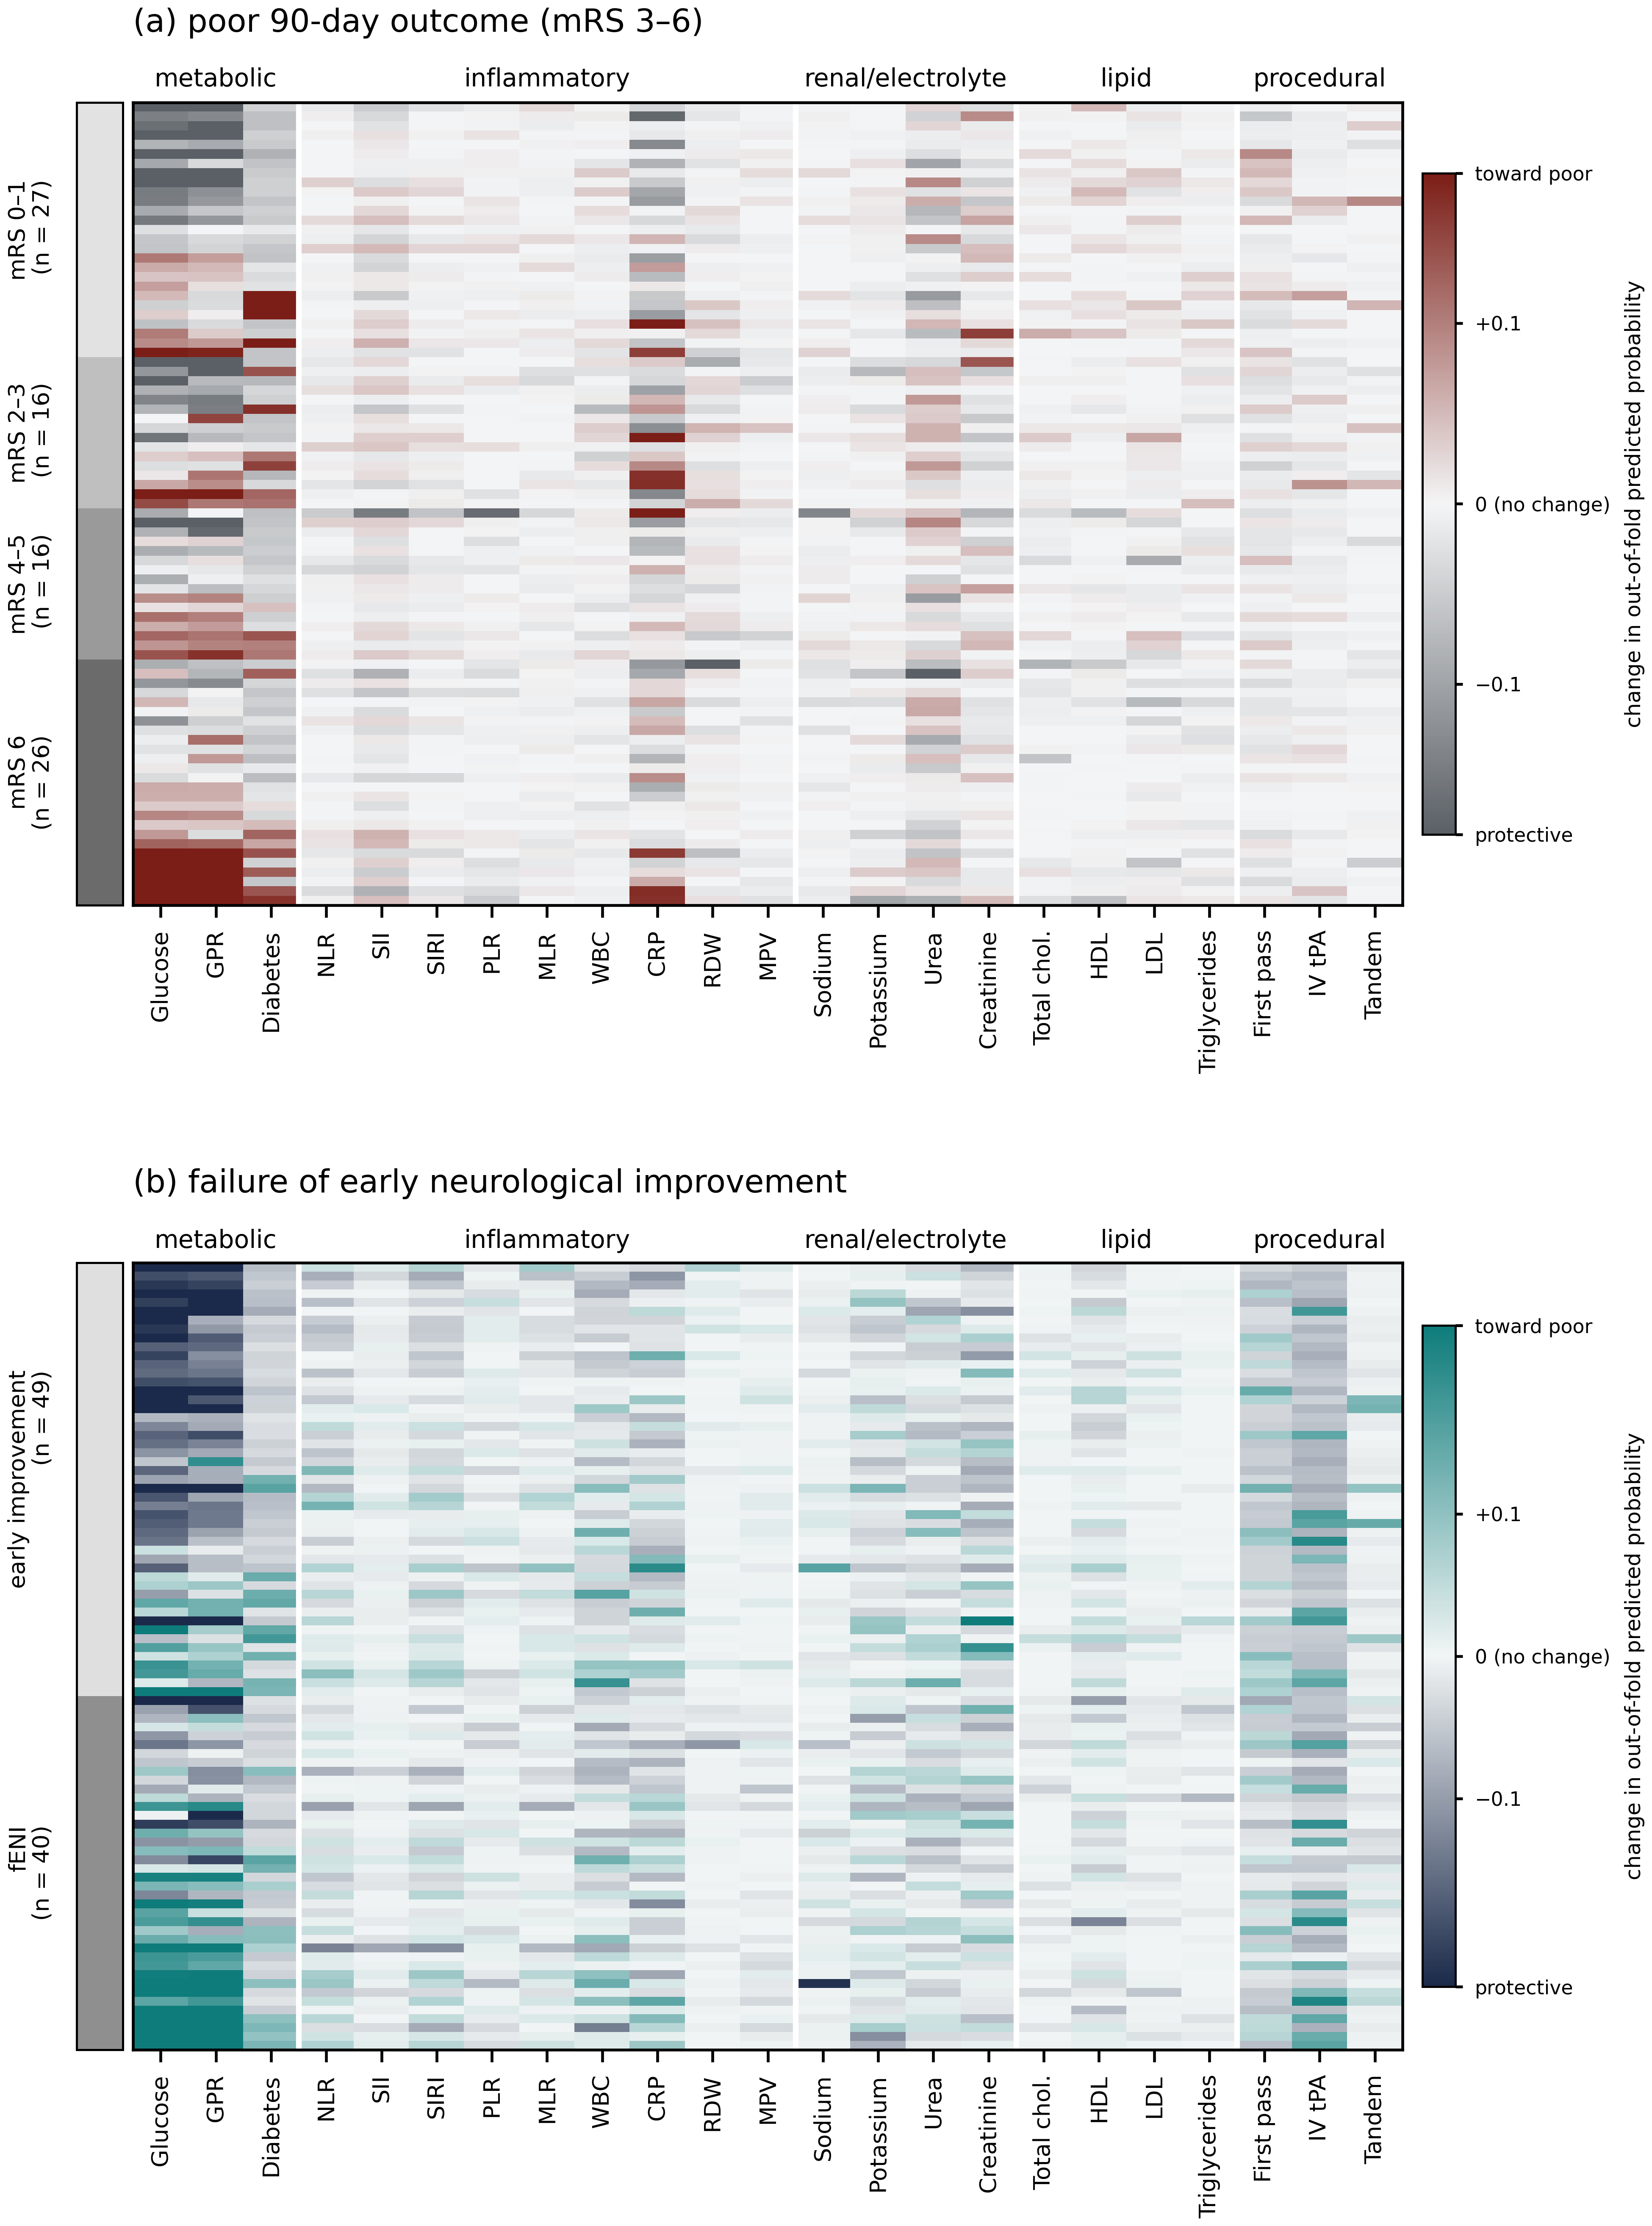

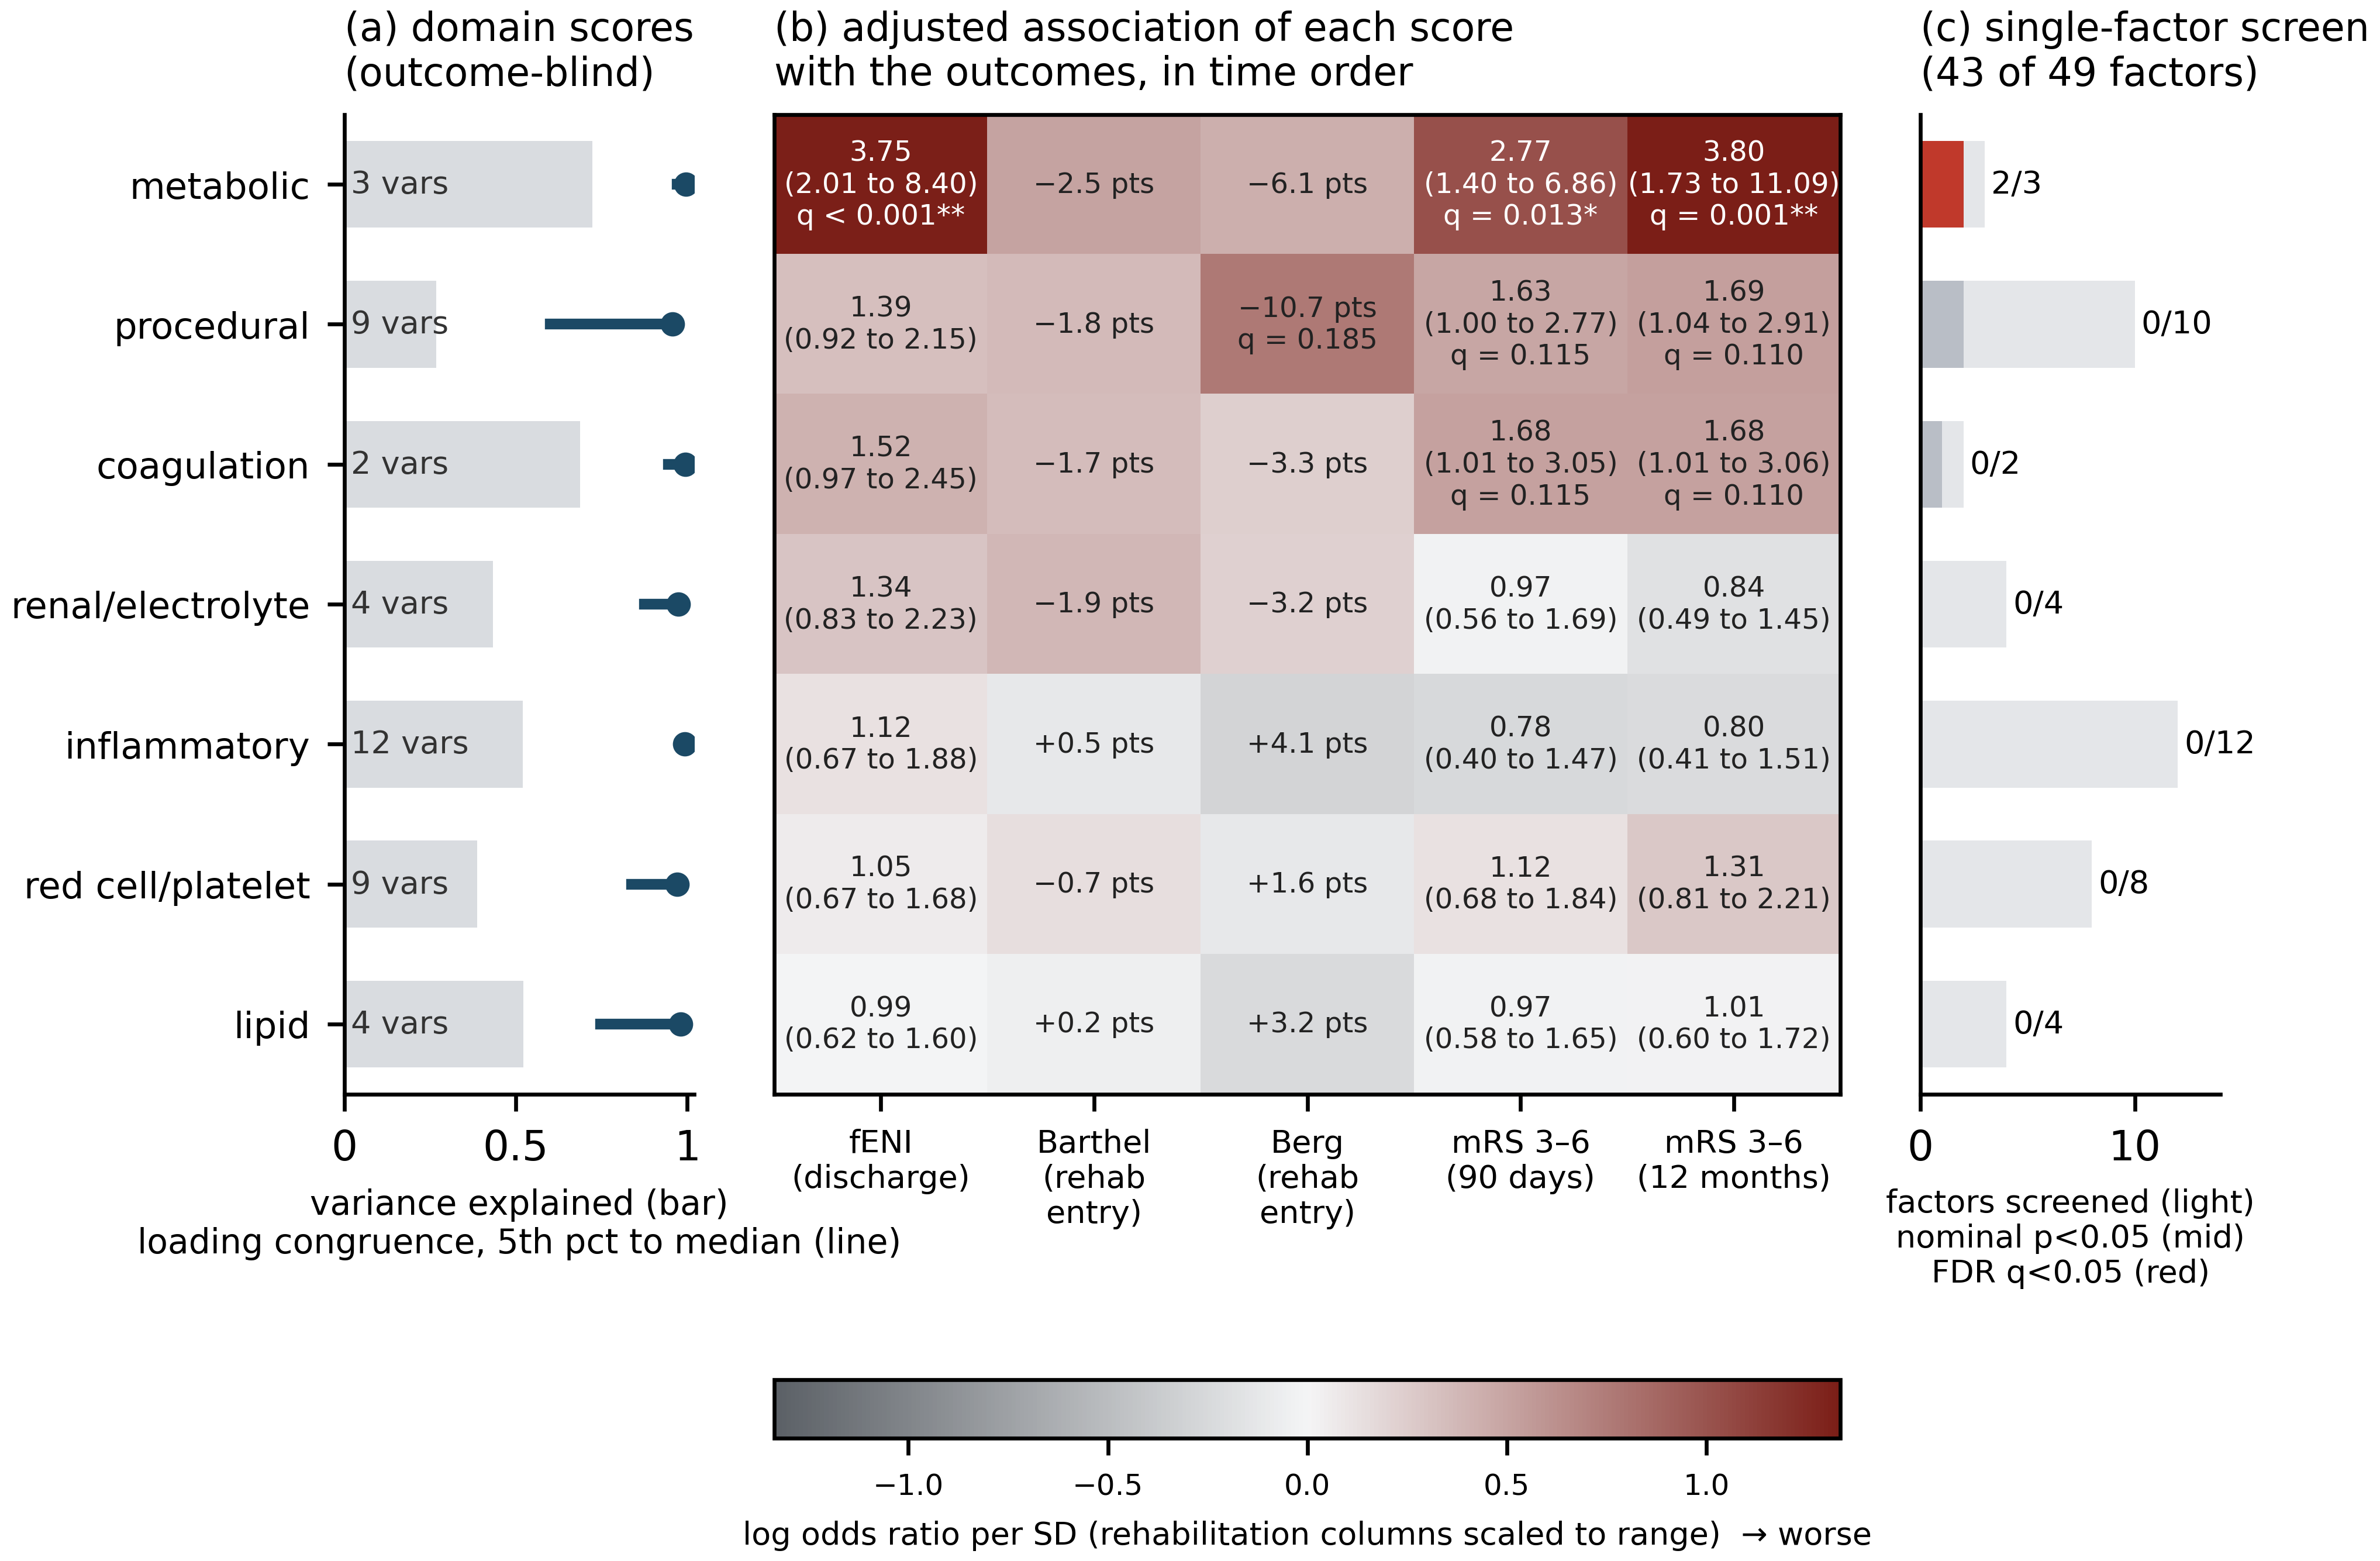

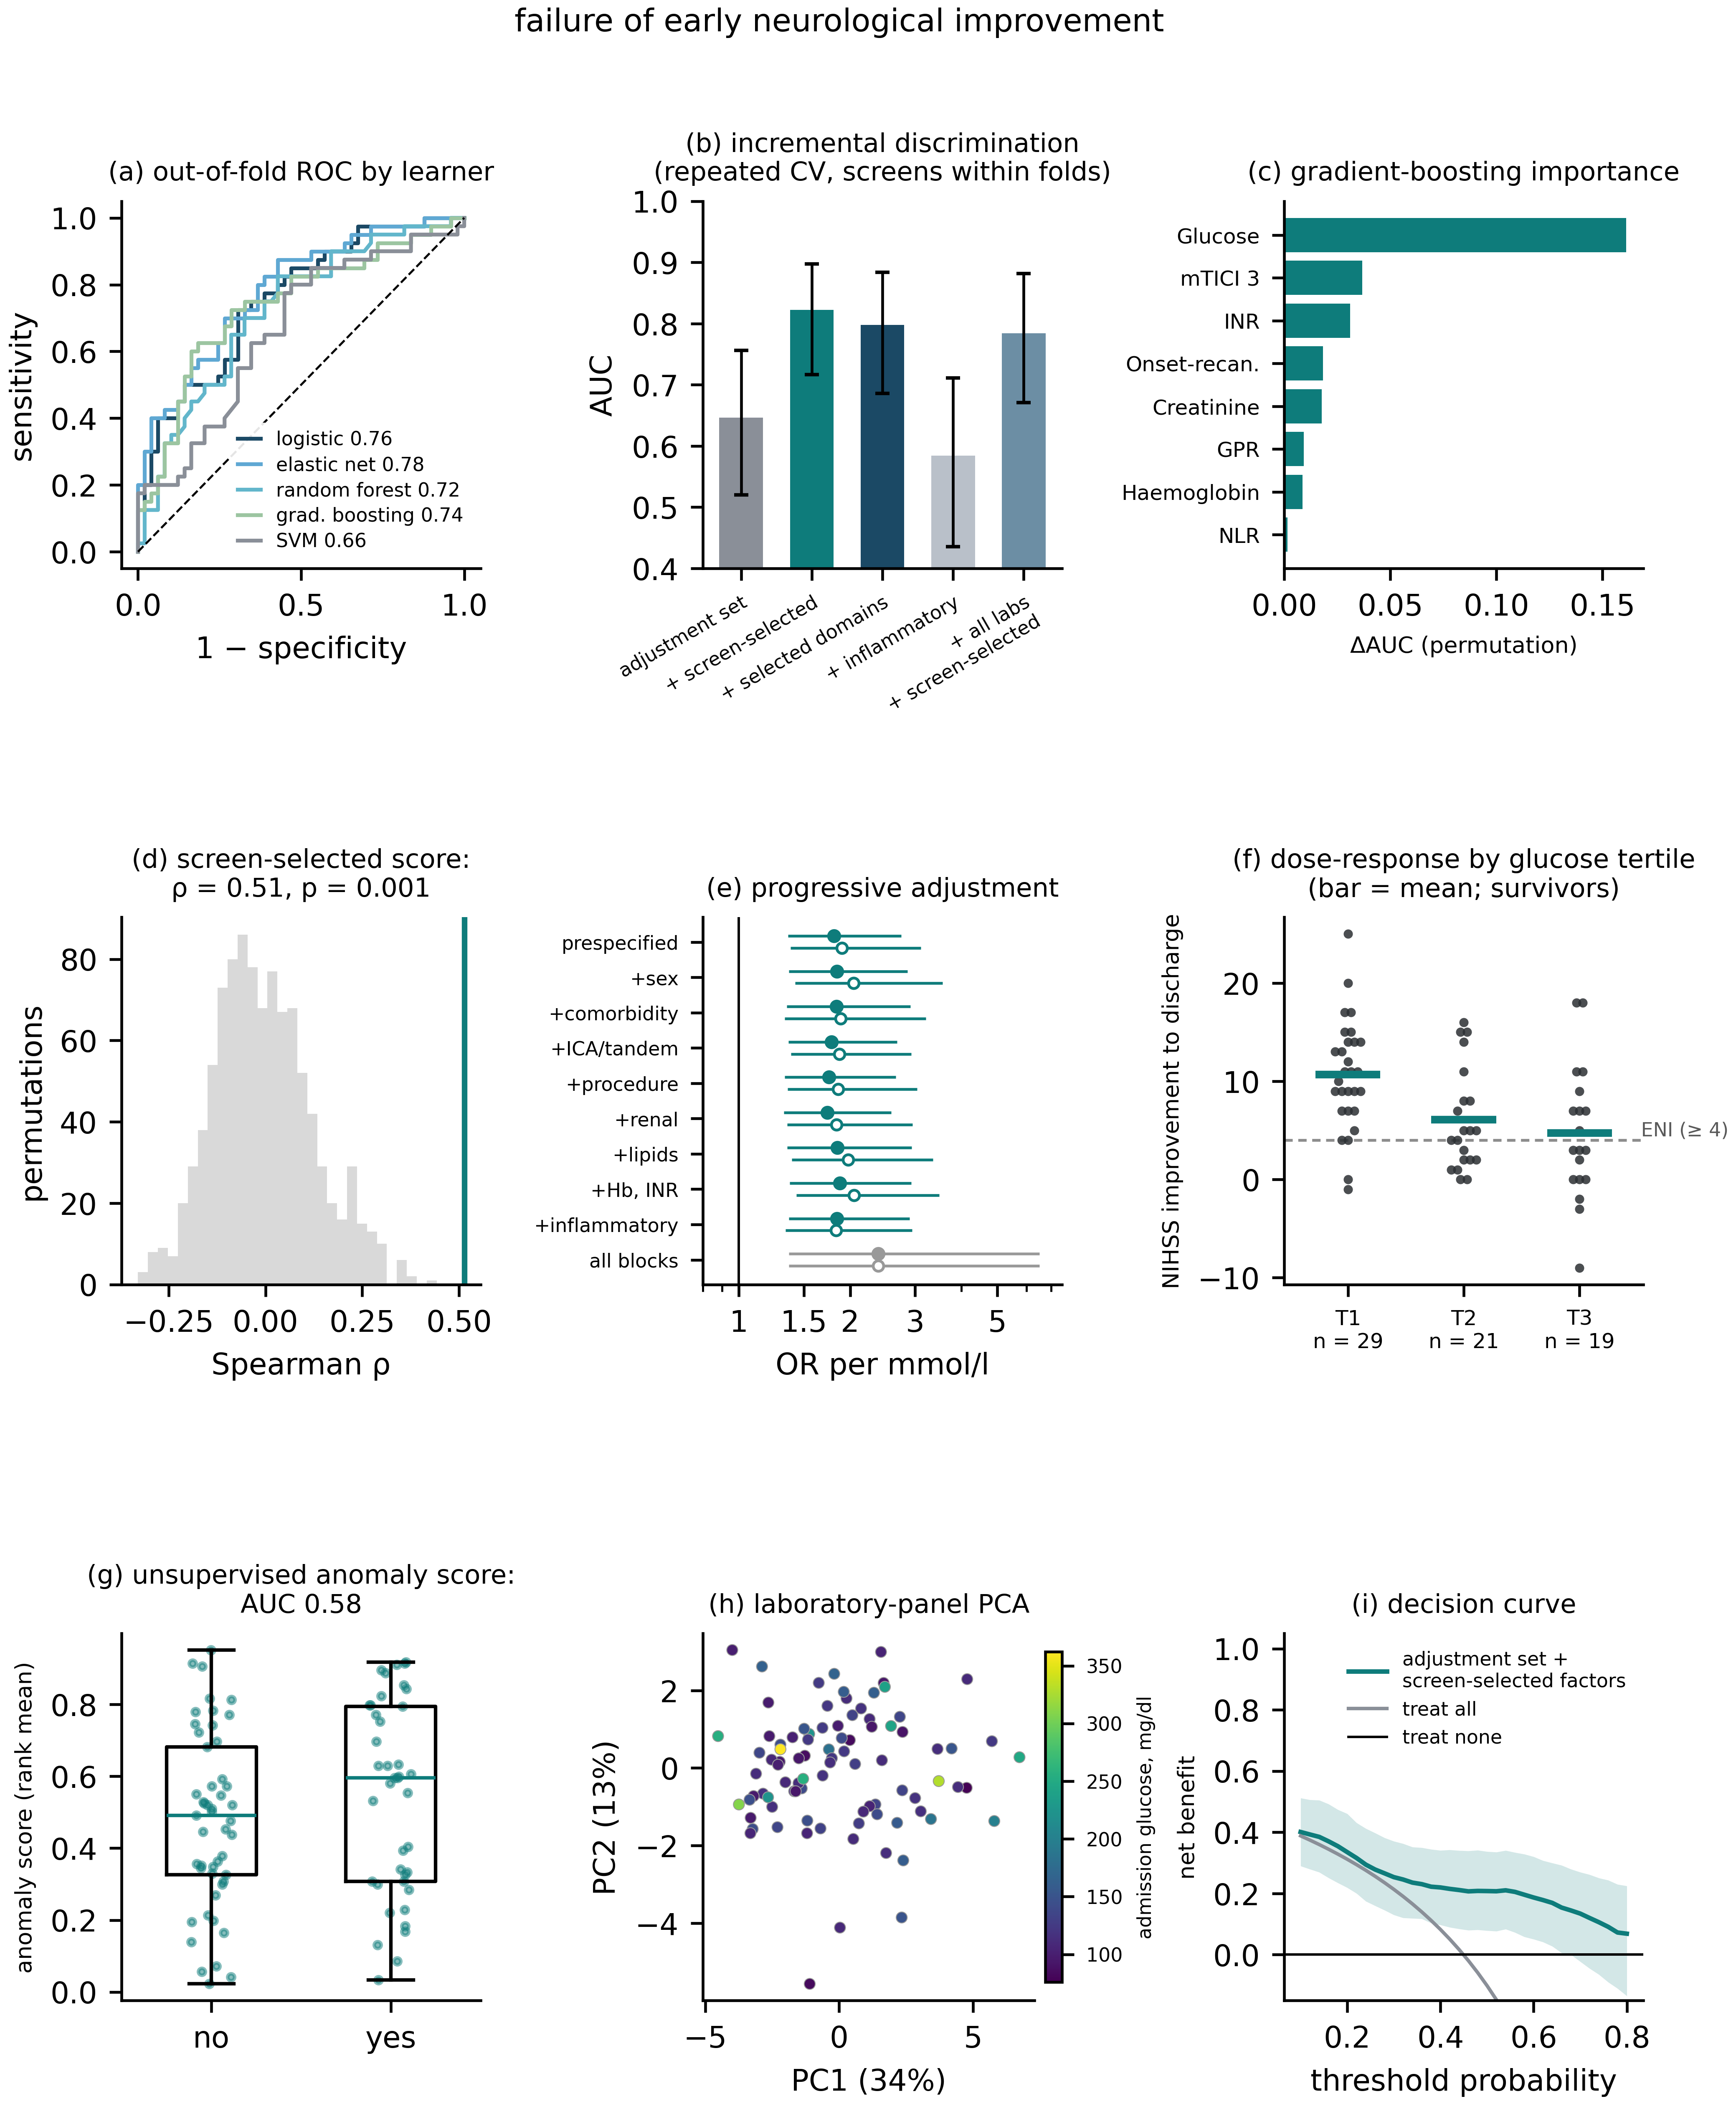

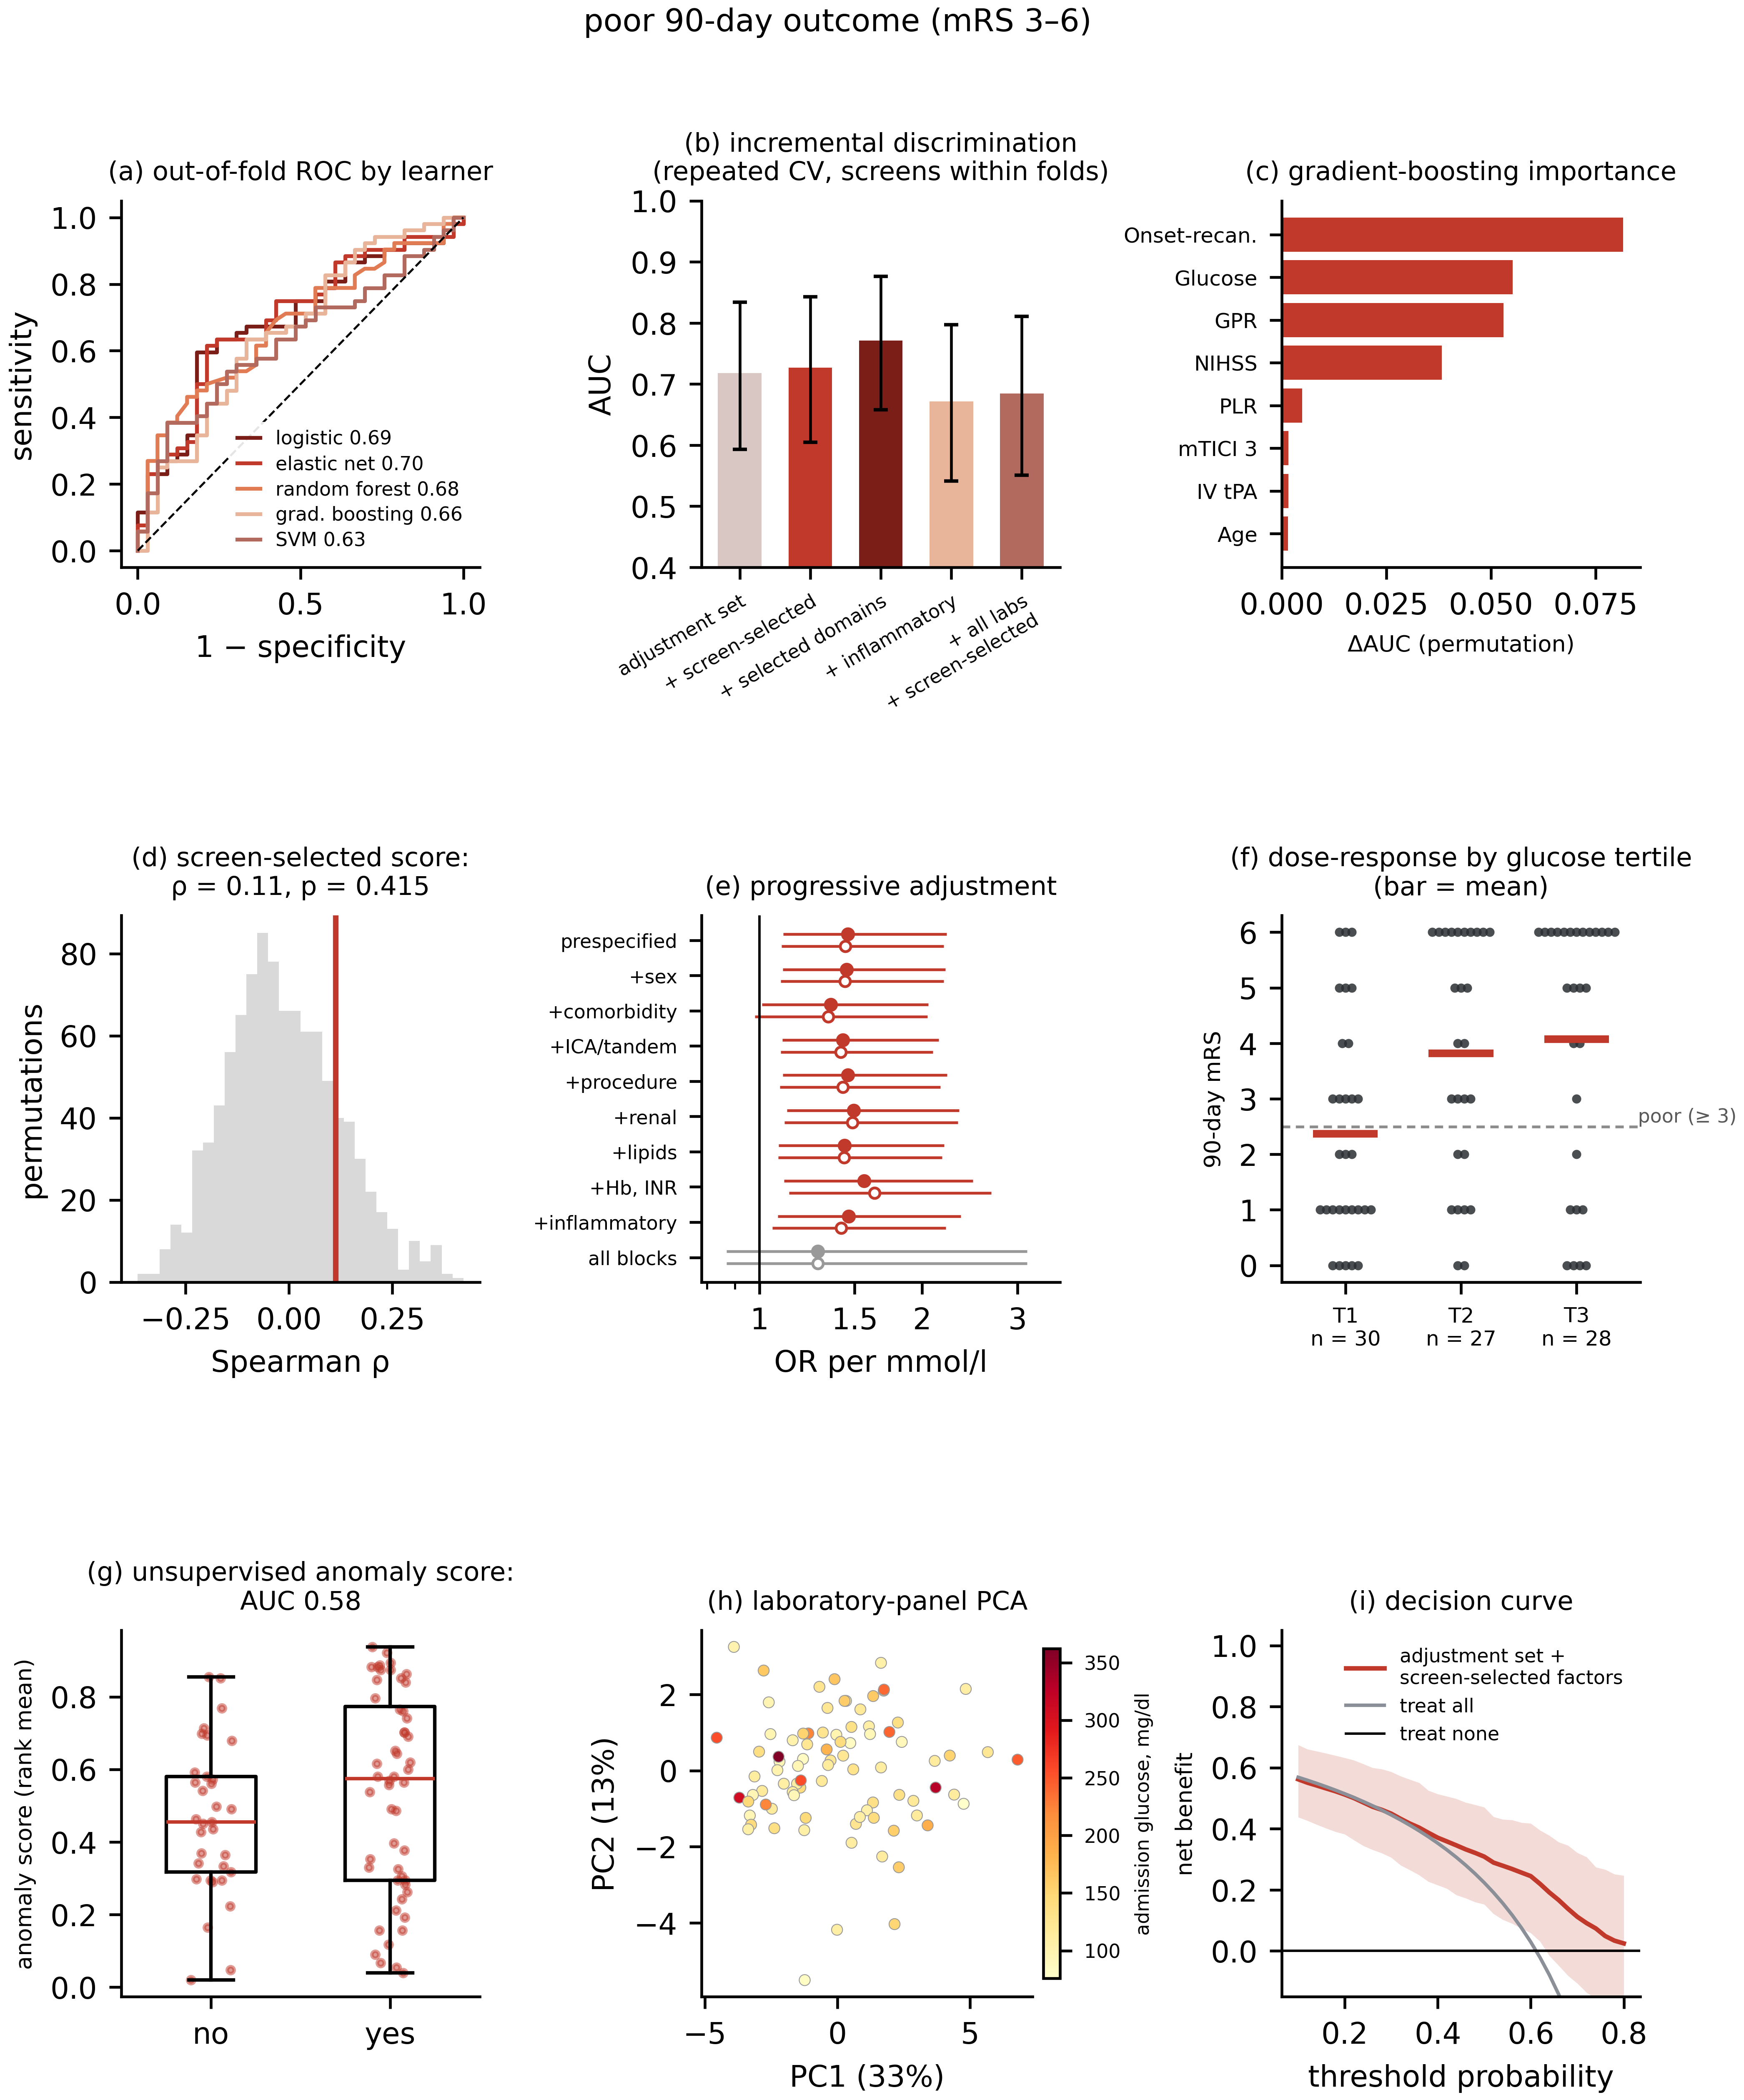

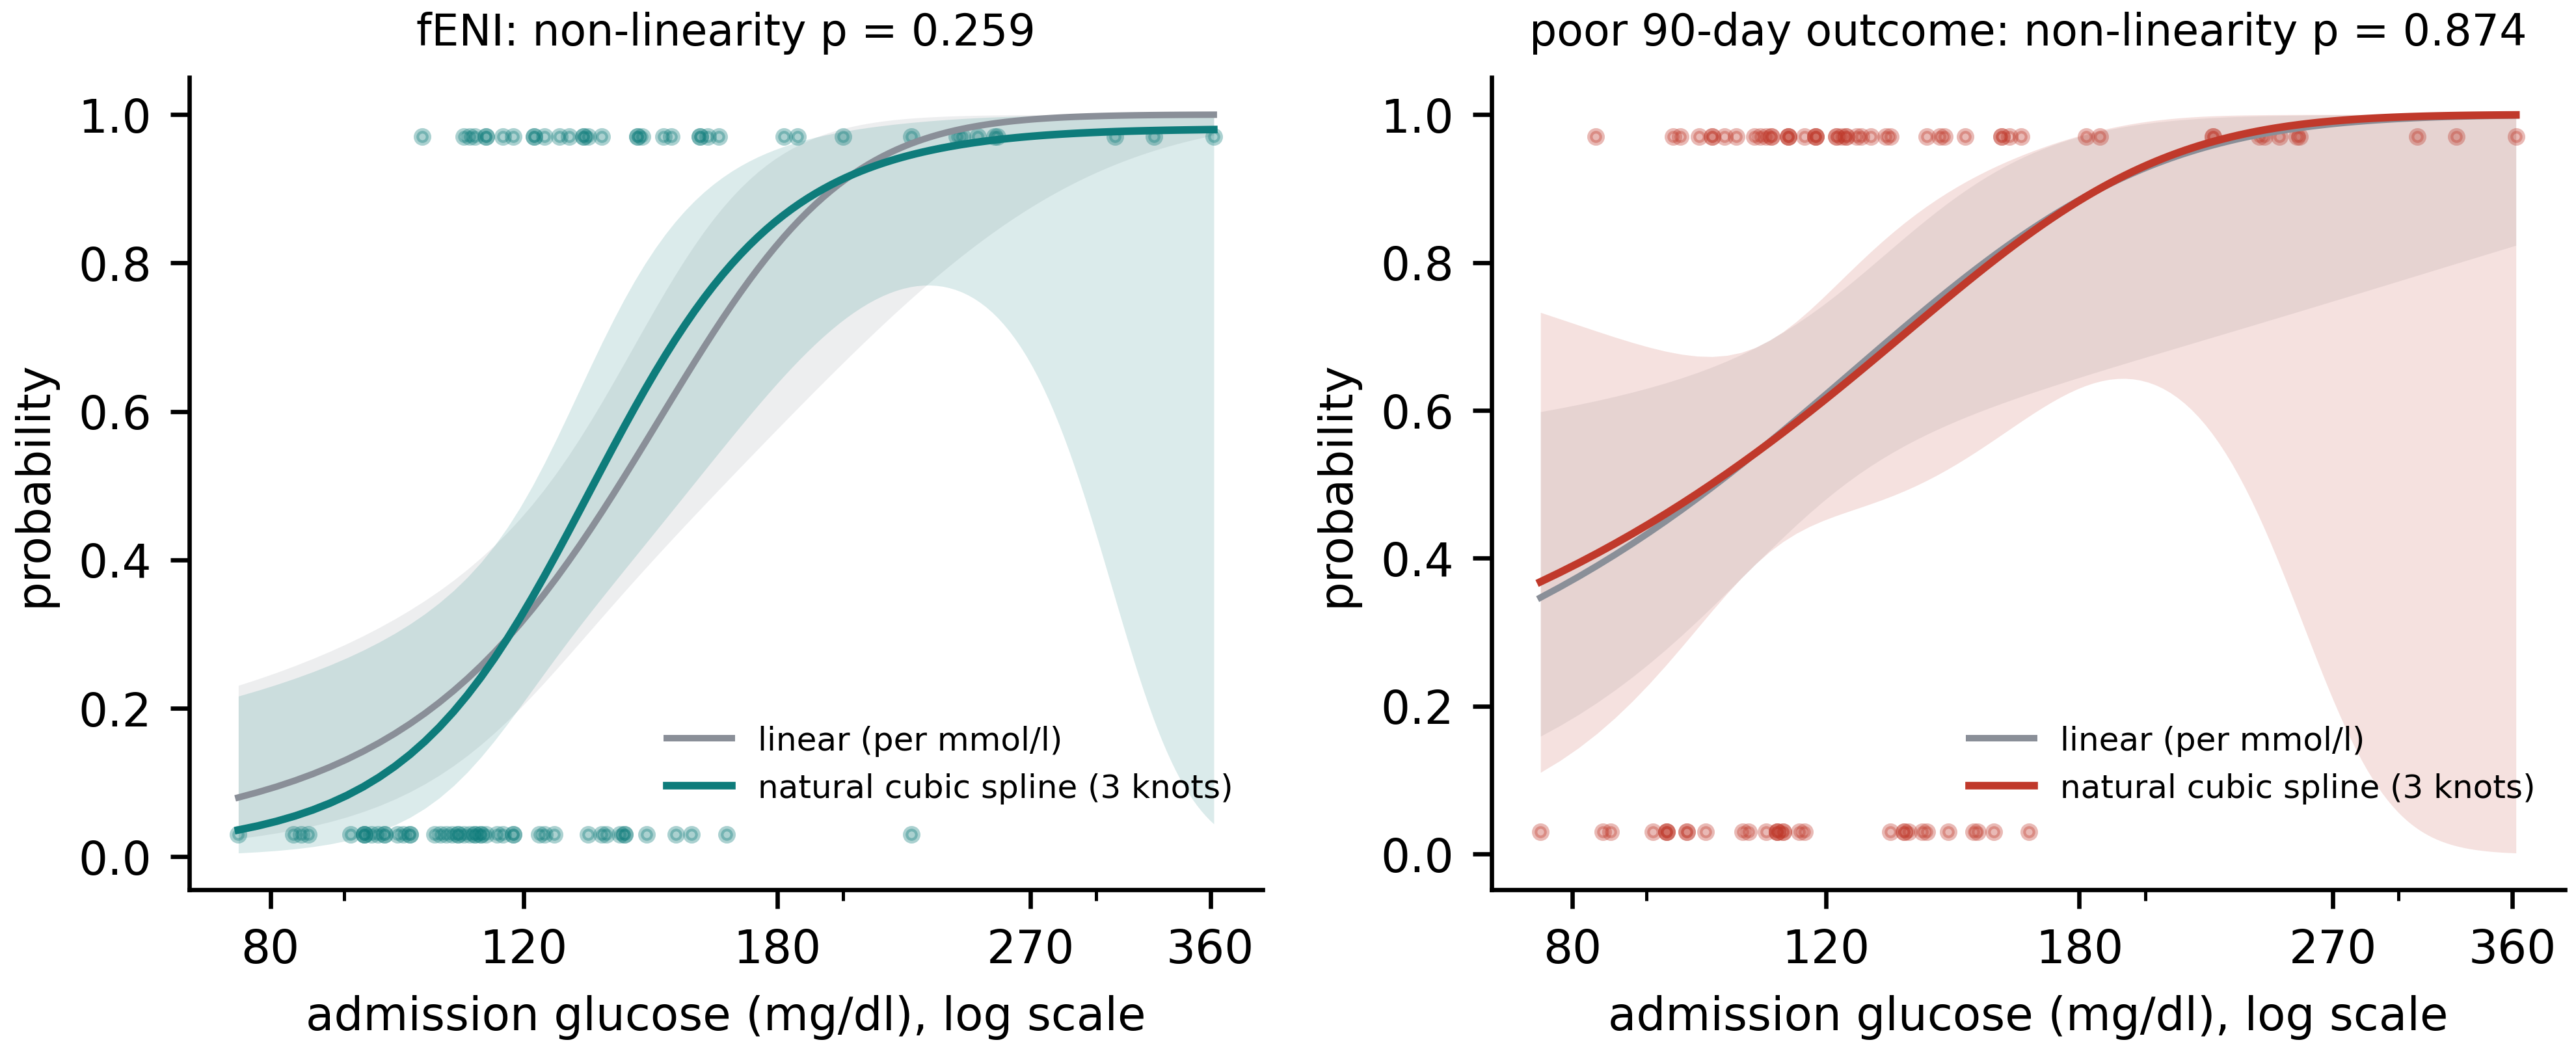

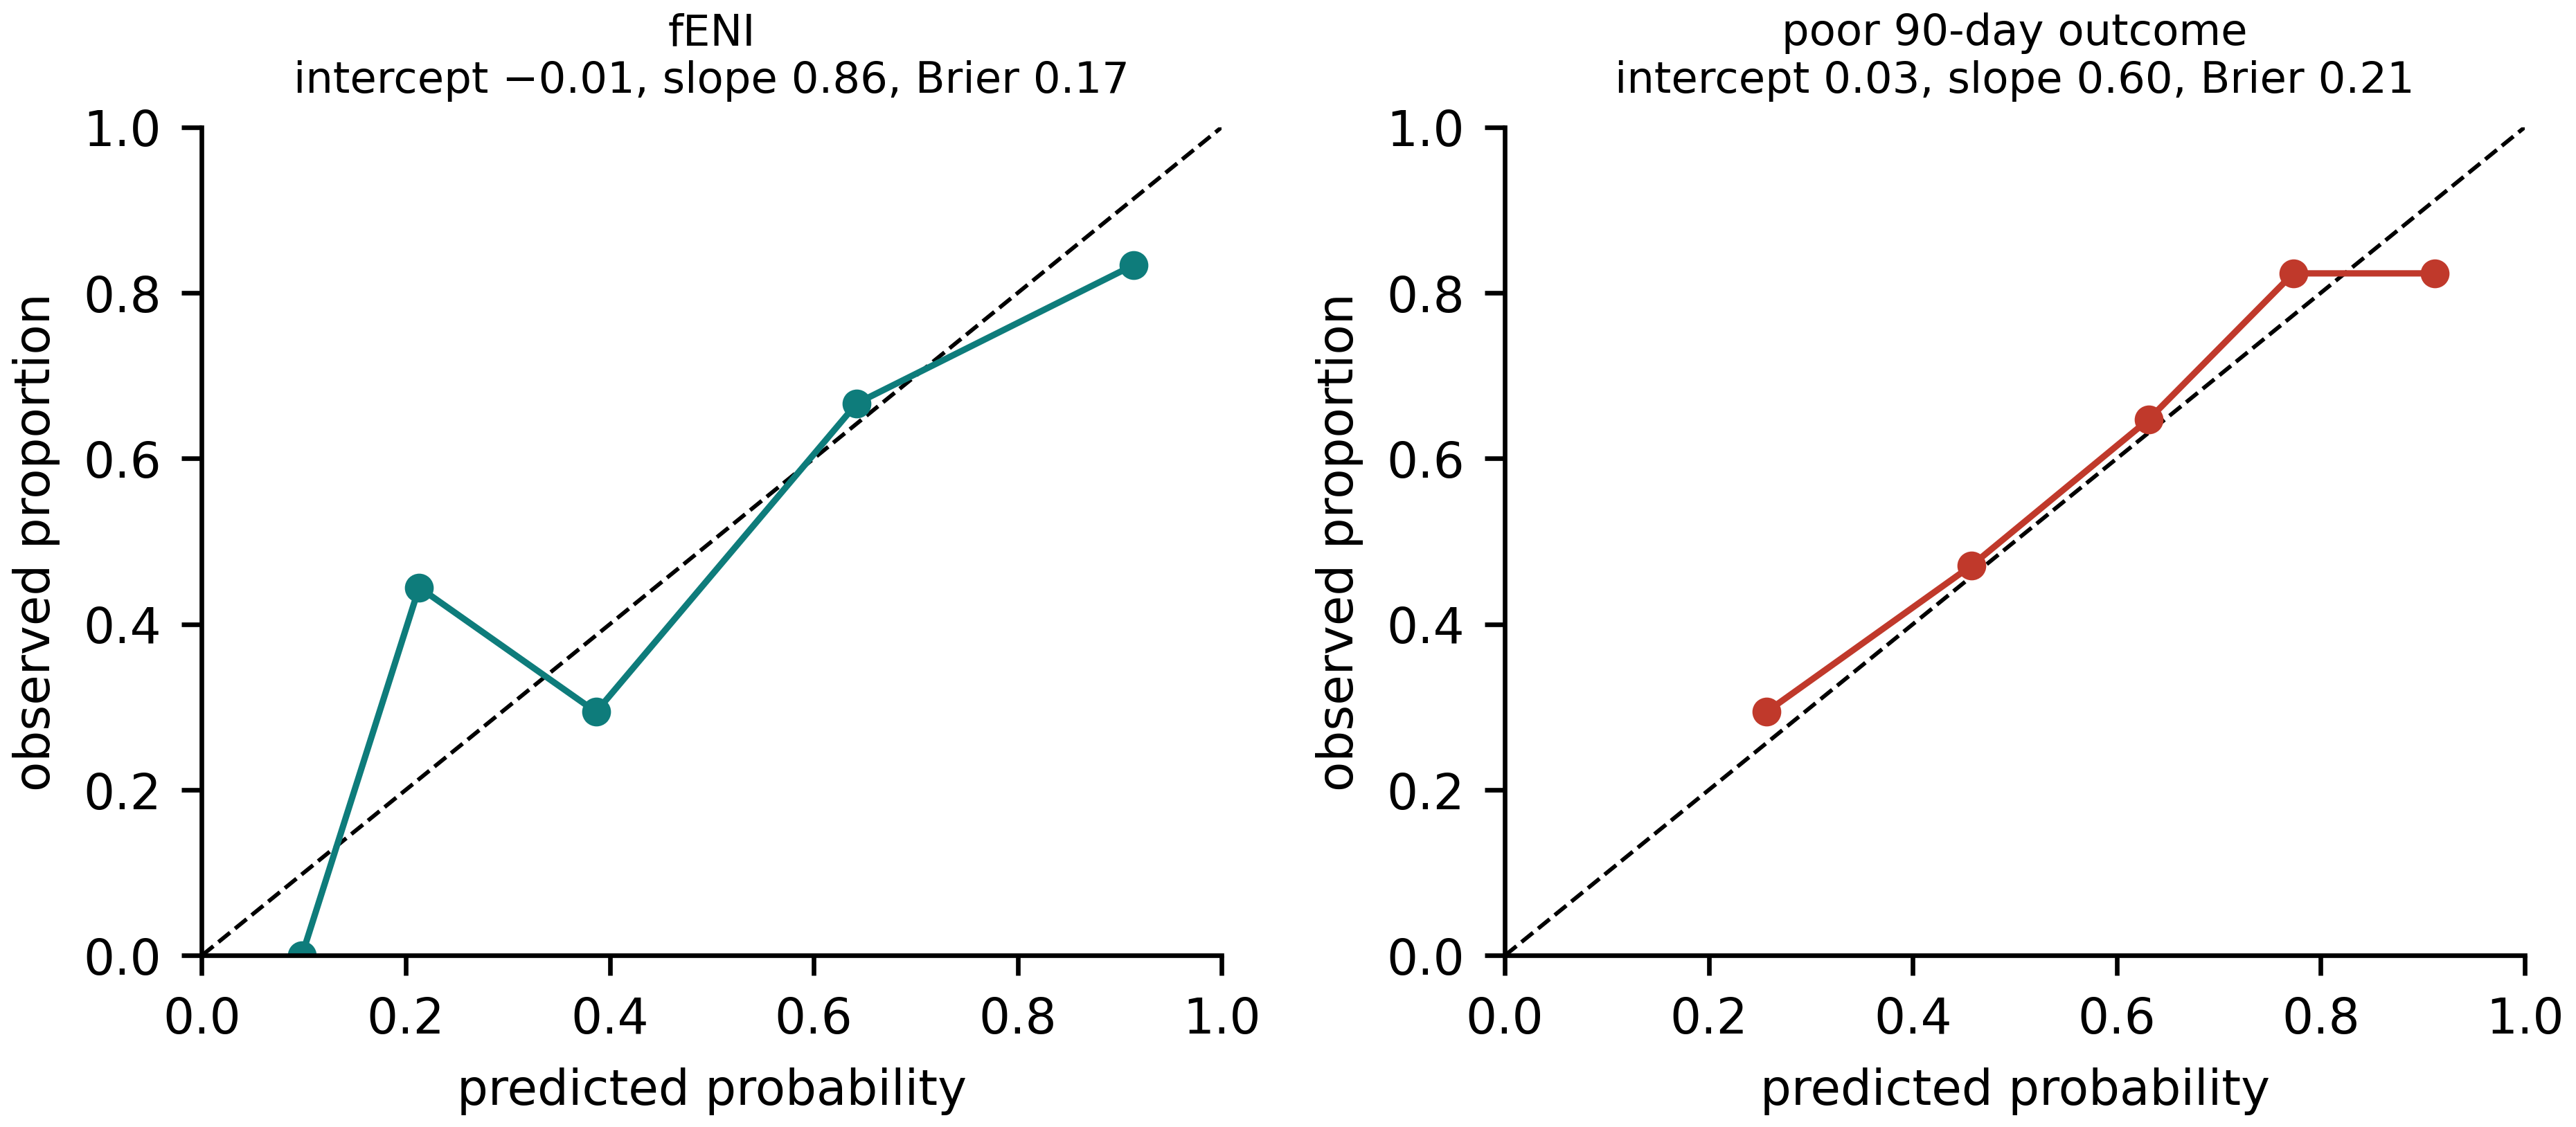

In [15]:
fig1((HM["poor_mRS_90d"][0], HM["poor_mRS_90d"][1], HM["poor_mRS_90d"][2]),
     (HM["fENI"][0], HM["fENI"][1], HM["fENI"][2]))
fig2({"fENI": S49["fENI"], "poor_mRS_90d": S49["poor_mRS_90d"]}, PA["fENI"])          # Supplementary Figure S2
fig2_domain(DMETA, DLOCK, F49)
figs34(dd, "fENI", ML["fENI"], CV["fENI"], PA["fENI"], TEAL,
       "Figure3_ml_grid_fENI", "failure of early neurological improvement")
figs34(dd, "poor_mRS_90d", ML["poor_mRS_90d"], CV["poor_mRS_90d"],
       PA["poor_mRS_90d"], RED, "Figure4_ml_grid_mRS90", "poor 90-day outcome (mRS 3\u20136)")
figS1(dd, SA, None)
figS2([("fENI", CAL["fENI"], CV["fENI"]["y"], CV["fENI"]["oof"][SCREENSEL].mean(0), TEAL, "fENI"),
       ("poor_mRS_90d", CAL["poor_mRS_90d"], CV["poor_mRS_90d"]["y"],
        CV["poor_mRS_90d"]["oof"][SCREENSEL].mean(0), RED, "poor 90-day outcome")])
from IPython.display import Image, display as disp
for f in ("Figure1_contribution_heatmaps", "Figure2_domain_scores_triple_lock",
          "Figure3_ml_grid_fENI", "Figure4_ml_grid_mRS90", "S5_exposure_functional_form", "S3_calibration"):
    disp(Image(filename=f"outputs/figs/{f}.png", width=620))

## 15. Rehabilitation-unit linkage and external validation of the discharge phenotype (Table 2, Figure 5)

Patients admitted to the hospital's inpatient neurorehabilitation unit are linked to the cohort by hospital record number from `data/rehabilitation_outcomes.ods`. Entry and discharge assessments (Barthel Index 0 to 20, Berg Balance Scale, Trunk Control Test, modified Sitting Assessment Scale, 10 m walk, MMSE, aphasia) were made by the rehabilitation team, who were unaware of admission glucose and of the study hypothesis. Referral is compared with non-referral among cohort survivors; entry and discharge measures are compared by fENI (Mann-Whitney U or Fisher exact, standardised mean difference, Benjamini-Hochberg q); entry and discharge measures are regressed on fENI, admission glucose (per mmol/l) and the metabolic score adjusted for admission NIHSS and age (ordinary least squares, Benjamini-Hochberg q across the 18 models); Spearman correlations relate the NIHSS change and admission glucose to the rehabilitation measures; and rehabilitation-discharge Barthel is compared with the registry 90-day and 12-month mRS. These analyses are exploratory and are reported with effect sizes and confidence intervals.

rehabilitation file: 36 patients; 29 in the cohort (33% of 89; 42% of 69 survivors); 7 not reperfused and outside the cohort
stroke to rehabilitation admission 11 days (IQR 9 to 14); rehabilitation stay 51 days (IQR 28 to 85)


,Measure,Not admitted (n=40),Admitted to rehabilitation (n=29),n_not_admitted,n_admitted,SMD,p,test
0,"Admission glucose, mg/dl",118 (104 to 141),112 (104 to 132),40,29,-0.123888,0.555371,Mann-Whitney U
1,Admission NIHSS,17 (14 to 19),16 (10 to 18),40,29,-0.243346,0.326547,Mann-Whitney U
2,Discharge NIHSS,3 (2 to 14),6 (4 to 9),40,29,0.047041,0.172033,Mann-Whitney U
3,"NIHSS reduction, admission to discharge",7 (3 to 13),7 (2 to 11),40,29,-0.242146,0.483605,Mann-Whitney U
4,"Age, years",72.5 (66 to 78),70 (61 to 75),40,29,-0.264450,0.339533,Mann-Whitney U
5,"Onset to recanalisation, min",216 (177.5 to 271.0),251 (210 to 339),40,26,0.441313,0.070128,Mann-Whitney U
6,90-day mRS,1 (1 to 5),3 (2 to 4),39,26,0.191722,0.282987,Mann-Whitney U
7,Failure of early neurological improvement,11/40 (28%),9/29 (31%),40,29,NaN,0.792621,Fisher exact
8,Female sex,14/40 (35%),14/29 (48%),40,29,NaN,0.324556,Fisher exact
9,Diabetes mellitus,9/40 (23%),7/29 (24%),40,29,NaN,1.000000,Fisher exact


,Measure,Early improvement (n=20),fENI (n=9),n_ENI,n_fENI,SMD,p,test,q_FDR
0,"Stroke to rehabilitation admission, days",10 (10 to 14),11 (9 to 15),20,9,0.111935,0.793678,Mann-Whitney U,0.892888
1,"Barthel Index (0 to 20), entry",9 (3 to 11),1 (0 to 3),17,9,-1.019878,0.054880,Mann-Whitney U,0.164640
2,"Berg Balance Scale (0 to 56), entry",41 (17 to 47),16 (4 to 28),18,8,-0.799354,0.106435,Mann-Whitney U,0.212870
3,"Trunk Control Test (0 to 100), entry",100 (81 to 100),87 (36 to 100),18,9,-0.626513,0.122546,Mann-Whitney U,0.220582
4,"Modified Sitting Assessment Scale (4 to 16), e...",15.5 (11 to 16),9 (6 to 13),18,9,-1.128733,0.008066,Mann-Whitney U,0.097210
5,"Able to walk 10 m, entry",11/18 (61%),2/9 (22%),18,9,NaN,0.103188,Fisher exact,0.212870
6,"MMSE (0 to 30), entry",15 (4 to 22),18 (0 to 22),17,9,0.004230,1.000000,Mann-Whitney U,1.000000
7,"Aphasia, entry",11/20 (55%),4/9 (44%),20,9,NaN,0.699850,Fisher exact,0.839820
8,"Rehabilitation stay, days",42 (26 to 74),79 (58 to 111),20,9,0.899252,0.035813,Mann-Whitney U,0.128927
9,"Barthel Index, discharge",17 (15 to 20),16 (5 to 20),17,9,-0.581249,0.619360,Mann-Whitney U,0.839820


,outcome,term,beta,CI_low,CI_high,p,n,r2,p_shapiro_resid,p_breusch_pagan,p_hc3,q_FDR,q_FDR_hc3,label
0,barthel_in,fENI,-5.605,-10.355,-0.855,0.023,26,0.222,0.520,0.203,0.017,0.114,0.110,fENI (yes vs no)
1,barthel_in,Glucose_mmol,-0.794,-2.110,0.522,0.224,26,0.075,0.141,0.073,0.652,0.382,0.827,"admission glucose, per mmol/l"
2,barthel_in,metabolic_score,-2.529,-5.387,0.329,0.080,26,0.141,0.423,0.059,0.387,0.206,0.784,"metabolic score, per SD"
3,berg_in,fENI,-21.078,-40.884,-1.273,0.038,26,0.203,0.134,0.924,0.018,0.114,0.110,fENI (yes vs no)
4,berg_in,Glucose_mmol,-1.025,-6.353,4.303,0.694,26,0.034,0.008,0.975,0.845,0.694,0.845,"admission glucose, per mmol/l"
5,berg_in,metabolic_score,-6.093,-17.424,5.238,0.277,26,0.079,0.035,0.717,0.523,0.383,0.784,"metabolic score, per SD"
6,tct_in,fENI,-33.427,-62.656,-4.199,0.027,27,0.344,0.122,0.038,0.090,0.114,0.283,fENI (yes vs no)
7,tct_in,Glucose_mmol,-2.299,-10.278,5.679,0.557,27,0.196,0.003,0.400,0.781,0.590,0.827,"admission glucose, per mmol/l"
8,tct_in,metabolic_score,-10.065,-27.464,7.333,0.244,27,0.232,0.015,0.189,0.504,0.382,0.784,"metabolic score, per SD"
9,sas_in,fENI,-5.496,-8.900,-2.093,0.003,27,0.382,0.245,0.092,0.013,0.051,0.110,fENI (yes vs no)


,x,x_label,y,y_label,n,rho,p
0,nihss_reduction,"NIHSS reduction, admission to discharge",barthel_in,Barthel entry,26,0.463,0.017
1,nihss_reduction,"NIHSS reduction, admission to discharge",berg_in,Berg entry,26,0.442,0.024
2,nihss_reduction,"NIHSS reduction, admission to discharge",tct_in,TCT entry,27,0.438,0.022
3,nihss_reduction,"NIHSS reduction, admission to discharge",sas_in,SAS entry,27,0.639,0.000
4,nihss_reduction,"NIHSS reduction, admission to discharge",barthel_out,Barthel discharge,26,0.238,0.241
5,nihss_reduction,"NIHSS reduction, admission to discharge",berg_out,Berg discharge,27,0.410,0.034
6,nihss_reduction,"NIHSS reduction, admission to discharge",barthel_gain,Barthel gain,26,0.001,0.995
7,nihss_reduction,"NIHSS reduction, admission to discharge",berg_gain,Berg gain,26,-0.211,0.302
8,nihss_reduction,"NIHSS reduction, admission to discharge",rehab_los,Rehabilitation stay,29,-0.411,0.027
9,Glucose,Admission glucose,barthel_in,Barthel entry,26,-0.468,0.016


,Measure,Tertile 1 (n=12),Tertile 2 (n=12),Tertile 3 (n=5),p_trend,p_KW
0,"Stroke to rehabilitation admission, days",10 (9 to 13),10.5 (9 to 15),11 (11 to 15),0.175496,0.449158
1,"Barthel Index (0 to 20), entry",11 (4 to 12),4.5 (1 to 9),0 (0 to 3),0.015299,0.134113
2,"Berg Balance Scale (0 to 56), entry",40 (11 to 47),33 (16 to 43),16 (0 to 35),0.091120,0.387915
3,"Trunk Control Test (0 to 100), entry",100 (61 to 100),100 (94 to 100),36 (0 to 100),0.192565,0.195099
4,"Modified Sitting Assessment Scale (4 to 16), e...",13 (11 to 16),14 (10 to 16),8 (4 to 13),0.090781,0.291611
5,"Able to walk 10 m, entry",7/11 (64%),4/11 (36%),2/5 (40%),0.179097,NaN
6,"MMSE (0 to 30), entry",6 (4 to 22),18.5 (17 to 22),0 (0 to 11),0.981362,0.231162
7,"Aphasia, entry",8/12 (67%),3/12 (25%),4/5 (80%),0.392481,NaN
8,"Rehabilitation stay, days",42 (29 to 67),77 (45 to 95),32 (22 to 99),0.143863,0.500271
9,"Barthel Index, discharge",19 (17 to 20),17.5 (15 to 20),5 (0 to 17),0.198088,0.259758


rehabilitation discharge Barthel vs 90-day mRS: rho -0.44 (n = 23, p = 0.034); Barthel >= 16 agrees with mRS 0-2 in 70%; vs 12-month mRS rho -0.46 (n = 23)


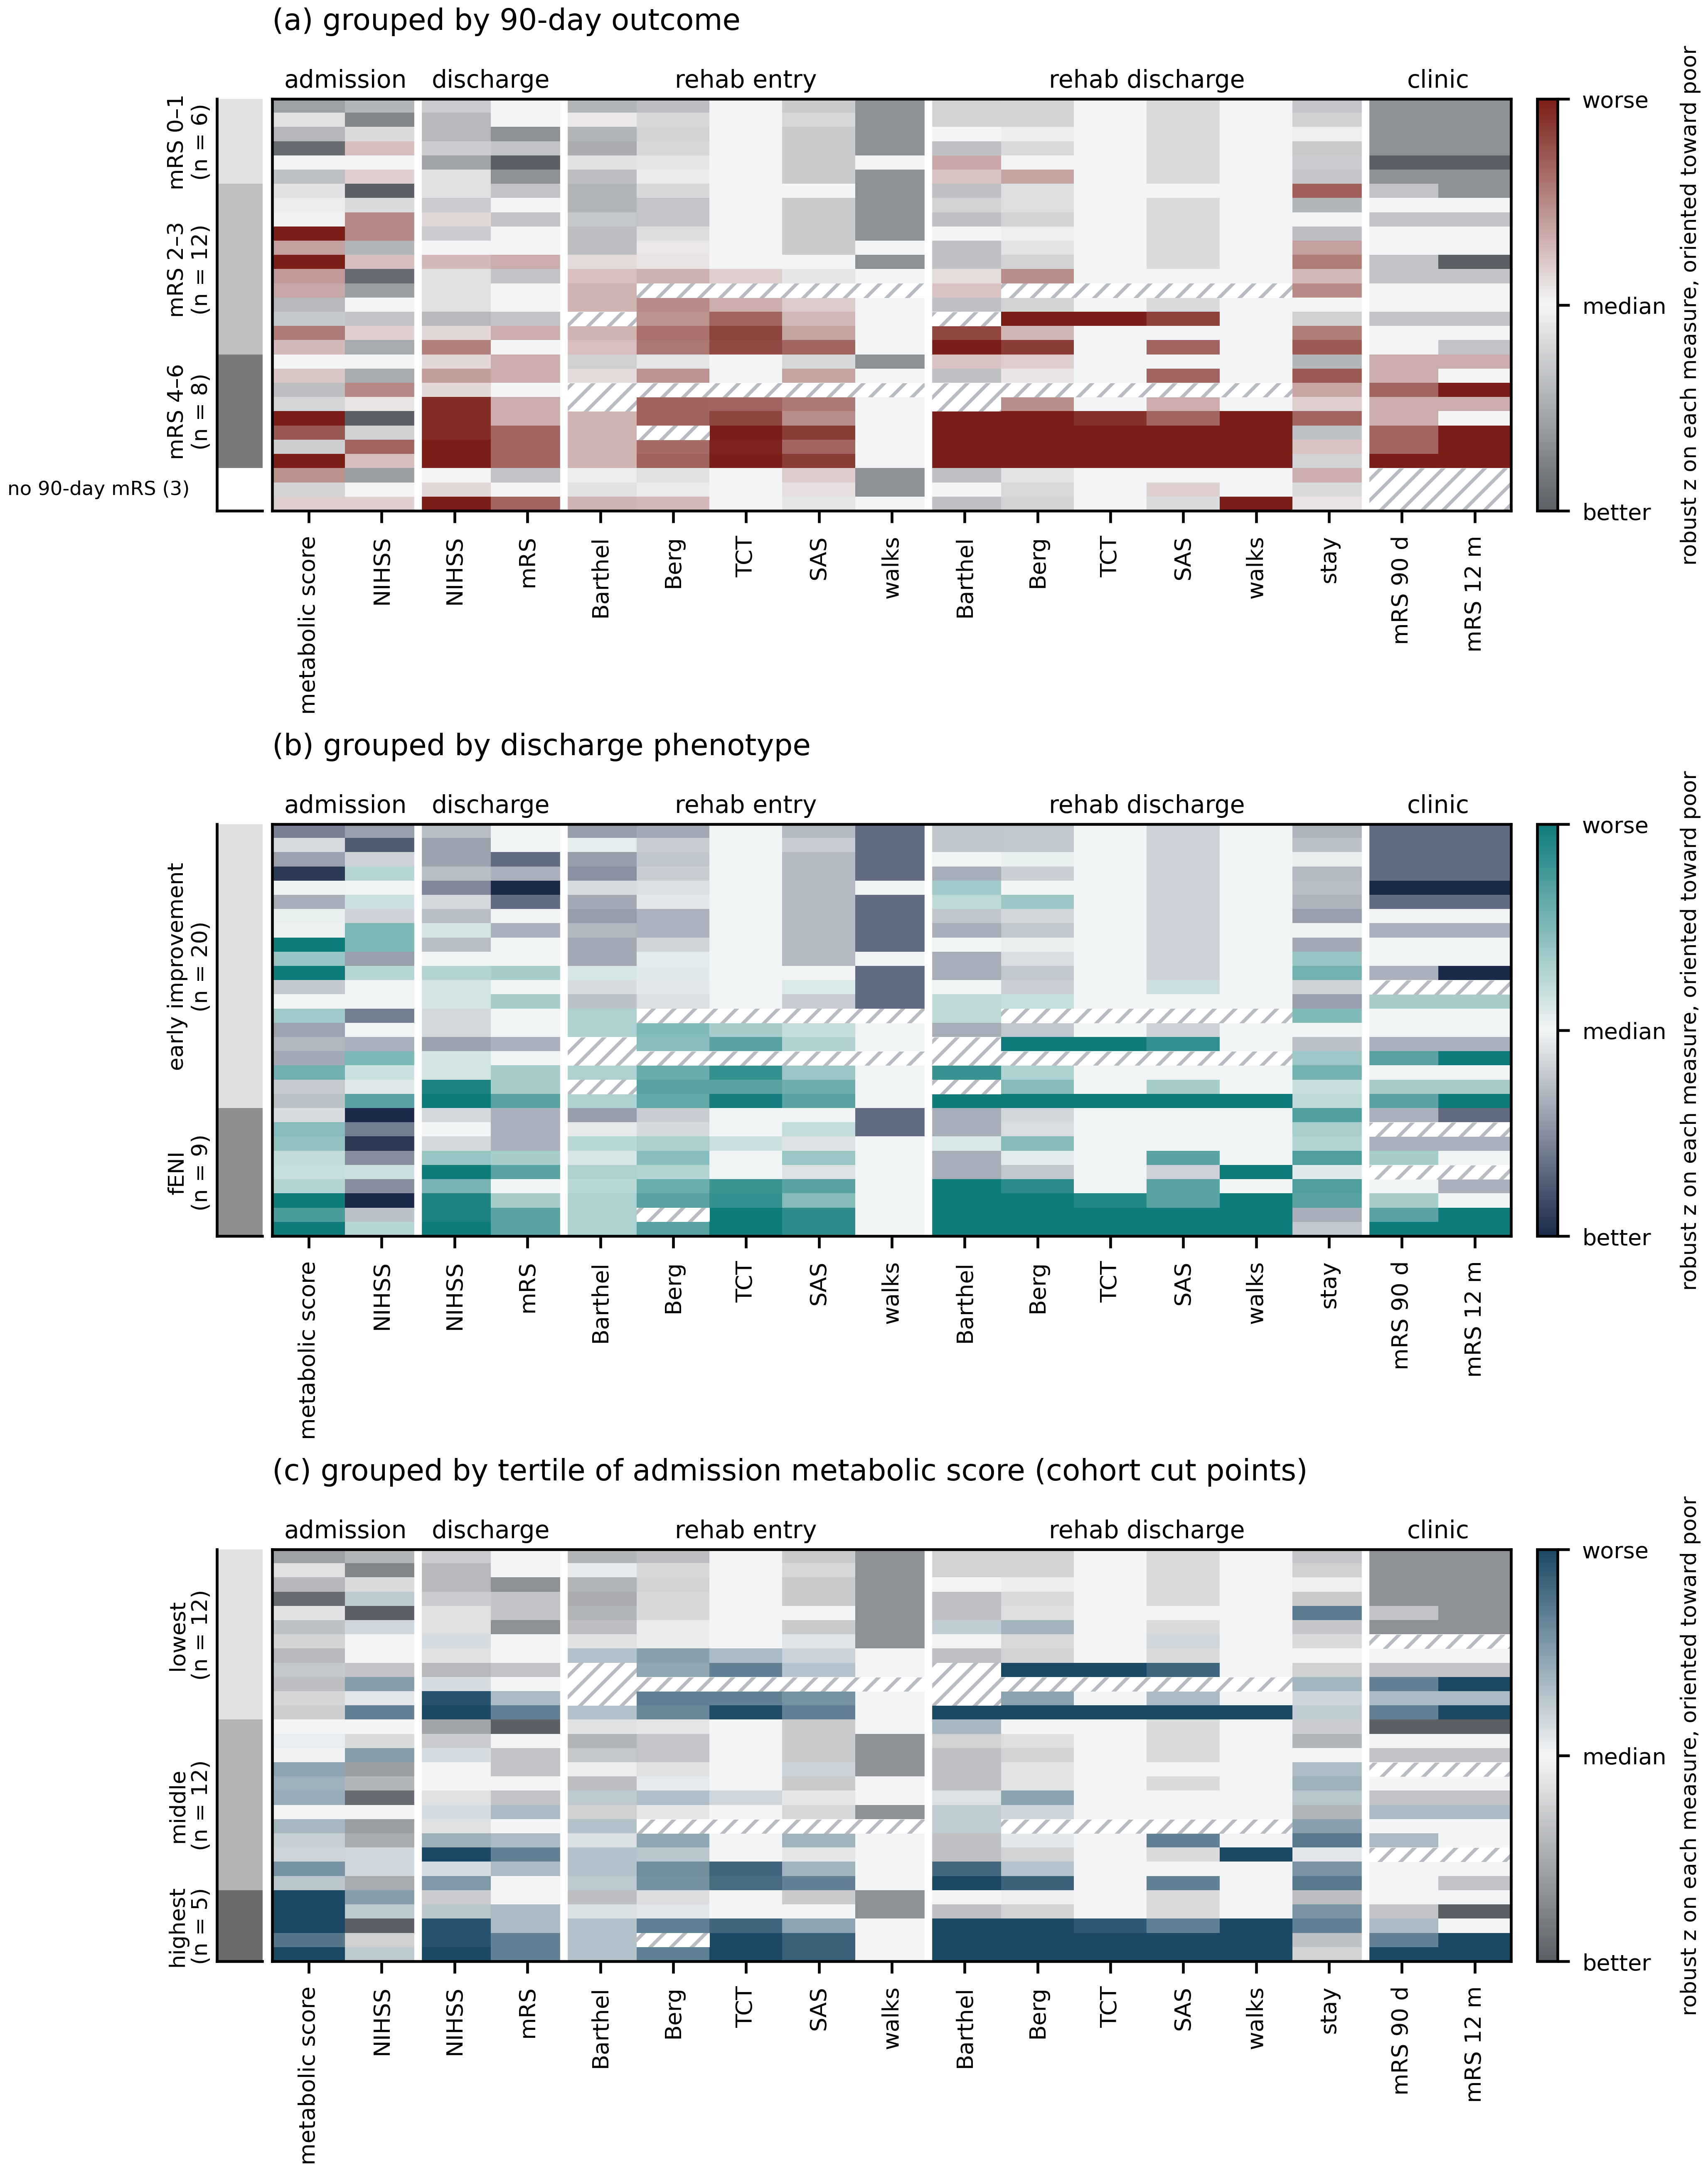

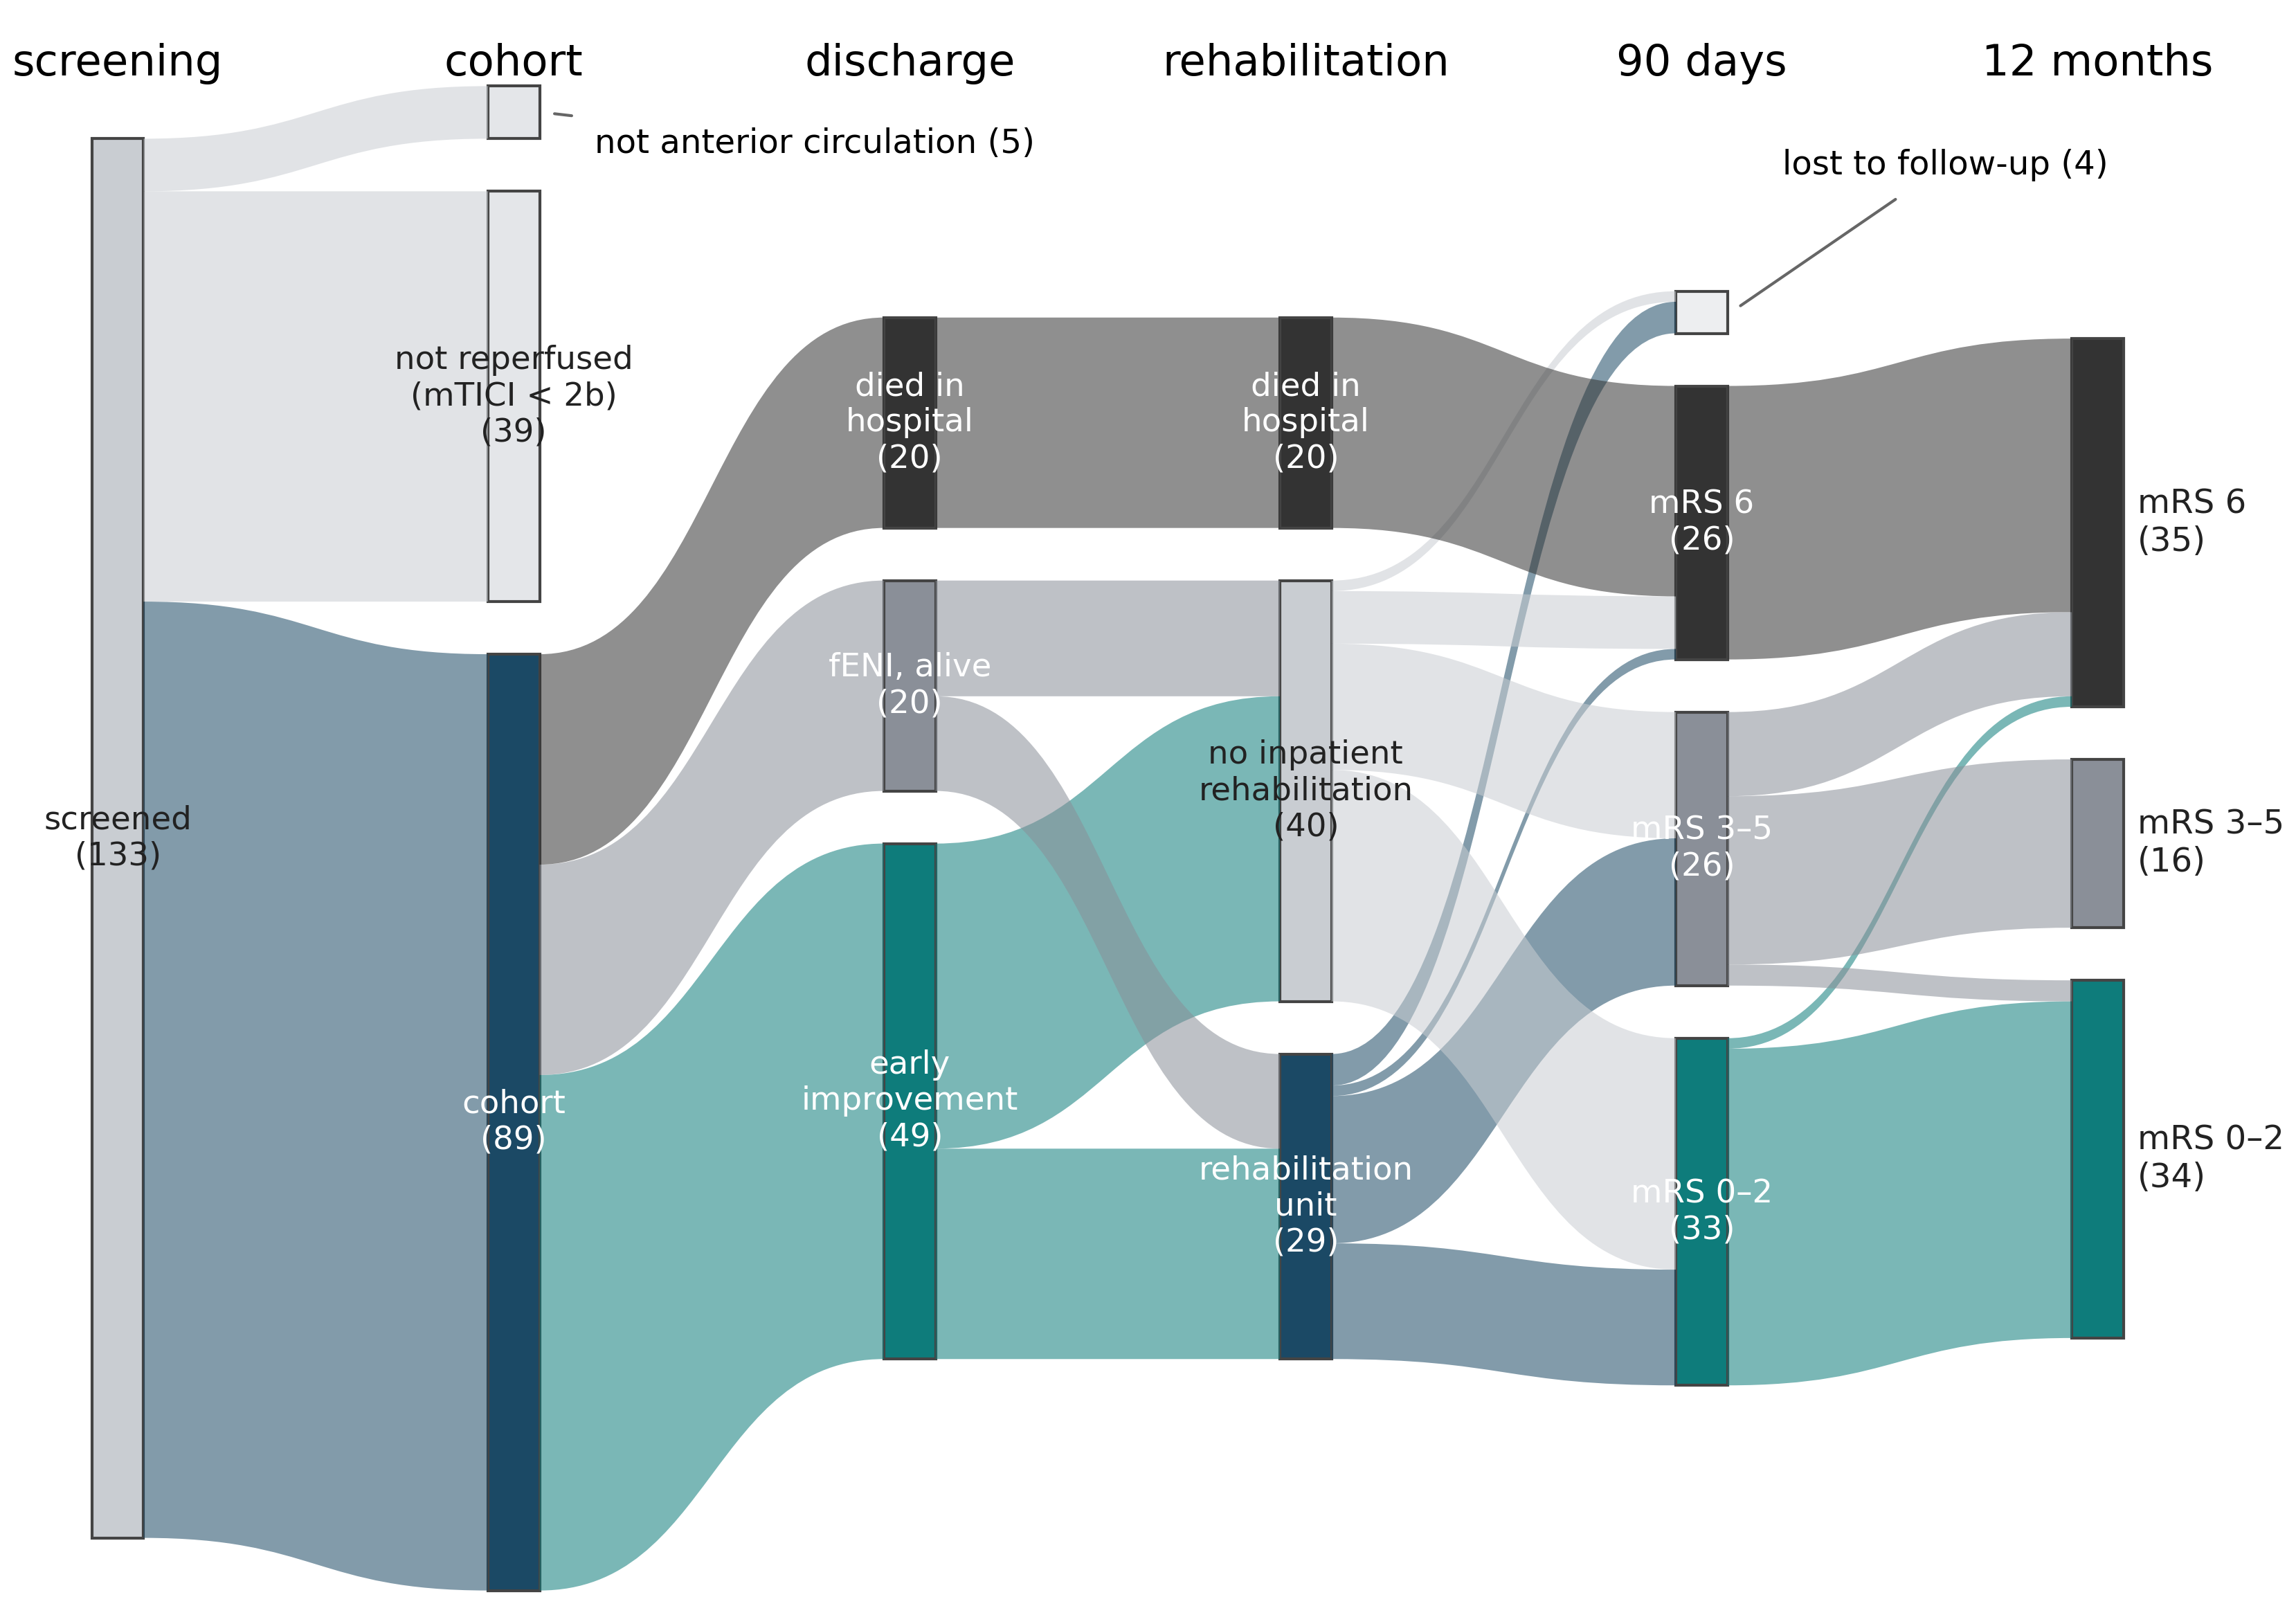

In [16]:
# Rehabilitation-unit linkage and external validation of the discharge phenotype. Author: Max Brzezicki.
# Reads data/rehabilitation_outcomes.ods, links it to the cohort by hospital record number, and
# tests whether failure of early neurological improvement (fENI) at discharge is reflected in
# independent functional measures taken by the rehabilitation team.
import statsmodels.api as sm

REHAB_PATH = "data/rehabilitation_outcomes.ods"
_raw = pd.read_excel("data/source_registry.ods", sheet_name="Data", engine="odf")
_key = _raw["Document no."].astype(str).str.strip()
_mt = _raw["mTICI post-procedure"].astype(str).str.strip().str.lower()
_keep = (_mt.isin(["2b", "2c", "3"]) & _raw["Occlusion location"].astype(str).str.contains("MCA|ICA", na=False)
         & (pd.to_numeric(_raw["mRS (1)"], errors="coerce") <= 2))
_key = _key[_keep].reset_index(drop=True)
assert len(_key) == len(d)
assert np.allclose(pd.to_numeric(_raw.loc[_keep, "Glucose (mg/dl)"], errors="coerce").values, d.Glucose.values, equal_nan=True)
d["record"] = _key.values

rh = pd.read_excel(REHAB_PATH, engine="odf")
rh = rh[rh["Nr historii choroby"].notna()].copy()
rh["record"] = rh["Nr historii choroby"].astype(str).str.strip().apply(lambda s: s.split("/")[1] + "/" + s.split("/")[0])
assert rh["record"].duplicated().sum() == 0
_cols = list(rh.columns)
# The four SAS component pairs are read by position (head, trunk, arm support, hand function; entry then
# discharge) because two column labels are duplicated in the source sheet; the order is verified below
# by requiring the components to sum to the recorded totals in every patient.
_sas = _cols[_cols.index("Skala SAS (początek)"):_cols.index("Skala SAS (początek)") + 10]
_gait = [c for c in _cols if c.startswith("Time Walking Test (prędkość")]
REH = {"Skala Barthel ADL (początek)": "barthel_in", "Skala Barthel ADL (koniec)": "barthel_out",
       "Skala Berga (początek)": "berg_in", "Skala Berga (koniec)": "berg_out",
       "Trunk Control Test (początek)": "tct_in", "Trunk Control Test (koniec)": "tct_out",
       "Up&Go (początek)": "tug_in", "Up&Go (koniec)": "tug_out",
       _gait[0]: "gait_in", _gait[1]: "gait_out",
       _sas[0]: "sas_in", _sas[1]: "sas_out", _sas[2]: "sas_head_in", _sas[3]: "sas_head_out",
       _sas[4]: "sas_trunk_in", _sas[5]: "sas_trunk_out", _sas[6]: "sas_arm_in", _sas[7]: "sas_arm_out",
       _sas[8]: "sas_hand_in", _sas[9]: "sas_hand_out",
       "MMSE (początek)": "mmse_in", "MMSE (koniec)": "mmse_out",
       "Afazja (początek)": "aphasia_in", "Afazja (koniec)": "aphasia_out",
       "Ilość dni od udaru do O. Rehabilitacji": "days_to_rehab", "Ilość dni na O. Rehabilitacji": "rehab_los",
       "Terapia zajęciowa": "occ_therapy", "Psycholog": "psychology", "Logopeda": "speech_therapy"}
rh = rh.rename(columns=REH)
for c in REH.values():
    rh[c] = pd.to_numeric(rh[c], errors="coerce")
_s = rh[[c for c in REH.values() if c.startswith("sas")]].dropna()
assert ((_s.sas_head_in + _s.sas_trunk_in + _s.sas_arm_in + _s.sas_hand_in) == _s.sas_in).all()
assert ((_s.sas_head_out + _s.sas_trunk_out + _s.sas_arm_out + _s.sas_hand_out) == _s.sas_out).all()
for c in ("aphasia_in", "aphasia_out", "occ_therapy", "psychology", "speech_therapy"):
    rh[c] = rh[c].map({1: 0, 2: 1})            # sheet coding: 1 = no, 2 = yes
for c in ("gait_in", "gait_out", "tug_in", "tug_out"):  # sheet coding: 0 = unable to perform the test
    rh[c.replace("_", "_able_")] = np.where(rh[c].isna(), np.nan, (rh[c] > 0).astype(float))
    rh.loc[rh[c] == 0, c] = np.nan
rh["walks_in"] = rh["gait_able_in"]; rh["walks_out"] = rh["gait_able_out"]
rh["barthel_gain"] = rh.barthel_out - rh.barthel_in; rh["berg_gain"] = rh.berg_out - rh.berg_in
rh["tct_gain"] = rh.tct_out - rh.tct_in; rh["sas_gain"] = rh.sas_out - rh.sas_in
rh["barthel_gain_per_week"] = 7 * rh.barthel_gain / rh.rehab_los
rh["berg_gain_per_week"] = 7 * rh.berg_gain / rh.rehab_los
RVARS = [c for c in rh.columns if c not in ("record",) and c in list(REH.values()) + [
    "gait_able_in", "gait_able_out", "tug_able_in", "tug_able_out", "walks_in", "walks_out",
    "barthel_gain", "berg_gain", "tct_gain", "sas_gain", "barthel_gain_per_week", "berg_gain_per_week"]]
n_rehab_file = len(rh)
d = d.merge(rh[["record"] + RVARS], on="record", how="left")
d["rehab"] = d.record.isin(rh.record).astype(int)
n_rehab_outside = n_rehab_file - int(d.rehab.sum())
R = d[d.rehab == 1].copy()
surv = d[d.in_hospital_death == 0].copy()
R.to_csv("outputs/results/rehab_linked_cohort.csv", index=False)
print(f"rehabilitation file: {n_rehab_file} patients; {int(d.rehab.sum())} in the cohort "
      f"({100*d.rehab.sum()/len(d):.0f}% of {len(d)}; {100*d.rehab.sum()/len(surv):.0f}% of {len(surv)} survivors); "
      f"{n_rehab_outside} not reperfused and outside the cohort")
print(f"stroke to rehabilitation admission {R.days_to_rehab.median():.0f} days "
      f"(IQR {R.days_to_rehab.quantile(.25):.0f} to {R.days_to_rehab.quantile(.75):.0f}); "
      f"rehabilitation stay {R.rehab_los.median():.0f} days (IQR {R.rehab_los.quantile(.25):.0f} to {R.rehab_los.quantile(.75):.0f})")


def _dec(x, d=None):
    """Decimals for a summary of integer scores: none when whole, one otherwise (d forces a value)."""
    return d if d is not None else (0 if float(x) == int(float(x)) else 1)


def _med(s, d=None):
    s = s.dropna()
    q = (s.median(), s.quantile(.25), s.quantile(.75))
    whole = bool((s == s.round()).all())
    qd = d if d is not None else (0 if whole else 1)   # quartiles of whole-number scales as whole numbers
    return f"{fmt(q[0], _dec(q[0], d))} ({fmt(q[1], qd)} to {fmt(q[2], qd)})"


def _smd(a, b):
    a, b = a.dropna(), b.dropna()
    sp = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return float((a.mean() - b.mean()) / sp) if sp > 0 else np.nan


def _cmp(frame, group, var, label, kind):
    a, b = frame.loc[frame[group] == 1, var], frame.loc[frame[group] == 0, var]
    if kind == "cont":
        p = st.mannwhitneyu(a.dropna(), b.dropna()).pvalue if min(a.notna().sum(), b.notna().sum()) >= 3 else np.nan
        d_ = 1 if var.endswith("per_week") else None
        return dict(Measure=label, g0=_med(b, d_), g1=_med(a, d_), n0=int(b.notna().sum()), n1=int(a.notna().sum()),
                    SMD=_smd(a, b), p=p, test="Mann-Whitney U")
    a, b = a.dropna(), b.dropna()
    tab = np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    p = st.fisher_exact(tab)[1]
    return dict(Measure=label, g0=f"{int(b.sum())}/{len(b)} ({fmt(100*b.mean())}%)",
                g1=f"{int(a.sum())}/{len(a)} ({fmt(100*a.mean())}%)", n0=len(b), n1=len(a),
                SMD=np.nan, p=p, test="Fisher exact")


def _bh(p):
    p = np.asarray(p, float); m = np.isfinite(p).sum(); q = np.full_like(p, np.nan)
    idx = np.argsort(np.where(np.isfinite(p), p, np.inf)); ranked = p[idx][:m]
    qq = np.minimum.accumulate((ranked * m / np.arange(1, m + 1))[::-1])[::-1]
    q[idx[:m]] = np.minimum(qq, 1); return q


# ---- Supplementary Table S10: referral to rehabilitation among cohort survivors -------------------------------------
surv["nihss_reduction"] = surv.NIHSS_admission - surv.NIHSS_discharge
surv["onset_min"] = surv.onset_to_recan_h * 60   # minutes, as in Table 1
REF = pd.DataFrame([
    _cmp(surv, "rehab", "Glucose", "Admission glucose, mg/dl", "cont"),
    _cmp(surv, "rehab", "NIHSS_admission", "Admission NIHSS", "cont"),
    _cmp(surv, "rehab", "NIHSS_discharge", "Discharge NIHSS", "cont"),
    _cmp(surv, "rehab", "nihss_reduction", "NIHSS reduction, admission to discharge", "cont"),
    _cmp(surv, "rehab", "Age", "Age, years", "cont"),
    _cmp(surv, "rehab", "onset_min", "Onset to recanalisation, min", "cont"),
    _cmp(surv, "rehab", "mRS_90d", "90-day mRS", "cont"),
    _cmp(surv, "rehab", "fENI", "Failure of early neurological improvement", "bin"),
    _cmp(surv, "rehab", "Female", "Female sex", "bin"),
    _cmp(surv, "rehab", "Diabetes", "Diabetes mellitus", "bin"),
    _cmp(surv, "rehab", "mTICI3", "Complete reperfusion (mTICI 3)", "bin"),
    _cmp(surv, "rehab", "ICH", "Any intracranial haemorrhage", "bin"),
    _cmp(surv, "rehab", "poor_mRS_90d", "Poor 90-day outcome (mRS 3 to 6)", "bin")])
REF = REF.rename(columns={"g1": f"Admitted to rehabilitation (n={int(surv.rehab.sum())})",
                          "g0": f"Not admitted (n={int((surv.rehab == 0).sum())})", "n1": "n_admitted", "n0": "n_not_admitted"})
REF.to_csv("outputs/results/rehab_referral.csv", index=False)
display(REF)

# ---- Table 2: rehabilitation measures by discharge phenotype (fENI) ----------------------------------
T2_ROWS = [("days_to_rehab", "Stroke to rehabilitation admission, days", "cont"),
           ("barthel_in", "Barthel Index (0 to 20), entry", "cont"),
           ("berg_in", "Berg Balance Scale (0 to 56), entry", "cont"),
           ("tct_in", "Trunk Control Test (0 to 100), entry", "cont"),
           ("sas_in", "Modified Sitting Assessment Scale (4 to 16), entry", "cont"),
           ("walks_in", "Able to walk 10 m, entry", "bin"),
           ("mmse_in", "MMSE (0 to 30), entry", "cont"),
           ("aphasia_in", "Aphasia, entry", "bin"),
           ("rehab_los", "Rehabilitation stay, days", "cont"),
           ("barthel_out", "Barthel Index, discharge", "cont"),
           ("berg_out", "Berg Balance Scale, discharge", "cont"),
           ("tct_out", "Trunk Control Test, discharge", "cont"),
           ("sas_out", "Modified Sitting Assessment Scale, discharge", "cont"),
           ("walks_out", "Able to walk 10 m, discharge", "bin"),
           ("barthel_gain", "Barthel Index gain", "cont"),
           ("berg_gain", "Berg Balance Scale gain", "cont"),
           ("barthel_gain_per_week", "Barthel Index gain per week of stay", "cont"),
           ("berg_gain_per_week", "Berg Balance Scale gain per week of stay", "cont")]
T2 = pd.DataFrame([_cmp(R, "fENI", v, lab, k) for v, lab, k in T2_ROWS])
T2["q_FDR"] = _bh(T2.p.values)
n0, n1 = int((R.fENI == 0).sum()), int((R.fENI == 1).sum())
T2 = T2.rename(columns={"g0": f"Early improvement (n={n0})", "g1": f"fENI (n={n1})", "n0": "n_ENI", "n1": "n_fENI"})
T2["variable"] = [v for v, _, _ in T2_ROWS]
T2.to_csv("outputs/results/table2_rehab_by_fENI.csv", index=False)
display(T2.drop(columns="variable"))

# ---- adjusted linear models: fENI and log2 glucose against entry measures ----------------------------
def _ols(frame, y, x, covars):
    dfm = frame[[y, x] + covars].dropna()
    X = sm.add_constant(dfm[[x] + covars].astype(float))
    m = sm.OLS(dfm[y].astype(float), X).fit()
    ci = m.conf_int().loc[x]
    from statsmodels.stats.diagnostic import het_breuschpagan
    hc = m.get_robustcov_results(cov_type="HC3")
    return dict(outcome=y, term=x, beta=m.params[x], CI_low=ci[0], CI_high=ci[1], p=m.pvalues[x], n=len(dfm),
                r2=m.rsquared, p_shapiro_resid=float(st.shapiro(m.resid).pvalue),
                p_breusch_pagan=float(het_breuschpagan(m.resid, X)[1]),
                p_hc3=float(hc.pvalues[list(X.columns).index(x)]))


ADJ_R = ["NIHSS_admission", "Age"]
LM = pd.DataFrame([_ols(R, y, x, ADJ_R) for y in ("barthel_in", "berg_in", "tct_in", "sas_in", "barthel_out", "berg_out")
                   for x in ("fENI", "Glucose_mmol", "metabolic_score")])
LM["q_FDR"] = _bh(LM.p.values)          # Benjamini-Hochberg across the 18 adjusted models
LM["q_FDR_hc3"] = _bh(LM.p_hc3.values)   # the same with heteroscedasticity-consistent (HC3) standard errors
LM["label"] = LM.term.map({"fENI": "fENI (yes vs no)", "Glucose_mmol": "admission glucose, per mmol/l", "metabolic_score": "metabolic score, per SD"})
LM.to_csv("outputs/results/rehab_adjusted_models.csv", index=False)
display(LM.round(3))

# ---- Spearman correlations: NIHSS reduction and glucose against rehabilitation measures ----------------
R["nihss_reduction"] = R.NIHSS_admission - R.NIHSS_discharge
COR = []
for x, xl in (("nihss_reduction", "NIHSS reduction, admission to discharge"), ("Glucose", "Admission glucose"), ("metabolic_score", "Metabolic score"),
              ("NIHSS_discharge", "Discharge NIHSS")):
    for y, yl in (("barthel_in", "Barthel entry"), ("berg_in", "Berg entry"), ("tct_in", "TCT entry"),
                  ("sas_in", "SAS entry"), ("barthel_out", "Barthel discharge"), ("berg_out", "Berg discharge"),
                  ("barthel_gain", "Barthel gain"), ("berg_gain", "Berg gain"), ("rehab_los", "Rehabilitation stay")):
        dfc = R[[x, y]].dropna()
        rho, p = st.spearmanr(dfc[x], dfc[y])
        COR.append(dict(x=x, x_label=xl, y=y, y_label=yl, n=len(dfc), rho=rho, p=p))
COR = pd.DataFrame(COR); COR.to_csv("outputs/results/rehab_correlations.csv", index=False)
display(COR.round(3))

# ---- Supplementary Table S12: rehabilitation measures by tertile of the metabolic score (cohort cut points) ---------
_cuts = d.metabolic_score.quantile([1 / 3, 2 / 3]).values
R["glucose_tertile"] = np.digitize(R.metabolic_score, _cuts) + 1
d["glucose_tertile"] = np.digitize(d.metabolic_score, _cuts) + 1
TERT = []
for v, lab, k in T2_ROWS:
    row = {"Measure": lab}
    for t in (1, 2, 3):
        s = R.loc[R.glucose_tertile == t, v]
        row[f"T{t}"] = _med(s, 1 if v.endswith("per_week") else None) if k == "cont" else f"{int(s.dropna().sum())}/{int(s.notna().sum())} ({fmt(100*s.mean())}%)"
    if k == "cont":
        groups = [R.loc[R.glucose_tertile == t, v].dropna() for t in (1, 2, 3)]
        row["p_trend"] = st.spearmanr(R[[v, "metabolic_score"]].dropna()[v], R[[v, "metabolic_score"]].dropna()["metabolic_score"]).pvalue
        row["p_KW"] = st.kruskal(*[g for g in groups if len(g)]).pvalue if all(len(g) >= 2 for g in groups) else np.nan
    else:
        dfc = R[[v, "metabolic_score"]].dropna()
        row["p_trend"] = st.spearmanr(dfc[v], dfc["metabolic_score"]).pvalue; row["p_KW"] = np.nan
    TERT.append(row)
TERT = pd.DataFrame(TERT)
tn = [int((R.glucose_tertile == t).sum()) for t in (1, 2, 3)]
TERT = TERT.rename(columns={f"T{t}": f"Tertile {t} (n={tn[t-1]})" for t in (1, 2, 3)})
TERT.to_csv("outputs/results/rehab_by_metabolic_tertile.csv", index=False)
display(TERT)

# ---- agreement between rehabilitation discharge Barthel and the registry 90-day mRS --------------------
_ag = R[["barthel_out", "mRS_90d"]].dropna()
AG = dict(n=len(_ag), rho=st.spearmanr(_ag.barthel_out, _ag.mRS_90d)[0], p=st.spearmanr(_ag.barthel_out, _ag.mRS_90d)[1],
          agree_pct=100 * float(((_ag.barthel_out >= 16) == (_ag.mRS_90d <= 2)).mean()))
_ag2 = R[["barthel_out", "mRS_12m"]].dropna()
AG.update(n_12m=len(_ag2), rho_12m=st.spearmanr(_ag2.barthel_out, _ag2.mRS_12m)[0], p_12m=st.spearmanr(_ag2.barthel_out, _ag2.mRS_12m)[1])
pd.DataFrame([AG]).to_csv("outputs/results/rehab_mrs_agreement.csv", index=False)
print("rehabilitation discharge Barthel vs 90-day mRS: rho %.2f (n = %d, p = %.3f); Barthel >= 16 agrees with mRS 0-2 in %.0f%%; "
      "vs 12-month mRS rho %.2f (n = %d)" % (AG["rho"], AG["n"], AG["p"], AG["agree_pct"], AG["rho_12m"], AG["n_12m"]))


# ---- Figure 5 ----------------------------------------------------------------------------------------
def _smd_ci(smd, n0, n1):
    se = np.sqrt((n0 + n1) / (n0 * n1) + smd ** 2 / (2 * (n0 + n1)))
    return smd - 1.96 * se, smd + 1.96 * se


def fig5(R, surv, T2):
    fig, axes = plt.subplots(2, 3, figsize=(6.7, 5.3))
    ax = axes.ravel()
    C = {0: TEAL, 1: GREY}; L = {0: "early improvement", 1: "fENI"}
    rng = np.random.RandomState(SEED)
    for k, (a, b, lab, ymax) in enumerate(((("barthel_in", "barthel_out", "Barthel Index (0 to 20)", 20)),
                                           (("berg_in", "berg_out", "Berg Balance Scale (0 to 56)", 56)))):
        for g in (0, 1):
            s = R.loc[R.fENI == g, [a, b]].dropna()
            j = rng.uniform(-0.08, 0.08, len(s))
            for (x0, x1), jj in zip(s.to_numpy(), j):
                ax[k].plot([0 + jj, 1 + jj], [x0, x1], "-", color=C[g], lw=0.7, alpha=0.55)
                ax[k].plot([0 + jj, 1 + jj], [x0, x1], "o", color=C[g], ms=2.6, alpha=0.9)
            # group medians over every patient with the measure (as in Table 2), not only the paired ones
            ax[k].plot([-0.2, 0.2], [R.loc[R.fENI == g, a].median()] * 2, color=C[g], lw=2.2)
            ax[k].plot([0.8, 1.2], [R.loc[R.fENI == g, b].median()] * 2, color=C[g], lw=2.2)
        ax[k].set_xticks([0, 1]); ax[k].set_xticklabels(["entry", "discharge"])
        ax[k].set_xlim(-0.45, 1.45); ax[k].set_ylim(-1, ymax + 1); ax[k].set_ylabel(lab)
    ax[0].plot([], [], "o-", color=C[0], ms=3, label=L[0]); ax[0].plot([], [], "o-", color=C[1], ms=3, label=L[1])
    _lg = ax[0].legend(frameon=True, fontsize=6.5, loc="upper left"); _lg.get_frame().set_facecolor("white"); _lg.get_frame().set_edgecolor("none"); _lg.get_frame().set_alpha(0.95)
    ax[0].set_title("(a) activities of daily living", fontsize=8, loc="left")
    ax[1].set_title("(b) balance", fontsize=8, loc="left")
    # (c) NIHSS reduction vs entry Barthel
    s = R[["NIHSS_admission", "NIHSS_discharge", "barthel_in", "fENI"]].dropna()
    s["red"] = s.NIHSS_admission - s.NIHSS_discharge
    for g in (0, 1):
        q = s[s.fENI == g]
        ax[2].scatter(q.red + rng.uniform(-0.15, 0.15, len(q)), q.barthel_in + rng.uniform(-0.15, 0.15, len(q)),
                      s=14, color=C[g], alpha=0.85, lw=0)
    ax[2].axvline(3.5, color="k", ls="--", lw=0.7)
    rho, p = st.spearmanr(s.red, s.barthel_in)
    ax[2].set_xlabel("NIHSS reduction to discharge, points", fontsize=7.5); ax[2].set_ylabel("Barthel Index at entry")
    ax[2].set_title(f"(c) NIHSS change vs entry ADL\n\u03c1 = {_num(rho)}, n = {len(s)}", fontsize=8, loc="left")
    # (d) admission glucose vs entry Barthel
    s = R[["Glucose", "barthel_in", "fENI"]].dropna()
    for g in (0, 1):
        q = s[s.fENI == g]
        ax[3].scatter(q.Glucose, q.barthel_in + rng.uniform(-0.15, 0.15, len(q)), s=14, color=C[g], alpha=0.85, lw=0)
    ax[3].set_xscale("log", base=2)
    ax[3].set_xticks([80, 120, 180, 270]); ax[3].set_xticklabels([80, 120, 180, 270])
    ax[3].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    rho, p = st.spearmanr(s.Glucose, s.barthel_in)
    ax[3].set_xlabel("admission glucose, mg/dl (log scale)", fontsize=7.5); ax[3].set_ylabel("Barthel Index at entry")
    ax[3].set_title(f"(d) glucose vs entry ADL\n\u03c1 = {_num(rho)}, n = {len(s)}", fontsize=8, loc="left")
    # (e) standardised mean differences, fENI minus early improvement
    rows = [("barthel_in", "Barthel, entry"), ("berg_in", "Berg, entry"), ("tct_in", "TCT, entry"), ("sas_in", "SAS, entry"),
            ("barthel_out", "Barthel, discharge"), ("berg_out", "Berg, discharge"), ("tct_out", "TCT, discharge"),
            ("sas_out", "SAS, discharge"), ("rehab_los", "Rehabilitation stay")]
    t = T2.set_index("variable")
    ys = np.arange(len(rows))[::-1]
    for y, (v, lab) in zip(ys, rows):
        smd = t.loc[v, "SMD"]; lo, hi = _smd_ci(smd, t.loc[v, "n_ENI"], t.loc[v, "n_fENI"])
        ax[4].plot([lo, hi], [y, y], color=BLUE, lw=1.1)
        ax[4].plot(smd, y, "o", color=BLUE, ms=3.5, mfc=BLUE if v.endswith("_in") else "white")
    ax[4].axvline(0, color="k", lw=0.7)
    ax[4].set_yticks(ys); ax[4].set_yticklabels([lab for _, lab in rows], fontsize=6.5)
    ax[4].set_xlabel("SMD, fENI minus early improvement", fontsize=7.5)
    ax[4].set_title("(e) effect sizes by phenotype", fontsize=8, loc="left")
    # (f) referral check: admission glucose in survivors by referral
    for g, lab in ((1, "admitted"), (0, "not admitted")):
        q = surv.loc[surv.rehab == g, "Glucose"].dropna()
        ax[5].scatter(g + rng.uniform(-0.12, 0.12, len(q)), q, s=10, color=BLUE if g else "#B9BEC6", alpha=0.8, lw=0)
        ax[5].plot([g - 0.22, g + 0.22], [q.median()] * 2, color="k", lw=1.6)
    ax[5].set_yscale("log", base=2)
    ax[5].set_yticks([80, 120, 180, 270]); ax[5].set_yticklabels([80, 120, 180, 270])
    ax[5].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax[5].set_xticks([0, 1]); ax[5].set_xticklabels(["not\nadmitted", "admitted"]); ax[5].set_xlim(-0.6, 1.6)
    ax[5].set_ylabel("admission glucose, mg/dl (log scale)", fontsize=7.5)
    pr = st.mannwhitneyu(surv.loc[surv.rehab == 1, "Glucose"].dropna(), surv.loc[surv.rehab == 0, "Glucose"].dropna()).pvalue
    ax[5].set_title(f"(f) admission among survivors\nMann\u2013Whitney p = {pr:.3f}", fontsize=8, loc="left")
    for a_ in (ax[2], ax[3]):
        a_.set_yticks([0, 5, 10, 15, 20]); a_.set_ylim(-1, 21)
    fig.tight_layout(w_pad=1.0, h_pad=1.2)
    save(fig, "S4_rehabilitation_validation")


import matplotlib.ticker
fig5(R, surv, T2)
from IPython.display import Image, display as disp
MET_CUTS = d.metabolic_score.quantile([1 / 3, 2 / 3]).values
R["mRS_discharge"] = d.loc[d.rehab == 1, "mRS_discharge"].values
RF = fig5_matrix(R, MET_CUTS)
figS1_flow(d, flow, d.rehab == 1)
for f in ("Figure5_rehabilitation_matrix", "S1_patient_flow"):
    disp(Image(filename=f"outputs/figs/{f}.png", width=620))


## 16. Results manifest

Every number reported in the manuscript, tables and legends is registered here from objects computed in this run. Nothing is typed by hand.

In [17]:
import json, re, hashlib, platform, importlib.metadata as im
MAN = {}
def reg(k, v, dec):
    MAN[k] = {"value": float(v), "decimals": dec}
reg("n_screened", flow.n[0], 0); reg("n_reperfused", flow.n[1], 0); reg("n_cohort", flow.n[3], 0)
for o in ("fENI", "poor_mRS_90d"):
    reg(f"events_{o}", d[o].sum(), 0); reg(f"n_{o}", d[o].notna().sum(), 0)
    reg(f"pct_{o}", 100 * d[o].mean(), 0)
reg("deaths", d.in_hospital_death.sum(), 0)
reg("n_eni", (d.fENI == 0).sum(), 0)
for k, v in (("glucose_median", d.Glucose.median()), ("glucose_q1", d.Glucose.quantile(.25)),
             ("glucose_q3", d.Glucose.quantile(.75)), ("glucose_min", d.Glucose.min()),
             ("glucose_max", d.Glucose.max())):
    reg(k, v, 0)
reg("glucose_skew", st.skew(d.Glucose), 2)
reg("n_log_factors", (scales.scale == "log").sum(), 0)
for o in S49:       # the 49-factor screen (FDR across all 49 factors)
    k = {"fENI": "feni", "poor_mRS_90d": "m90", "poor_mRS_12m": "m12"}[o]
    for f in ("Glucose", "GPR", "NIHSS_admission", "mTICI3", "INR", "onset_to_recan_h"):
        r = S49[o].loc[f]
        for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3), ("q_FDR", 3)):
            reg(f"scr_{k}_{f}_{c}", r[c], dec)
        reg(f"scr_{k}_{f}_OR1", r.OR, 1); reg(f"scr_{k}_{f}_CIl1", r.CI_low, 1)
        reg(f"scr_{k}_{f}_CIh1", r.CI_high, 1); reg(f"scr_{k}_{f}_q2", r.q_FDR, 2)
for o, g in XM.items():
    k = "feni" if o == "fENI" else "m90"
    for name in g.index:
        s = name.replace(" ", "_").replace("+", "p").replace("(", "").replace(")", "")
        for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3),
                       ("OR_MI", 2), ("CI_low_MI", 2), ("CI_high_MI", 2), ("p_MI", 3), ("FMI", 3)):
            reg(f"xm_{k}_{s}_{c}", g.loc[name, c], dec)
        reg(f"xm_{k}_{s}_OR1", g.loc[name, "OR"], 1)
for o, p in PA.items():
    k = "feni" if o == "fENI" else "m90"
    blocks = p.iloc[1:-1]
    reg(f"pa_{k}_min", blocks.OR.min(), 1); reg(f"pa_{k}_max", blocks.OR.max(), 1)
    reg(f"pa_{k}_all", p.OR.iloc[-1], 1); reg(f"pa_{k}_all_epv", p.EPV.iloc[-1], 1)
    reg(f"pa_{k}_n_min", p.n.min(), 0); reg(f"pa_{k}_n_max", p.n.max(), 0)
    reg(f"pa_{k}_ev_min", p.events.min(), 0); reg(f"pa_{k}_ev_max", p.events.max(), 0)
    for name in p.index:
        s = name.replace(" ", "_")
        for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3), ("EPV", 1), ("n", 0), ("events", 0),
                       ("OR_cs", 2), ("CI_low_cs", 2), ("CI_high_cs", 2), ("p_cs", 3), ("EPV_cs", 1)):
            reg(f"pa_{k}_{s}_{c}"[:80], p.loc[name, c], dec)
    reg(f"pa_{k}_cs_min", blocks.OR_cs.min(), 2); reg(f"pa_{k}_cs_max", blocks.OR_cs.max(), 2)
    reg(f"pa_{k}_cs_n", p.n_cs.iloc[0], 0); reg(f"pa_{k}_cs_events", p.events_cs.iloc[0], 0)
for o, (sg, it) in SGI.items():
    k = "feni" if o == "fENI" else "m90"
    for _, r in sg.iterrows():
        b = f"sg_{k}_{r.modifier}_{int(r.level)}"
        for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3)):
            reg(f"{b}_{c}", r[c], dec)
        reg(f"{b}_OR0", r.OR, 0); reg(f"{b}_OR1", r.OR, 1)
        reg(f"{b}_n", r.n, 0); reg(f"{b}_events", r.events, 0)
        reg(f"{b}_EPV", r.EPV, 1)
    for _, r in it.iterrows():
        reg(f"int_{k}_{r.modifier}_p", r.p_interaction, 3)
        reg(f"int_{k}_{r.modifier}_p2", r.p_interaction, 2)
for col, k in (("mRS_90d", "ord90"), ("mRS_12m", "ord12")):
    r = ORD[col]
    for c, dec in (("cOR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 4), ("brant_glucose_chi2", 2), ("brant_glucose_df", 0),
                   ("brant_glucose_p", 2), ("brant_omnibus_chi2", 1), ("brant_omnibus_df", 0), ("brant_omnibus_p", 3)):
        if pd.notna(r[c]):
            reg(f"{k}_{c}", r[c], dec)
    _b = r["brant"].set_index("variable")
    reg(f"{k}_brant_otr_chi2", _b.loc["z_onset_to_recan_h", "chi2"], 2); reg(f"{k}_brant_otr_p", _b.loc["z_onset_to_recan_h", "p"], 3)
    reg(f"{k}_brant_min_p", _b.drop(index="omnibus").p.min(), 3)
    for v, rr in _b.iterrows():
        reg(f"{k}_brant_{v}_chi2", rr.chi2, 2); reg(f"{k}_brant_{v}_p", rr.p, 3); reg(f"{k}_brant_{v}_df", rr.df, 0)
    if r["ppo"] is not None:
        for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p_lr", 3), ("df", 0)):
            reg(f"{k}_ppo_{c}", r["ppo"][c], dec)
        reg(f"{k}_ppo_hess_min_eig", r["ppo"]["hess_min_eig"], 4)
    _dg = r["brant"].attrs["diag"]
    reg(f"{k}_brant_nonconverged", int((~_dg.converged).sum()), 0)
    reg(f"{k}_brant_min_side", int(min(_dg.n_upper.min(), _dg.n_lower.min())), 0)
    reg(f"{k}_brant_min_eig", r["brant"].attrs["min_eig"], 6)
    reg(f"{k}_cOR1", r["cOR"], 1); reg(f"{k}_CI_low1", r["CI_low"], 1); reg(f"{k}_CI_high1", r["CI_high"], 1)
    reg(f"{k}_n", r["n"], 0)
for o in ("fENI", "poor_mRS_90d"):
    m = MED[o]
    k = "feni" if o == "fENI" else "m90"
    reg(f"med_{k}_base", m["OR_base"], 1); reg(f"med_{k}_plus", m["OR_plus_ICH"], 1)
    reg(f"med_{k}_pct", abs(m["pct_change"]), 0)
    reg(f"med_{k}_red", -m["pct_change"], 0)
    reg(f"med_{k}_red_lo", m["reduction_lo"], 0); reg(f"med_{k}_red_hi", m["reduction_hi"], 0)
    reg(f"med_{k}_n_boot", m["n_boot_ok"], 0)
    reg(f"med_{k}_orx", m["OR_x_ich"], 1); reg(f"med_{k}_cil", m["CI_low"], 1)
    reg(f"med_{k}_cih", m["CI_high"], 1); reg(f"med_{k}_p", m["p"], 3)
reg("n_ich", d.ICH.sum(), 0)
for c, dec in (("kappa_quadratic", 2), ("unchanged_pct", 0), ("improved_pct", 0), ("worsened_pct", 0),
               ("poor_90d_pct", 0), ("poor_12m_pct", 0), ("beta", 2), ("p", 2), ("beta_lo", 2), ("beta_hi", 2),
               ("n_both", 0), ("dead_90d", 0), ("dead_12m", 0), ("died_between", 0), ("n_alive_90d", 0)):
    reg(f"lc_{c}", lc[c], dec)
# admission glucose on alternative scales and by band
for _, r in GSCALE.iterrows():
    k = "gs_" + r.outcome.lower() + "_" + {"per mmol/l": "mmol", "per doubling": "dbl", "per SD of log glucose": "sd",
                                           "7.8 mmol/l or higher": "thr", "per mmol/l, unpenalised": "mmol_ml"}[r.scale]
    for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3), ("n", 0), ("events", 0)):
        reg(f"{k}_{c}", r[c], dec)
    reg(f"{k}_OR1", r.OR, 1); reg(f"{k}_CI_low1", r.CI_low, 1); reg(f"{k}_CI_high1", r.CI_high, 1)
reg("n_hyperglycaemia", dd.hyperglycaemia.sum(), 0); reg("hyper_threshold_mmol", HYPER_MMOL, 1)
for i, e in enumerate(BAND_EDGES): reg(f"band_edge{i}", e, 0); reg(f"band_edge{i}_plus1", e + 1, 0)
for i, (b, r) in enumerate(GBAND.iterrows()):
    for c in GBAND.columns: reg(f"band{i}_{c}", r[c], 0)
    reg(f"band{i}_fENI_pct", 100 * r.fENI_n / r.fENI_N, 0); reg(f"band{i}_death_pct", 100 * r.death_n / r.n, 0)
    reg(f"band{i}_poor90_pct", 100 * r.poor90_n / r.poor90_N, 0)
# cut points of the cohort tertiles of the metabolic score, and admission glucose within each tertile
reg("met_cut_1", MET_CUTS[0], 2); reg("met_cut_2", MET_CUTS[1], 2)
for t in (1, 2, 3):
    _g = d.loc[d.glucose_tertile == t, "Glucose"]
    reg(f"met_tert_T{t}_glu_med", _g.median(), 0); reg(f"met_tert_T{t}_glu_min", _g.min(), 0); reg(f"met_tert_T{t}_glu_max", _g.max(), 0)
# number of patients with a missing value, for every variable with any missing value
for _c in d.columns:
    _nm = int(d[_c].isna().sum())
    if 0 < _nm < len(d): reg(f"miss_{_c}", _nm, 0)
# complete-case sizes of the adjusted models (onset-to-recanalisation time missing in some patients)
reg("n_missing_onset_to_recan", d.onset_to_recan_h.isna().sum(), 0)
for o, k in (("fENI", "feni"), ("poor_mRS_90d", "m90"), ("poor_mRS_12m", "m12")):
    _cc = dd.dropna(subset=[o] + zadj)
    reg(f"cc_{k}_n", len(_cc), 0); reg(f"cc_{k}_events", _cc[o].sum(), 0)
for o in ("fENI", "poor_mRS_90d"):
    k = "feni" if o == "fENI" else "m90"
    t = CV[o]["table"]
    for name in t.index:
        s = name.replace(" ", "_").replace("+", "p").replace("-", "_")
        for c, dec in (("AUC", 2), ("pct2.5", 2), ("pct97.5", 2),
                       ("delta_vs_adjustment_set", 2), ("delta_pct2.5", 2), ("delta_pct97.5", 2),
                       ("ci_lo", 2), ("ci_hi", 2), ("delta_ci_lo", 2), ("delta_ci_hi", 2),
                       ("wp_ci_lo", 2), ("wp_ci_hi", 2), ("wp_delta_ci_lo", 2), ("wp_delta_ci_hi", 2)):
            v = t.loc[name, c]
            if pd.notna(v):
                reg(f"cv_{k}_{s}_{c}"[:70], v, dec)
    cal = CAL[o]
    reg(f"cal_{k}_intercept", cal["intercept"], 2); reg(f"cal_{k}_slope", cal["slope"], 2)
    reg(f"cal_{k}_brier", cal["brier"], 2); reg(f"cal_{k}_brier3", cal["brier"], 3)
    reg(f"cal_{k}_i_lo", cal["intercept_ci"][0], 2); reg(f"cal_{k}_i_hi", cal["intercept_ci"][1], 2)
    reg(f"cal_{k}_s_lo", cal["slope_ci"][0], 2); reg(f"cal_{k}_s_hi", cal["slope_ci"][1], 2)
    r = ML[o]
    au = list(r["aucs"].values())
    reg(f"ml_{k}_auc_min", min(au), 2); reg(f"ml_{k}_auc_max", max(au), 2)
    reg(f"ml_{k}_rho", CV[o]["rho"], 2); reg(f"ml_{k}_perm_p", CV[o]["perm_p"], 3)
    _f = CV[o]["freq"]
    for f in ("Glucose", "GPR", "NIHSS_admission"):
        reg(f"sel_{k}_{f}", _f.get(f, 0.0), 0)
    for f, v in _f.items():
        reg(f"selall_{k}_{f}", v, 0)
    for f, v in CV[o]["dfreq"].items():
        reg(f"dsel_{k}_{f.replace('/', '_').replace(' ', '_')}", v, 0)
    reg(f"sel_{k}_n_factors", len(_f), 0); reg(f"sel_{k}_median_k", CV[o]["n_selected"].median(), 0)
    reg(f"sel_{k}_max_k", CV[o]["n_selected"].max(), 0)
    reg(f"ml_{k}_anomaly", r["anomaly_auc"], 2)
    reg(f"ml_{k}_pc1", r["pc_var"][0], 0); reg(f"ml_{k}_pc2", r["pc_var"][1], 0)
    for c, dec in (("aic_linear", 1), ("aic_log", 1), ("AIC_GPR", 1), ("p_nonlinearity", 2), ("p_alt", 2), ("r", 2)):
        reg(f"sa_{k}_{c}", SA[o][c], dec)
    reg(f"sa_{k}_aic_diff", SA[o]["aic_linear"] - SA[o]["aic_log"], 1)
    _nl = [SA[o][f"p_nonlinearity_{a}"] for a in ("Age", "NIHSS_admission", "onset_to_recan_h")]
    for a, v in zip(("age", "nihss", "otr"), _nl):
        reg(f"sa_{k}_nl_{a}", v, 3)
    reg(f"sa_{k}_nl_adj_min", min(_nl), 3)
    for a, ab in (("Age", "age"), ("NIHSS_admission", "nihss"), ("onset_to_recan_h", "otr")):
        if f"spline_{a}_OR" in SA[o]:
            for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3)):
                reg(f"sa_{k}_spl_{ab}_{c}", SA[o][f"spline_{a}_{c}"], dec)
rho_all = [CV[o]["rho"] for o in CV]; pp = [CV[o]["perm_p"] for o in CV]
reg("cv_n_folds", CV["fENI"]["n_folds"], 0); reg("cv_n_boot", CV["fENI"]["n_boot"], 0); reg("cv_n_perm", CV["fENI"]["n_perm"], 0)
# sensitivity analyses of the fENI definition and of the time to discharge (Supplementary Table S9)
for _, r in SDEF.iterrows():
    k = {"primary definition": "prim", "improvement also as discharge NIHSS 0-1": "alt", "survivors": "surv",
         "survivors, adjusted for length of stay": "los"}[r.analysis]
    for c, dec in (("OR", 2), ("CI_low", 2), ("CI_high", 2), ("p", 3), ("n", 0), ("events", 0)):
        reg(f"sdef_{k}_{c}", r[c], dec)
reg("feni_reclassified", FENI_RECLASSIFIED, 0)
for c, dec in (("median", 0), ("q1", 0), ("q3", 0), ("min", 0), ("max", 0), ("median_feni", 1), ("median_eni", 0),
               ("rho_glucose", 2), ("p_glucose", 2), ("p_feni", 2), ("n_disch_01", 0), ("min_adm_nihss", 0)):
    reg(f"los_{c}", LOS_SUMMARY[c], dec)
reg("diag_firth_fits", FIRTH_LOG["fits"], 0)
reg("diag_firth_max_score", FIRTH_LOG["max_score"], 8)
reg("diag_firth_max_score_e5", FIRTH_LOG["max_score"] * 1e5, 1)   # in units of 10^-5, as quoted in the Methods
reg("ml_rho_min", min(rho_all), 2); reg("ml_rho_max", max(rho_all), 2); reg("ml_perm_p_max", max(pp), 3)

# ---- domain scores and the triple lock (Figure 2, Supplementary Table S3) ---------------------------------
for _, r in DMETA.iterrows():
    k = "dom_" + re.sub(r"[^a-z]+", "_", r.domain)
    reg(f"{k}_nvars", r.n_vars, 0); reg(f"{k}_varexp", 100 * r.var_explained, 0); reg(f"{k}_congr_med", r.congruence_median, 2); reg(f"{k}_congr_q05", r.congruence_q05, 2)
for dom, r in DLOCK.iterrows():
    k = "dom_" + re.sub(r"[^a-z]+", "_", dom)
    for tag in ("feni", "m90", "m12"):
        reg(f"{k}_{tag}_or", r[f"{tag}_OR"], 2); reg(f"{k}_{tag}_or1", r[f"{tag}_OR"], 1); reg(f"{k}_{tag}_lo", r[f"{tag}_lo"], 2); reg(f"{k}_{tag}_hi", r[f"{tag}_hi"], 2)
        reg(f"{k}_{tag}_p", r[f"{tag}_p"], 3); reg(f"{k}_{tag}_q", r[f"{tag}_q"], 3); reg(f"{k}_{tag}_q2", r[f"{tag}_q"], 2)
    for tag in ("barthel", "berg"):
        reg(f"{k}_{tag}_beta", r[f"{tag}_beta"], 1); reg(f"{k}_{tag}_beta_abs", abs(r[f"{tag}_beta"]), 1); reg(f"{k}_{tag}_p", r[f"{tag}_p"], 3); reg(f"{k}_{tag}_q", r[f"{tag}_q"], 2); reg(f"{k}_{tag}_n", r[f"{tag}_n"], 0)
for _, r in DLOAD.iterrows():
    reg("load_" + re.sub(r"[^a-z]+", "_", r.domain) + "_" + r.variable.lower(), r.loading, 2)
reg("f49_n_factors", len(F49), 0); reg("f49_feni_survivors", (F49.q_feni < 0.05).sum(), 0); reg("f49_m90_survivors", (F49.q_m90 < 0.05).sum(), 0); reg("f49_m12_survivors", (F49.q_m12 < 0.05).sum(), 0)
reg("f49_n_new", len(NEWC) + len(NEWB), 0); reg("dom_n_domains", len(DOM), 0)
for f in F49.index:
    k = "f49_" + f.lower()
    for t in ("feni", "m90", "m12"): reg(f"{k}_{t}_or", F49.loc[f, f"OR_{t}"], 2); reg(f"{k}_{t}_or1", F49.loc[f, f"OR_{t}"], 1); reg(f"{k}_{t}_lo", F49.loc[f, f"lo_{t}"], 1); reg(f"{k}_{t}_hi", F49.loc[f, f"hi_{t}"], 1); reg(f"{k}_{t}_lo2", F49.loc[f, f"lo_{t}"], 2); reg(f"{k}_{t}_hi2", F49.loc[f, f"hi_{t}"], 2); reg(f"{k}_{t}_p", F49.loc[f, f"p_{t}"], 3); reg(f"{k}_{t}_q", F49.loc[f, f"q_{t}"], 2); reg(f"{k}_{t}_q3", F49.loc[f, f"q_{t}"], 3)
for _, r in SALT.iterrows():
    k = "alt_" + re.sub(r"[^a-z0-9]+", "_", r.exposure.lower()).strip("_")
    reg(f"{k}_r", r.r_with_glucose, 2); reg(f"{k}_boot_sd", r.boot_sd_logOR_fENI, 2)
    for tag in ("feni", "m90"): reg(f"{k}_{tag}_or", r[f"{tag}_OR"], 1); reg(f"{k}_{tag}_lo", r[f"{tag}_lo"], 1); reg(f"{k}_{tag}_hi", r[f"{tag}_hi"], 1); reg(f"{k}_{tag}_p", r[f"{tag}_p"], 3)
for t in (1, 2, 3): reg(f"met_tert_n_T{t}", (d.glucose_tertile == t).sum(), 0)
reg("met_cut1", MET_CUTS[0], 2); reg("met_cut2", MET_CUTS[1], 2)
for t, lab in ((1, "low"), (2, "mid"), (3, "high")):
    reg(f"met_tert_{lab}_rehab_n", ((d.glucose_tertile == t) & (d.rehab == 1)).sum(), 0)
    reg(f"met_tert_{lab}_died_n", ((d.glucose_tertile == t) & (d.in_hospital_death == 1)).sum(), 0)

for v, r in WPC_LOAD.iterrows():                 # loadings of the ungrouped panel (Supplementary Table S5)
    for c in ("PC1", "PC2", "PC3"): reg(f"wpcload_{c.lower()}_{v.lower()}", r[c], 2)
for _, r in WPC.iterrows():
    k = "wpc_" + r.component.lower()
    reg(f"{k}_varexp", 100 * r.variance_explained, 0)
    for tag in ("feni", "m90", "m12"):
        reg(f"{k}_{tag}_or", r[f"{tag}_OR"], 2); reg(f"{k}_{tag}_lo", r[f"{tag}_lo"], 2); reg(f"{k}_{tag}_hi", r[f"{tag}_hi"], 2); reg(f"{k}_{tag}_p", r[f"{tag}_p"], 3); reg(f"{k}_{tag}_p2", r[f"{tag}_p"], 2)
        reg(f"{k}_{tag}_or_adjmet", r[f"{tag}_OR_adj_metabolic"], 2); reg(f"{k}_{tag}_p_adjmet", r[f"{tag}_p_adj_metabolic"], 2)
for _, r in SDEATH.iterrows():
    k = "sdeath_" + ("glucose" if "glucose" in r.exposure else "metabolic")
    for tag in ("all", "surv"):
        reg(f"{k}_{tag}_or", r[f"{tag}_OR"], 1); reg(f"{k}_{tag}_lo", r[f"{tag}_lo"], 1); reg(f"{k}_{tag}_hi", r[f"{tag}_hi"], 1); reg(f"{k}_{tag}_p", r[f"{tag}_p"], 3); reg(f"{k}_{tag}_n", r[f"{tag}_n"], 0); reg(f"{k}_{tag}_events", r[f"{tag}_events"], 0)
# ---- rehabilitation-unit linkage (Table 2, Figure 5, Supplementary Tables S10 to S12) ----------
reg("rh_n_file", n_rehab_file, 0); reg("rh_n_cohort", d.rehab.sum(), 0); reg("rh_n_outside", n_rehab_outside, 0)
reg("rh_pct_cohort", 100 * d.rehab.sum() / len(d), 0); reg("rh_n_survivors", len(surv), 0)
reg("rh_pct_survivors", 100 * d.rehab.sum() / len(surv), 0)
reg("rh_n_admitted", surv.rehab.sum(), 0); reg("rh_n_not_admitted", (surv.rehab == 0).sum(), 0)
reg("rh_n_feni", (R.fENI == 1).sum(), 0); reg("rh_n_eni", (R.fENI == 0).sum(), 0)
for k, v in (("rh_days_to_rehab_median", R.days_to_rehab.median()), ("rh_days_to_rehab_q1", R.days_to_rehab.quantile(.25)),
             ("rh_days_to_rehab_q3", R.days_to_rehab.quantile(.75)), ("rh_los_median", R.rehab_los.median()),
             ("rh_los_q1", R.rehab_los.quantile(.25)), ("rh_los_q3", R.rehab_los.quantile(.75))):
    reg(k, v, 0)
def _reg_med(prefix, s):
    s = s.dropna()
    one = prefix.endswith("per_week_feni") or prefix.endswith("per_week_eni") or "per_week_T" in prefix
    for tag, v in (("median", s.median()), ("q1", s.quantile(.25)), ("q3", s.quantile(.75))):
        reg(f"{prefix}_{tag}", v, 1 if one else (_dec(v) if tag == "median" else (0 if bool((s == s.round()).all()) else 1)))
    reg(f"{prefix}_n", len(s), 0)
_refvars = {"Admission glucose, mg/dl": "Glucose", "Admission NIHSS": "NIHSS_admission", "Discharge NIHSS": "NIHSS_discharge",
            "NIHSS reduction, admission to discharge": "nihss_reduction", "Age, years": "Age",
            "Onset to recanalisation, min": "onset_min", "90-day mRS": "mRS_90d"}
_refbin = {"Failure of early neurological improvement": "fENI", "Female sex": "Female", "Diabetes mellitus": "Diabetes",
           "Complete reperfusion (mTICI 3)": "mTICI3", "Any intracranial haemorrhage": "ICH",
           "Poor 90-day outcome (mRS 3 to 6)": "poor_mRS_90d"}
for _, r in REF.iterrows():
    key = "ref_" + (_refvars.get(r.Measure) or _refbin.get(r.Measure))
    reg(f"{key}_p", r.p, 3); reg(f"{key}_p2", r.p, 2)
    if r.Measure in _refvars:
        _reg_med(f"{key}_ref", surv.loc[surv.rehab == 1, _refvars[r.Measure]])
        _reg_med(f"{key}_not", surv.loc[surv.rehab == 0, _refvars[r.Measure]])
    else:
        for g, tag in ((1, "ref"), (0, "not")):
            s = surv.loc[surv.rehab == g, _refbin[r.Measure]].dropna()
            reg(f"{key}_{tag}_n", s.sum(), 0); reg(f"{key}_{tag}_pct", 100 * s.mean(), 0); reg(f"{key}_{tag}_N", len(s), 0)
for _, r in T2.iterrows():
    key = "t2_" + r.variable
    reg(f"{key}_p", r.p, 3); reg(f"{key}_p2", r.p, 2); reg(f"{key}_q", r.q_FDR, 3); reg(f"{key}_q2", r.q_FDR, 2)
    if r.test.startswith("Mann"):
        reg(f"{key}_smd", abs(r.SMD), 2); reg(f"{key}_smd_signed", r.SMD, 2); reg(f"{key}_smd1", abs(r.SMD), 1)
        _reg_med(f"{key}_feni", R.loc[R.fENI == 1, r.variable]); _reg_med(f"{key}_eni", R.loc[R.fENI == 0, r.variable])
    else:
        for g, tag in ((1, "feni"), (0, "eni")):
            s = R.loc[R.fENI == g, r.variable].dropna()
            reg(f"{key}_{tag}_n", s.sum(), 0); reg(f"{key}_{tag}_pct", 100 * s.mean(), 0); reg(f"{key}_{tag}_N", len(s), 0)
for _, r in LM.iterrows():
    key = f"lm_{r.outcome}_{r.term}"
    reg(f"{key}_beta", abs(r.beta), 1); reg(f"{key}_lo", abs(r.CI_high), 1); reg(f"{key}_hi", abs(r.CI_low), 1)
    reg(f"{key}_beta_signed", r.beta, 1); reg(f"{key}_lo_signed", r.CI_low, 1); reg(f"{key}_hi_signed", r.CI_high, 1)
    reg(f"{key}_p", r.p, 3); reg(f"{key}_p2", r.p, 2); reg(f"{key}_n", r.n, 0); reg(f"{key}_r2", r.r2, 2)
    reg(f"{key}_q", r.q_FDR, 3); reg(f"{key}_q2", r.q_FDR, 2)
    reg(f"{key}_p_hc3", r.p_hc3, 3); reg(f"{key}_q_hc3", r.q_FDR_hc3, 3)
# residual diagnostics of the 18 rehabilitation models and the effect of HC3 standard errors
reg("lm_n_models", len(LM), 0)
reg("lm_n_shapiro_lt05", int((LM.p_shapiro_resid < 0.05).sum()), 0)
reg("lm_n_bp_lt05", int((LM.p_breusch_pagan < 0.05).sum()), 0)
reg("lm_n_p_lt05", int((LM.p < 0.05).sum()), 0); reg("lm_n_p_hc3_lt05", int((LM.p_hc3 < 0.05).sum()), 0)
reg("lm_min_q_hc3", LM.q_FDR_hc3.min(), 3)
reg("lm_n_p_class_change", int(((LM.p < 0.05) != (LM.p_hc3 < 0.05)).sum()), 0)
for _, r in COR.iterrows():
    key = f"rho_{r.x}_{r.y}"
    reg(key, abs(r.rho), 2); reg(f"{key}_signed", r.rho, 2); reg(f"{key}_p", r.p, 3); reg(f"{key}_p2", r.p, 2); reg(f"{key}_n", r.n, 0)
for _, r in TERT.iterrows():
    v = T2_ROWS[[lab for _, lab, _ in T2_ROWS].index(r.Measure)][0]
    reg(f"tert_{v}_p_trend", r.p_trend, 3); reg(f"tert_{v}_p_trend2", r.p_trend, 2)
    if pd.notna(r.p_KW):
        reg(f"tert_{v}_p_KW", r.p_KW, 3)
    for t in (1, 2, 3):
        s = R.loc[R.glucose_tertile == t, v].dropna()
        if v in ("walks_in", "walks_out", "aphasia_in"):
            reg(f"tert_{v}_T{t}_n", s.sum(), 0); reg(f"tert_{v}_T{t}_pct", 100 * s.mean(), 0); reg(f"tert_{v}_T{t}_N", len(s), 0)
        else:
            _reg_med(f"tert_{v}_T{t}", s)
for t in (1, 2, 3):
    reg(f"tert_n_T{t}", (R.glucose_tertile == t).sum(), 0)
reg("tert_cut1", _cuts[0], 0); reg("tert_cut2", _cuts[1], 0)
reg("ag_rho", abs(AG["rho"]), 2); reg("ag_rho_signed", AG["rho"], 2); reg("ag_rho_12m_signed", AG["rho_12m"], 2); reg("ag_p", AG["p"], 3); reg("ag_n", AG["n"], 0); reg("ag_agree_pct", AG["agree_pct"], 0)
reg("ag_rho_12m", abs(AG["rho_12m"]), 2); reg("ag_p_12m", AG["p_12m"], 3); reg("ag_n_12m", AG["n_12m"], 0)
# every cell of Table 1
for o in ("poor_mRS_90d", "fENI"):
    t1 = pd.read_csv(f"outputs/results/table1_by_{o}.csv")
    for i, r in t1.iterrows():
        for j, c in enumerate(t1.columns[1:3]):
            for tok in re.findall(r"\d+(?:\.\d+)?", str(r[c])):
                reg(f"t1_{o}_{i}_{j}_{tok}", float(tok), len(tok.split(".")[1]) if "." in tok else 0)
        reg(f"t1_{o}_{i}_smd", abs(float(r.SMD)), 2); reg(f"t1_{o}_{i}_smd_signed", float(r.SMD), 2)
        reg(f"t1_{o}_{i}_p3", float(r.p), 3)
        try:
            reg(f"t1_{o}_{i}_p", float(r.p), 3)
        except ValueError:
            pass
        reg(f"t1_{o}_{i}_n", float(r.n), 0)

MAN["_provenance"] = {"author": "Max Brzezicki", "python": platform.python_version(),
                      "packages": {p: im.version(p) for p in
                                   ("numpy", "pandas", "scipy", "statsmodels", "scikit-learn", "matplotlib")},
                      "data_sha256": hashlib.sha256(open("data/source_registry.ods", "rb").read()).hexdigest(),
                      "rehabilitation_data_sha256": hashlib.sha256(open(REHAB_PATH, "rb").read()).hexdigest(),
                      "seed": SEED, "figure_size_mm": FIGSIZE_MM}
json.dump(MAN, open("outputs/results/results_manifest.json", "w"), indent=1)
print(f"results_manifest.json written with {len(MAN)-1} keys")

results_manifest.json written with 4882 keys


## 17. Outputs written

In [18]:
import glob, os
for f in sorted(glob.glob("outputs/**/*", recursive=True)):
    if os.path.isfile(f):
        print(f)

outputs/figs/Figure1_contribution_heatmaps.pdf
outputs/figs/Figure1_contribution_heatmaps.png
outputs/figs/Figure2_domain_scores_triple_lock.pdf
outputs/figs/Figure2_domain_scores_triple_lock.png
outputs/figs/Figure3_ml_grid_fENI.pdf
outputs/figs/Figure3_ml_grid_fENI.png
outputs/figs/Figure4_ml_grid_mRS90.pdf
outputs/figs/Figure4_ml_grid_mRS90.png
outputs/figs/Figure5_rehabilitation_matrix.pdf
outputs/figs/Figure5_rehabilitation_matrix.png
outputs/figs/S1_patient_flow.pdf
outputs/figs/S1_patient_flow.png
outputs/figs/S2_adjudication_and_invariance.pdf
outputs/figs/S2_adjudication_and_invariance.png
outputs/figs/S3_calibration.pdf
outputs/figs/S3_calibration.png
outputs/figs/S4_rehabilitation_validation.pdf
outputs/figs/S4_rehabilitation_validation.png
outputs/figs/S5_exposure_functional_form.pdf
outputs/figs/S5_exposure_functional_form.png
outputs/results/adjudication49_fENI.csv
outputs/results/adjudication49_poor_mRS_12m.csv
outputs/results/adjudication49_poor_mRS_90d.csv
outputs/resu